# Классификация деталей на конвейере

Цель работы — распознать восемь типов деталей по изображению 64×64 при изменении положения, фона и контраста. Основная метрика — Macro-F1, одинаково учитывающая каждый класс.

Итоговая модель — ShapeCNN с нормализацией яркости каждого изображения, 607 976 параметров. Веса обучены с нуля на официальном train. На validation модель получила Macro-F1 1.0 на трёх seed. Для итогового решения используется seed 17, checkpoint эпохи 30 из 36. Рецепт занял первое место по совокупности чистого Macro-F1, устойчивости к искажениям и validation loss.

Ноутбук содержит код обучения, протокол сравнений и сохранённый отчёт по выполненным экспериментам. Все числа в заключительном разделе получены из файлов запусков. Результаты при повторении могут немного различаться между версиями библиотек и оборудованием.

Для повторения финального исследования на Kaggle подключите parts-v2, выберите GPU и выполните Run All с `RUN_ROUND=3`. Значение `0` воспроизводит все группы экспериментов, `1` и `2` — соответствующие ранние группы. Режим `eda` выполняет анализ, `smoke` проверяет пайплайн на подвыборке. Каталог данных задаётся в первой ячейке. Итоговые файлы третьей группы сохраняются в `parts-v2-full/round3`.

In [1]:
import os

# Директории Kaggle. При другом монтировании путь можно заменить в этой ячейке.
ON_KAGGLE = os.path.isdir("/kaggle/working")
KAGGLE_DATA_ROOT = "/kaggle/input/datasets/yuriymagus/details-on-a-conveyor-belt-hse-lab/data"
if ON_KAGGLE and os.path.isfile(f"{KAGGLE_DATA_ROOT}/train.csv"):
    os.environ.setdefault("PARTS_DATA_ROOT", KAGGLE_DATA_ROOT)
# os.environ["PARTS_RESNET_WEIGHTS_PATH"] = "/kaggle/input/.../resnet18-f37072fd.pth"

# Для детерминированных CUDA-операций значение задаётся до импорта torch.
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import hashlib
import importlib.metadata as metadata
import importlib.util
import json
import math
import platform
import random
import shutil
import subprocess
import sys
import time
from dataclasses import asdict, dataclass, replace
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image, ImageOps, ImageFilter, ImageEnhance
from torch import nn
from torch.utils.data import DataLoader

RUN_MODE = os.environ.get("PARTS_RUN_MODE", "full" if ON_KAGGLE else "eda")
DATA_ROOT = os.environ.get("PARTS_DATA_ROOT") or None  # каталог с train.csv и images/
OUTPUT_ROOT = Path(os.environ.get("PARTS_OUTPUT_ROOT", "/kaggle/working" if ON_KAGGLE else "runs"))
RUN_ROUND = int(os.environ.get("PARTS_ROUND", "3"))  # 1, 2, 3 или 0 для всех раундов
if RUN_ROUND not in (0, 1, 2, 3):
    raise ValueError("PARTS_ROUND должен быть 0, 1, 2 или 3")
RUN_RESNET = True
RESNET_WEIGHTS_PATH = os.environ.get("PARTS_RESNET_WEIGHTS_PATH") or None
USE_AMP = True  # только CUDA-обучение длинных запусков
PRIMARY_SEED = 17
REPEAT_SEED = 27
SHORT_EPOCHS = 12
LONG_EPOCHS = 36
SECOND_CANDIDATE_GAP = 0.02

if RUN_MODE not in {"eda", "smoke", "full"}:
    raise ValueError("RUN_MODE должен быть eda, smoke или full")
OUT_DIR = (OUTPUT_ROOT / f"parts-v2-{RUN_MODE}").resolve()
OUT_DIR.mkdir(parents=True, exist_ok=True)
BASE_OUT_DIR = OUT_DIR
PREDICT_PATH = BASE_OUT_DIR / "predict.py"

torch.set_num_threads(2)
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() and RUN_MODE == "full" else "cpu")
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)


def find_data_root(explicit):
    required = ("train.csv", "validation.csv", "test.csv", "sample_submission.csv", "images")
    direct = [Path(explicit)] if explicit else [Path("data"), Path("."), Path("student")]
    matches = {path.resolve() for path in direct if all((path / item).exists() for item in required)}
    if not explicit and not matches and Path("/kaggle/input").exists():
        matches = {file.parent for file in Path("/kaggle/input").rglob("train.csv")
                   if all((file.parent / item).exists() for item in required)}
    if len(matches) != 1:
        raise ValueError(f"Укажите PARTS_DATA_ROOT с CSV и images/. Заданный путь: {explicit}. Найденные каталоги: {sorted(matches)}")
    return matches.pop()


ROOT = find_data_root(DATA_ROOT)
print(f"Режим: {RUN_MODE} | устройство обучения: {DEVICE} | данные: {ROOT}")
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(DEVICE), "доступно GPU:", torch.cuda.device_count())

## Код модели и отдельное предсказание

`SmallCNN` и принцип сохранения лучшей эпохи взяты из стартовых `baseline.py` и `predict_baseline.py` Семенова Д. П. Глобальное усреднение эквивалентно усредняющему pooling 1×1. Остаточные блоки, сравнение положения pooling и протокол фиксированных seed опираются на идеи из `practice_03_experiments_student.ipynb` и `practice_04_05_cnn_student.ipynb`. Здесь архитектура ShapeCNN, преобразования, метрики отчёта и проверка экспортируемого пакета реализованы для `parts-v2`. [Документация ResNet18 и ImageNet-весов torchvision](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)

In [2]:
%%writefile "{PREDICT_PATH}"
"""Recreate a parts-v2 submission from a state_dict and its model settings."""

import argparse
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps
from torch import nn
from torch.utils.data import DataLoader, Dataset


class SmallCNN(nn.Module):
    """Teacher's baseline, with an optional delay of the first pooling step."""

    def __init__(self, late_pool=False):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(),
            nn.Identity() if late_pool else nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(4 if late_pool else 2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.head = nn.Linear(64, 8)

    def forward(self, x):
        return self.head(self.features(x).mean(dim=(2, 3)))


def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
    )


class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Sequential(
            conv_block(channels, channels),
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
        )

    def forward(self, x):
        return torch.relu(x + self.conv(x))


class BlurPool(nn.Module):
    """Binomial low-pass filter before stride-two spatial subsampling."""

    def __init__(self, channels):
        super().__init__()
        vector = torch.tensor([1., 2., 1.])
        kernel = (vector[:, None] * vector[None, :]) / 16
        self.register_buffer("kernel", kernel.expand(channels, 1, 3, 3).clone())
        self.channels = channels

    def forward(self, x):
        return nn.functional.conv2d(x, self.kernel, stride=2, padding=1, groups=self.channels)


class ShapeCNN(nn.Module):
    """Two convolutions before the first pool, with 2×2 spatial pooling at the end."""

    def __init__(self, width=1, antialias=False):
        super().__init__()
        c1, c2, c3, c4 = [channels * width for channels in (32, 48, 80, 128)]
        def pool(channels):
            if antialias:
                return nn.Sequential(nn.MaxPool2d(2, stride=1), BlurPool(channels))
            return nn.MaxPool2d(2)

        self.features = nn.Sequential(
            conv_block(3, c1), conv_block(c1, c1), pool(c1),
            conv_block(c1, c2), ResidualBlock(c2), pool(c2),
            conv_block(c2, c3), ResidualBlock(c3), pool(c3),
            conv_block(c3, c4), ResidualBlock(c4),
        )
        self.channels = c4
        self.head = nn.Sequential(nn.Dropout(0.15), nn.Linear(c4 * 4, 8))

    def forward(self, x):
        x = self.features(x)
        x = x.reshape(x.shape[0], self.channels, 2, 4, 2, 4).mean(dim=(3, 5))
        return self.head(x.flatten(1))


def create_model(architecture, imagenet_state=None):
    if architecture in {"small", "late_pool"}:
        return SmallCNN(late_pool=architecture == "late_pool")
    if architecture in {"shape_cnn", "shape_normalized"}:
        return ShapeCNN()
    if architecture in {"shape_wide", "shape_wide_aa", "shape_wide_aa_normalized"}:
        return ShapeCNN(width=2, antialias="_aa" in architecture)
    if architecture == "resnet18":
        from torchvision.models import resnet18

        model = resnet18(weights=None)
        if imagenet_state is not None:
            model.load_state_dict(imagenet_state)
        model.fc = nn.Linear(model.fc.in_features, 8)
        return model
    raise ValueError(f"Unknown architecture: {architecture}")


def image_to_tensor(image, architecture, image_size, grayscale=False):
    if grayscale:
        image = ImageOps.grayscale(image).convert("RGB")
    if image.size != (image_size, image_size):
        image = image.resize((image_size, image_size), Image.Resampling.BILINEAR)
    x = torch.from_numpy(np.array(image)).permute(2, 0, 1).float().div_(255)
    if architecture.endswith("_normalized"):
        # Per-image statistics, equally applied to train, validation and test.
        centered = x - x.mean()
        return centered / centered.square().mean().sqrt().clamp_min(0.05)
    if architecture == "resnet18":
        mean = x.new_tensor([0.485, 0.456, 0.406])[:, None, None]
        std = x.new_tensor([0.229, 0.224, 0.225])[:, None, None]
        return x.sub_(mean).div_(std)
    return x.sub_(0.5).div_(0.5)


class PartsDataset(Dataset):
    def __init__(self, root, rows, transform):
        self.rows = rows.reset_index(drop=True)
        self.transform = transform
        self.labels = self.rows["label"].tolist() if "label" in self.rows else [-1] * len(rows)
        self.images = []
        for file in self.rows["file"]:
            with Image.open(Path(root) / file) as image:
                self.images.append(image.convert("RGB"))

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        return self.transform(self.images[index]), self.labels[index]


def predict(data, weights, settings, output):
    data = Path(data)
    cfg = json.loads(Path(settings).read_text(encoding="utf-8"))
    if cfg["dataset_version"] != "parts-v2" or not 1 <= cfg["image_size"] <= 128:
        raise ValueError("Expected parts-v2 and an input size no larger than 128.")
    # Fixed CPU/FP32 inference for both export and offline verification.
    torch.set_num_threads(2)
    torch.manual_seed(0)
    model = create_model(cfg["architecture"])
    model.load_state_dict(torch.load(weights, map_location="cpu", weights_only=True))
    model.eval()

    test = pd.read_csv(data / "test.csv", dtype={"id": str})
    sample = pd.read_csv(data / "sample_submission.csv", dtype={"id": str})
    for frame in (test, sample):
        if len(frame) != 960 or frame["id"].isna().any() or not frame["id"].is_unique:
            raise ValueError("Expected 960 unique IDs in parts-v2 test and sample files.")
    if set(test["id"]) != set(sample["id"]):
        raise ValueError("Test and sample submission IDs differ.")

    def transform(image):
        return image_to_tensor(image, cfg["architecture"], cfg["image_size"], cfg["grayscale"])

    dataset = PartsDataset(data, test, transform)
    loader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=0)
    with torch.inference_mode():
        predictions = [model(images).argmax(dim=1) for images, _ in loader]
    submission = pd.DataFrame({"id": test["id"], "label": torch.cat(predictions).numpy()})
    submission = submission.set_index("id").loc[sample["id"]].reset_index()
    if list(submission.columns) != ["id", "label"] or not submission["label"].between(0, 7).all():
        raise ValueError("Expected id,label with integer class IDs in [0, 7].")
    output = Path(output)
    output.parent.mkdir(parents=True, exist_ok=True)
    submission.to_csv(output, index=False, lineterminator="\n")
    return submission


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--data", required=True, help="Directory with the parts-v2 CSVs and images/")
    parser.add_argument("--weights", default="model.pt")
    parser.add_argument("--settings", default="model_config.json")
    parser.add_argument("--output", default="submission.csv")
    args = parser.parse_args()
    predict(args.data, args.weights, args.settings, args.output)


In [3]:
spec = importlib.util.spec_from_file_location("parts_inference", PREDICT_PATH)
inference = importlib.util.module_from_spec(spec)
spec.loader.exec_module(inference)

CLASS_NAMES = ["Шайба", "Разрезная шайба", "Пластина с 1 отверстием", "Пластина с 2 отверстиями",
               "Шестерня с 6 зубьями", "Шестерня с 8 зубьями", "Вилка с 2 зубцами", "Вилка с 3 зубцами"]


def read_index(split, n, labeled):
    frame = pd.read_csv(ROOT / f"{split}.csv", dtype={"id": str, "file": str})
    expected = ["id", "file", "label"] if labeled else ["id", "file"]
    if list(frame.columns) != expected or len(frame) != n or frame.isna().any().any():
        raise ValueError(f"Неожиданная структура {split}.csv")
    if not frame["id"].is_unique or not frame["file"].is_unique:
        raise ValueError(f"Повторяющийся id или путь: {split}")
    if labeled and (not pd.api.types.is_integer_dtype(frame["label"]) or set(frame["label"]) != set(range(8))):
        raise ValueError(f"Некорректные метки: {split}")
    if not all(Path(file).parts[:2] == ("images", split) and (ROOT / file).is_file() for file in frame["file"]):
        raise ValueError(f"Не найдены JPG в исходном разбиении: {split}")
    return frame


version_file = ROOT / "dataset_version.json"
if version_file.exists() and json.loads(version_file.read_text(encoding="utf-8"))["version"] != "parts-v2":
    raise ValueError("Требуется версия parts-v2")

train = read_index("train", 1880, True)
validation = read_index("validation", 480, True)
test_index = read_index("test", 960, False)
if len(set(train.id) | set(validation.id) | set(test_index.id)) != 3320:
    raise ValueError("ID пересекаются между разбиениями")
counts = pd.DataFrame({"train": train.label.value_counts(), "validation": validation.label.value_counts()}).sort_index()
if counts["train"].tolist() != [400, 360, 300, 240, 200, 160, 120, 100] or not counts["validation"].eq(60).all():
    raise ValueError("Частоты классов не совпадают с parts-v2")
display(counts.assign(класс=CLASS_NAMES))
print(f"{len(train) + len(validation) + len(test_index)} уникальных ID, все JPG по указанным путям найдены.")

3320 уникальных ID, все JPG по указанным путям найдены.


,train,validation,класс
label,,,
0,400,60,Шайба
1,360,60,Разрезная шайба
2,300,60,Пластина с 1 отверстием
3,240,60,Пластина с 2 отверстиями
4,200,60,Шестерня с 6 зубьями
5,160,60,Шестерня с 8 зубьями
6,120,60,Вилка с 2 зубцами
7,100,60,Вилка с 3 зубцами


## Что видно в данных

Повороты и вариации масштаба уже есть в train. Узкий разрез шайбы, зубья шестерён и вилок, отверстия в пластинах делают сохранение мелких деталей проверяемой гипотезой. Просмотрим одинаковое число случайных примеров каждого класса. Цвет края кадра используем как приближение к цвету фона. Присутствие детали или других объектов у края иногда искажает эту оценку.

На `parts-v2` самый большой сдвиг среднего цвета края между train и validation у разрезной шайбы (класс 1, расстояние 25.6 в шкале RGB 0–255), затем у вилки с двумя зубцами (класс 6, 18.1). Это мотивирует контролируемое сравнение RGB и яркости. Влияние цвета на ошибки проверяем отдельно на предсказаниях CNN.

Точные пиксельные дубли: train 0, validation 0, между ними 0.


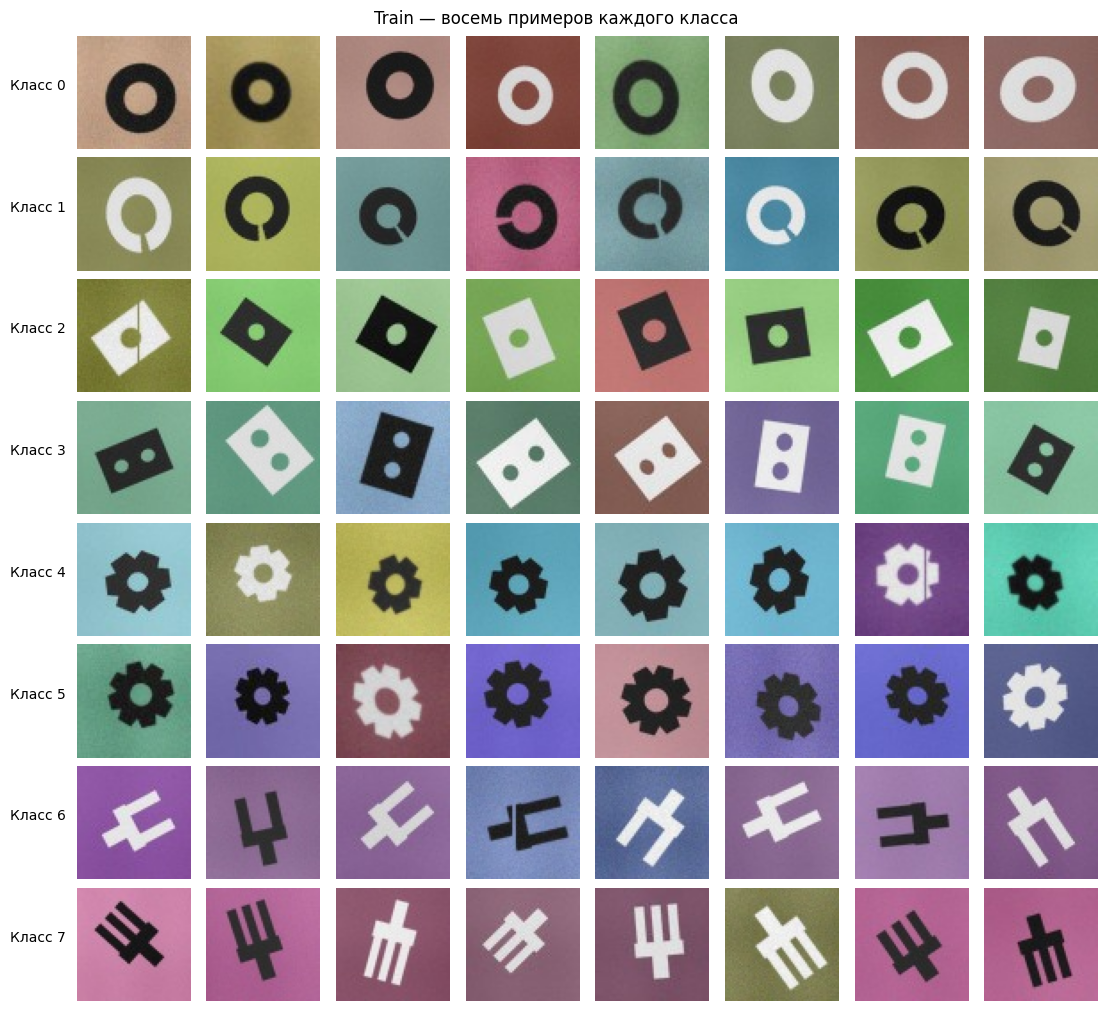

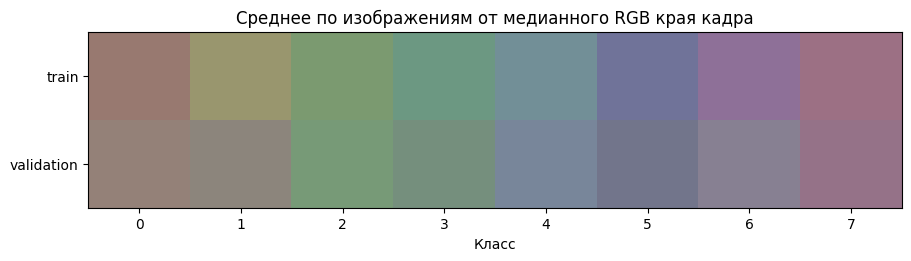

,класс,"сдвиг RGB train → validation (L2, шкала 0–255)"
0,Шайба,11.6
1,Разрезная шайба,25.6
2,Пластина с 1 отверстием,8.6
3,Пластина с 2 отверстиями,13.6
4,Шестерня с 6 зубьями,11.6
5,Шестерня с 8 зубьями,14.9
6,Вилка с 2 зубцами,18.1
7,Вилка с 3 зубцами,9.0


In [4]:
def border_color(image):
    pixels = np.asarray(image)
    border = np.concatenate((pixels[:3].reshape(-1, 3), pixels[-3:].reshape(-1, 3),
                             pixels[3:-3, :3].reshape(-1, 3), pixels[3:-3, -3:].reshape(-1, 3)))
    return tuple(map(int, np.median(border, axis=0)))


def image_audit(frame):
    hashes, colors = [], []
    for file in frame["file"]:
        with Image.open(ROOT / file) as image:
            if image.mode != "RGB" or image.size != (64, 64):
                raise ValueError(f"Ожидался RGB 64×64: {file}")
            hashes.append(hashlib.sha256(image.tobytes()).hexdigest())
            colors.append(border_color(image))
    return set(hashes), np.array(colors) / 255


train_hashes, train_bg = image_audit(train)
val_hashes, val_bg = image_audit(validation)
print(f"Точные пиксельные дубли: train {len(train) - len(train_hashes)}, "
      f"validation {len(validation) - len(val_hashes)}, между ними {len(train_hashes & val_hashes)}.")

fig, axes = plt.subplots(8, 8, figsize=(11, 10), layout="constrained")
for label, row in enumerate(axes):
    examples = train.loc[train.label.eq(label)].sample(n=len(row), random_state=PRIMARY_SEED)
    for ax, file in zip(row, examples.file):
        with Image.open(ROOT / file) as image:
            ax.imshow(image)
        ax.set(xticks=[], yticks=[])
        for spine in ax.spines.values():
            spine.set_visible(False)
    row[0].set_ylabel(f"Класс {label}", rotation=0, labelpad=28)
fig.suptitle("Train — восемь примеров каждого класса")
plt.show()


def mean_background(frame, colors):
    return pd.DataFrame(colors).groupby(frame.label).mean().to_numpy()


mean_train, mean_val = mean_background(train, train_bg), mean_background(validation, val_bg)
fig, ax = plt.subplots(figsize=(9, 2.5), layout="constrained")
ax.imshow(np.stack((mean_train, mean_val)), aspect="auto", interpolation="nearest")
ax.set(xticks=range(8), yticks=[0, 1], yticklabels=["train", "validation"], xlabel="Класс",
       title="Среднее по изображениям от медианного RGB края кадра")
plt.show()
display(pd.DataFrame({"класс": CLASS_NAMES,
                      "сдвиг RGB train → validation (L2, шкала 0–255)":
                          np.linalg.norm(mean_train - mean_val, axis=1) * 255}).round(1))

## Протокол контролируемых опытов

Короткие опыты используют 12 эпох, seed 17, один порядок батчей, batch size 64, AdamW с LR 0.002 и weight decay 0.0001. В каждом опыте берём первую эпоху с максимальным validation Macro-F1. В режиме `full` обучаемся на всех 1880 изображениях, метрику считаем по всем 480. Сравнения заранее имеют конкретного предшественника и ожидаемый эффект. Полезность изменения оцениваем по разнице Macro-F1, метрикам классов и ошибкам, которые оно должно исправлять.

| Запуск | С чем сравниваем | Гипотеза |
|---|---|---|
| `baseline` | Контроль | Стартовая CNN, `seed=17`, 24 104 параметра. В правилах указан Public Macro-F1 0.4926, здесь сравниваем с её локальным validation Macro-F1. |
| `late_pool` | `baseline` | Положение первого pooling. Если узкие щели и зубцы лучше сохраняются, меньше ошибок 0↔1, 4↔5 и 6↔7. |
| `shape` | `late_pool` | Компактная CNN с residual-блоками, BatchNorm и пространственной головой. Проверяем изменение архитектуры целиком. |
| `geometry` | `shape` | Поворот, отражение, малый сдвиг и масштаб на train должны повысить устойчивость к положению детали. |
| `gray` | `geometry` | Переход к яркости при обучении и предсказании уменьшит зависимость от оттенка фона, сохранив границы детали. |
| `polarity` | `gray` | Инверсия яркости на части train усилит устойчивость к смене светлой детали на тёмную. |
| `balanced` | `gray` | Взвешенная cross-entropy из частот train улучшит F1 редких вилок без потери общего Macro-F1. |

Два лучших коротких рецепта затем переобучаем с нуля по 36 эпох с cosine LR и повторяем на seed 27. Сохраняем короткого победителя как контроль бюджета, повторяя его на том же втором seed. Если доступны разрешённые ImageNet-веса, сравниваем с отдельным дообучением ResNet18 при 128×128 с меньшим LR backbone. Это сравнение рецептов целиком. Параметры модели считаем вместе с замороженными, продолжений обучения нет. [Воспроизводимость в PyTorch](https://docs.pytorch.org/docs/stable/notes/randomness.html) · [AMP в PyTorch](https://docs.pytorch.org/docs/main/notes/amp_examples.html)

In [5]:
@dataclass(frozen=True)
class Experiment:
    name: str
    architecture: str = "shape_cnn"
    parent: str = ""
    hypothesis: str = ""
    geometry: bool = False
    grayscale: bool = False
    invert: bool = False
    weighted: bool = False
    image_size: int = 64
    epochs: int = SHORT_EPOCHS
    seed: int = PRIMARY_SEED
    lr: float = 0.002
    backbone_lr: float = 0.0002
    cosine: bool = False
    amp: bool = False
    blur: bool = False
    contrast: bool = False
    checkpoint_loss_tiebreak: bool = False


EXPERIMENTS = [
    Experiment("baseline", "small", hypothesis="Контрольный запуск SmallCNN"),
    Experiment("late_pool", "late_pool", "baseline", "Отложить первый pooling до второй Conv"),
    Experiment("shape", parent="late_pool", hypothesis="Остаточная CNN с пространственной головой"),
    Experiment("geometry", parent="shape", hypothesis="Устойчивость к положению детали", geometry=True),
    Experiment("gray", parent="geometry", hypothesis="Устойчивость к оттенку фона", geometry=True, grayscale=True),
    Experiment("polarity", parent="gray", hypothesis="Устойчивость к полярности контраста", geometry=True,
               grayscale=True, invert=True),
    Experiment("balanced", parent="gray", hypothesis="Больше вклад редких классов в loss", geometry=True,
               grayscale=True, weighted=True),
]


def subset_for_smoke(frame, n):
    return pd.concat([part.sample(n=n, random_state=PRIMARY_SEED) for _, part in frame.groupby("label")])


train_rows = subset_for_smoke(train, 8) if RUN_MODE == "smoke" else train
val_rows = subset_for_smoke(validation, 4) if RUN_MODE == "smoke" else validation
train_frequency = train.label.value_counts().sort_index().to_numpy()


def augment_geometry(image, rng):
    if rng.random() < 0.5:
        image = ImageOps.mirror(image)
    if rng.random() >= 0.75:
        return image
    angle = math.radians(rng.uniform(-180, 180))
    scale = rng.uniform(0.90, 1.10)
    a, b = math.cos(angle) / scale, math.sin(angle) / scale
    cx, cy = image.width / 2, image.height / 2
    tx, ty = cx + rng.uniform(-3, 3), cy + rng.uniform(-3, 3)
    inverse = (a, b, cx - a * tx - b * ty, -b, a, cy + b * tx - a * ty)
    return image.transform(image.size, Image.Transform.AFFINE, inverse,
                           resample=Image.Resampling.BILINEAR, fillcolor=border_color(image))


def make_train_transform(cfg, preprocess):
    geo_rng = random.Random(cfg.seed + 1000)
    color_rng = random.Random(cfg.seed + 2000)
    robustness_rng = random.Random(cfg.seed + 3000)

    def transform(image):
        if cfg.geometry:
            image = augment_geometry(image, geo_rng)
        if cfg.invert and color_rng.random() < 0.5:
            image = ImageOps.invert(image)
        if cfg.blur and robustness_rng.random() < 0.3:
            image = image.filter(ImageFilter.GaussianBlur(robustness_rng.uniform(0.2, 0.6)))
        if cfg.contrast and robustness_rng.random() < 0.5:
            image = ImageEnhance.Contrast(image).enhance(robustness_rng.uniform(0.7, 1.3))
        return preprocess(image)

    return transform


def confusion(y, pred):
    return np.bincount(8 * np.asarray(y) + np.asarray(pred), minlength=64).reshape(8, 8)


def div_or_zero(num, den):
    return np.divide(num, den, out=np.zeros_like(num, dtype=float), where=den != 0)


def class_f1(matrix):
    return div_or_zero(2 * matrix.diagonal(), matrix.sum(axis=0) + matrix.sum(axis=1))


@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    truth, labels, confidence = [], [], []
    for images, y in loader:
        logits = model(images.to(DEVICE, non_blocking=True))
        total_loss += nn.functional.cross_entropy(logits, y.to(DEVICE), reduction="sum").item()
        prob, pred = logits.softmax(dim=1).max(dim=1)
        truth.append(y.numpy())
        labels.append(pred.cpu().numpy())
        confidence.append(prob.cpu().numpy())
    y, pred = np.concatenate(truth), np.concatenate(labels)
    return total_loss / len(y), class_f1(confusion(y, pred)).mean(), y, pred, np.concatenate(confidence)


def find_resnet_weights(filename):
    if RESNET_WEIGHTS_PATH:
        explicit = Path(RESNET_WEIGHTS_PATH)
        if explicit.is_file():
            return explicit
        if not explicit.is_dir():
            raise FileNotFoundError(f"Проверьте PARTS_RESNET_WEIGHTS_PATH: {explicit}")
        search_root = explicit
    elif ON_KAGGLE:
        search_root = Path("/kaggle/input")
    else:
        return None

    matches = sorted(path for path in search_root.rglob(filename) if path.is_file())
    if len(matches) > 1:
        raise ValueError(f"Найдено несколько копий {filename}. Укажите PARTS_RESNET_WEIGHTS_PATH: {matches}")
    if not matches and RESNET_WEIGHTS_PATH:
        raise FileNotFoundError(f"В {search_root} не найден {filename}. Можно указать путь к файлу напрямую.")
    return matches[0] if matches else None


def load_imagenet():
    try:
        from torchvision.models import ResNet18_Weights
    except ModuleNotFoundError as exc:
        if exc.name != "torchvision":
            raise
        print("ResNet18 пропущена: torchvision не установлена.")
        return None

    url = ResNet18_Weights.IMAGENET1K_V1.url
    filename = url.rsplit("/", 1)[-1]
    path = find_resnet_weights(filename)
    if path is not None:
        expected_prefix = Path(filename).stem.rsplit("-", 1)[-1]
        sha256 = hashlib.sha256(path.read_bytes()).hexdigest()
        if not sha256.startswith(expected_prefix):
            raise ValueError(f"Файл {path} не совпадает с официальным {filename}. SHA-256 начинается с {sha256[:8]}.")
        print(f"ResNet18 ImageNet-1K V1: {path}")
        return torch.load(path, map_location="cpu", weights_only=True)
    try:
        return torch.hub.load_state_dict_from_url(url, map_location="cpu", check_hash=True, weights_only=True)
    except OSError as exc:
        print(f"ResNet18 пропущена: веса недоступны. Подключите {filename} через Input. {exc}")
        return None


def optimizer_for(model, cfg):
    if cfg.architecture == "resnet18":
        groups = [{"params": [p for name, p in model.named_parameters() if not name.startswith("fc.")],
                   "lr": cfg.backbone_lr}, {"params": model.fc.parameters(), "lr": cfg.lr}]
        return torch.optim.AdamW(groups, weight_decay=0.0001)
    return torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=0.0001)

In [6]:
def train_experiment(cfg, imagenet_state=None):
    if not 1 <= cfg.epochs <= 40 or not 1 <= cfg.image_size <= 128:
        raise ValueError("Лимиты запуска: до 40 эпох и до 128×128 на входе")
    if RUN_MODE == "smoke":
        cfg = replace(cfg, epochs=1, amp=False)
    random.seed(cfg.seed)
    np.random.seed(cfg.seed)
    torch.manual_seed(cfg.seed)
    model = inference.create_model(cfg.architecture, imagenet_state).to(DEVICE)
    n_params = sum(param.numel() for param in model.parameters())
    if n_params > 12_000_000:
        raise ValueError(f"Модель содержит {n_params:,} параметров при лимите 12 млн")

    preprocess = partial(inference.image_to_tensor, architecture=cfg.architecture,
                         image_size=cfg.image_size, grayscale=cfg.grayscale)
    train_data = inference.PartsDataset(ROOT, train_rows, make_train_transform(cfg, preprocess))
    val_data = inference.PartsDataset(ROOT, val_rows, preprocess)
    loader_args = {"batch_size": 64, "num_workers": 0, "pin_memory": DEVICE.type == "cuda"}
    train_loader = DataLoader(train_data, shuffle=True, generator=torch.Generator().manual_seed(cfg.seed), **loader_args)
    val_loader = DataLoader(val_data, shuffle=False, **loader_args)

    class_weights = None
    if cfg.weighted:
        inv_sqrt = 1 / np.sqrt(train_frequency)
        class_weights = torch.tensor(inv_sqrt / inv_sqrt.mean(), device=DEVICE, dtype=torch.float32)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = optimizer_for(model, cfg)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg.epochs) if cfg.cosine else None
    amp = cfg.amp and DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp)

    history, best_f1 = [], -1.0
    best_val_loss = float("inf")
    start = time.perf_counter()
    for epoch in range(1, cfg.epochs + 1):
        model.train()
        loss_sum = torch.zeros((), device=DEVICE)
        loss_weight = torch.zeros((), device=DEVICE)
        for x, y in train_loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp):
                loss = criterion(model(x), y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            batch_weight = class_weights[y].sum() if cfg.weighted else y.numel()
            loss_sum += loss.detach() * batch_weight
            loss_weight += batch_weight

        val_loss, f1, y, pred, confidence = evaluate(model, val_loader)
        if not math.isfinite(val_loss):
            raise RuntimeError(f"Нечисловой validation loss в {cfg.name}, эпоха {epoch}")
        history.append({"epoch": epoch, "train_loss": (loss_sum / loss_weight).item(), "val_loss": val_loss,
                        "val_macro_f1": f1, "val_accuracy": (y == pred).mean(),
                        "head_lr": optimizer.param_groups[-1]["lr"], "seconds": time.perf_counter() - start})
        if f1 > best_f1 or (cfg.checkpoint_loss_tiebreak and f1 == best_f1 and val_loss < best_val_loss):
            best_val_loss = val_loss
            best_f1, best_epoch = f1, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            best_predictions = val_data.rows[["id", "file", "label"]].assign(prediction=pred, confidence=confidence)
        if scheduler is not None:
            scheduler.step()
        if epoch == 1 or epoch % 6 == 0 or epoch == cfg.epochs:
            print(f"{cfg.name:22s} seed {cfg.seed} | {epoch:02d}/{cfg.epochs} | val Macro-F1 {f1:.4f}", flush=True)

    run_dir = OUT_DIR / "experiments" / f"{cfg.name}-seed{cfg.seed}"
    run_dir.mkdir(parents=True, exist_ok=True)
    torch.save(best_state, run_dir / "model.pt")
    pd.DataFrame(history).to_csv(run_dir / "history.csv", index=False)
    best_predictions.to_csv(run_dir / "validation_predictions.csv", index=False)
    result = {**asdict(cfg), "trained_with_amp": amp, "parameters": n_params,
              "best_epoch": best_epoch, "val_macro_f1": best_f1, "val_loss": best_val_loss, "seconds": history[-1]["seconds"],
              "class_weights": class_weights.cpu().tolist() if cfg.weighted else None,
              "device": torch.cuda.get_device_name(DEVICE) if DEVICE.type == "cuda" else platform.processor() or "CPU",
              "weights_source": "torchvision ResNet18_Weights.IMAGENET1K_V1" if imagenet_state is not None else "random"}
    (run_dir / "metrics.json").write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")
    return {**result, "directory": run_dir}


def read_predictions(run):
    return pd.read_csv(run["directory"] / "validation_predictions.csv", dtype={"id": str})


def stratified_paired_interval(parent, child, seed=1717, samples=500):
    a, b = read_predictions(parent), read_predictions(child)
    if not a[["id", "label"]].equals(b[["id", "label"]]):
        raise ValueError("Парное сравнение требует одинакового validation")
    y, left, right = a.label.to_numpy(), a.prediction.to_numpy(), b.prediction.to_numpy()
    indices = [np.flatnonzero(y == label) for label in range(8)]
    rng = np.random.default_rng(seed)
    changes = []
    for _ in range(samples):
        take = np.concatenate([rng.choice(part, size=len(part), replace=True) for part in indices])
        changes.append(class_f1(confusion(y[take], right[take])).mean() -
                       class_f1(confusion(y[take], left[take])).mean())
    return np.quantile(changes, [0.025, 0.975]).round(4).tolist()

In [7]:
if RUN_MODE != "eda" and RUN_ROUND in (0, 1):
    if ON_KAGGLE and RUN_MODE == "full" and DEVICE.type != "cuda":
        raise RuntimeError("Для полного прогона на Kaggle включите GPU T4 x2 в настройках ноутбука")
    imagenet_state = load_imagenet() if RUN_MODE == "full" and RUN_RESNET else None
    short_runs = {cfg.name: train_experiment(cfg) for cfg in EXPERIMENTS}
    comparison_rows = []
    for run in short_runs.values():
        row = {key: run[key] for key in ("name", "parent", "hypothesis", "seed", "epochs", "val_macro_f1",
                                        "best_epoch", "parameters", "seconds")}
        if run["parent"]:
            parent = short_runs[run["parent"]]
            delta = run["val_macro_f1"] - parent["val_macro_f1"]
            low, high = stratified_paired_interval(parent, run)
            decision = "принять для отбора" if delta > 0 else "отклонить по Macro-F1"
            if low <= 0 <= high:
                decision += " · эффект неустойчив на этой выборке"
            row.update(delta_macro_f1=delta, ci_lower=low, ci_upper=high, decision=decision)
        comparison_rows.append(row)
    comparisons = pd.DataFrame(comparison_rows)
    comparisons.to_csv(OUT_DIR / "comparisons.csv", index=False)
    display(comparisons.round(4))

## Повторы и выбор кандидатов

Парный bootstrap сохраняет число примеров каждого класса и оценивает чувствительность разницы к составу validation при фиксированных моделях. При полностью правильных ответах обеих моделей интервал [0, 0] вырожден и не оценивает риск ошибки на новых изображениях. Повторные seed оценивают другую составляющую неопределённости — изменчивость обучения.

Короткие эксперименты используются для первичного отбора. Длинные рецепты сравниваются при одинаковом бюджете. Финальное решение по всей работе приведено в заключительном разделе.

In [8]:
if RUN_MODE != "eda" and RUN_ROUND in (0, 1):
    ordered = sorted(EXPERIMENTS, key=lambda cfg: (-short_runs[cfg.name]["val_macro_f1"],
                                                   short_runs[cfg.name]["parameters"], cfg.name))
    short_winner = ordered[0]
    long_configs = [replace(cfg, name=f"{cfg.name}_long", parent=cfg.name, epochs=LONG_EPOCHS, cosine=True,
                            amp=USE_AMP, hypothesis="Длинный бюджет с cosine LR и CUDA AMP") for cfg in ordered[:2]]
    if imagenet_state is not None:
        long_configs.append(replace(short_winner, name="resnet18", parent=short_winner.name, architecture="resnet18",
                                    image_size=128, lr=0.001, backbone_lr=0.0001, epochs=LONG_EPOCHS,
                                    cosine=True, amp=USE_AMP, geometry=True,
                                    hypothesis="Разрешённое ImageNet-предобучение и дообучение всей ResNet18"))

    repeat = train_experiment(replace(short_winner, seed=REPEAT_SEED))
    contenders = {short_winner.name: [short_runs[short_winner.name], repeat]}
    for cfg in long_configs:
        state = imagenet_state if cfg.architecture == "resnet18" else None
        contenders[cfg.name] = [train_experiment(replace(cfg, seed=seed), state) for seed in (PRIMARY_SEED, REPEAT_SEED)]
    del imagenet_state

    ranking = pd.DataFrame([
        {"recipe": name, "mean_macro_f1": np.mean([run["val_macro_f1"] for run in runs]),
         "min_macro_f1": min(run["val_macro_f1"] for run in runs),
         f"seed_{PRIMARY_SEED}_macro_f1": runs[0]["val_macro_f1"],
         f"seed_{REPEAT_SEED}_macro_f1": runs[1]["val_macro_f1"],
         "parameters": runs[0]["parameters"], f"epoch_seed_{PRIMARY_SEED}": runs[0]["best_epoch"],
         "mean_seconds": np.mean([run["seconds"] for run in runs])}
        for name, runs in contenders.items()
    ]).sort_values(["mean_macro_f1", "min_macro_f1", "parameters", "recipe"], ascending=[False, False, True, True])
    primary = contenders[ranking.iloc[0]["recipe"]][0]
    primary_val = read_predictions(primary)
    selected = [primary]
    recipe_keys = ["architecture", "geometry", "grayscale", "invert", "weighted", "image_size"]
    for row in ranking.iloc[1:].itertuples(index=False):
        candidate = contenders[row.recipe][0]
        alt = read_predictions(candidate)
        comparable = (ranking.iloc[0]["mean_macro_f1"] - row.mean_macro_f1 <= SECOND_CANDIDATE_GAP and
                      primary["val_macro_f1"] - candidate["val_macro_f1"] <= SECOND_CANDIDATE_GAP)
        different = any(candidate[key] != primary[key] for key in recipe_keys)
        fixes = (primary_val.prediction.ne(primary_val.label) & alt.prediction.eq(alt.label)).sum()
        if comparable and different and fixes:
            selected.append(candidate)
            break

    ranking["selected"] = ranking.recipe.isin([run["name"] for run in selected])
    ranking.to_csv(OUT_DIR / "finalist_comparison.csv", index=False)
    all_runs = {run["directory"]: run for run in [*short_runs.values(), *(run for group in contenders.values() for run in group)]}
    pd.DataFrame([{k: v for k, v in run.items() if k != "directory"} for run in all_runs.values()]).to_csv(
        OUT_DIR / "all_experiments.csv", index=False)
    display(ranking.round(4))
    print("Выбранные рецепты:", ", ".join(run["name"] for run in selected))

## Кривые обучения и ошибки на validation

Сравниваем baseline с основным кандидатом. По кривым читаем момент выбора checkpoint, динамику train loss и validation loss. Loss разных запусков напрямую сопоставима при одинаковом взвешивании. Матрицы даны в абсолютных количествах. Для каждого класса выводим precision, recall и F1. Пары 0↔1, 2↔3, 4↔5 и 6↔7 соответствуют похожим формам с различающейся мелкой деталью.

In [9]:
def metrics_by_class(matrix):
    return pd.DataFrame({"class": CLASS_NAMES, "support": matrix.sum(axis=1),
                         "precision": div_or_zero(matrix.diagonal(), matrix.sum(axis=0)),
                         "recall": div_or_zero(matrix.diagonal(), matrix.sum(axis=1)), "f1": class_f1(matrix)})


PAIR_DETAILS = {
    (0, 1): "узкий разрез шайбы",
    (2, 3): "число отверстий в пластине",
    (4, 5): "число зубьев шестерни",
    (6, 7): "число зубцов вилки",
}


def show_pair_errors(matrix):
    return {detail: int(matrix[i, j] + matrix[j, i]) for (i, j), detail in PAIR_DETAILS.items()}


def show_learning_curves(runs):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
    for run in runs:
        history = pd.read_csv(run["directory"] / "history.csv")
        line, = axes[0].plot(history.epoch, history.val_macro_f1, marker=".", label=run["name"])
        axes[0].scatter(run["best_epoch"], run["val_macro_f1"], color=line.get_color(), marker="*", s=100)
        axes[1].plot(history.epoch, history.train_loss, color=line.get_color(), label=f'{run["name"]} train')
        axes[1].plot(history.epoch, history.val_loss, color=line.get_color(), linestyle="--", label=f'{run["name"]} val')
    axes[0].set(xlabel="Эпоха", ylabel="Validation Macro-F1", title="Звезда показывает выбранную эпоху")
    axes[1].set(xlabel="Эпоха", ylabel="Cross-entropy", title="Динамика loss")
    for ax in axes:
        ax.grid(alpha=0.25)
        ax.legend()
    plt.show()


def show_matrices(runs, matrices):
    fig, axes = plt.subplots(1, len(runs), figsize=(5 * len(runs), 4.4), squeeze=False, layout="constrained")
    maximum = max(matrix.max() for matrix in matrices)
    for ax, run, matrix in zip(axes[0], runs, matrices):
        ax.imshow(matrix, cmap="Blues", vmin=0, vmax=maximum)
        for i, j in np.ndindex(matrix.shape):
            ax.text(j, i, str(matrix[i, j]), ha="center", va="center",
                    color="white" if matrix[i, j] > 0.55 * maximum else "#172b4d")
        ax.set(title=run["name"], xlabel="Предсказанный класс", ylabel="Истинный класс",
               xticks=range(8), yticks=range(8))
    plt.show()


def show_errors(frame, baseline_frame, matrix):
    wrong = frame.loc[frame.label.ne(frame.prediction)].copy()
    wrong["baseline_prediction"] = baseline_frame.loc[wrong.index, "prediction"].to_numpy()
    if wrong.empty:
        print("У выбранной модели нет ошибок на этом validation.")
        return
    mistakes = matrix.copy()
    np.fill_diagonal(mistakes, 0)
    pairs = sorted(((int(mistakes[i, j]), i, j) for i, j in np.ndindex(mistakes.shape) if mistakes[i, j]),
                   reverse=True)
    for count, label, pred in pairs[:4]:
        cue = PAIR_DETAILS.get(tuple(sorted((label, pred))))
        message = f"{label} → {pred}, {count} из {matrix[label].sum()} для класса «{CLASS_NAMES[label]}»."
        if cue:
            message += f" Признак для проверки на изображениях этой пары — {cue}."
        print(message)

    by_confidence = wrong.sort_values("confidence", ascending=False)
    examples = pd.concat([by_confidence.groupby(["label", "prediction"], sort=False).head(1),
                          by_confidence]).drop_duplicates("id").head(8)
    fig, axes = plt.subplots(2, 4, figsize=(11, 5.8), layout="constrained")
    for ax in axes.flat:
        ax.axis("off")
    contrast = []
    for ax, row in zip(axes.flat, examples.itertuples()):
        with Image.open(ROOT / row.file) as image:
            ax.imshow(image)
            lightness = np.asarray(ImageOps.grayscale(image)).astype(float)
            low, high = np.quantile(lightness, [0.05, 0.95])
            contrast.append(high - low)
        ax.set_title(f"{row.label} → {row.prediction}\nscore {row.confidence:.2f} · baseline {row.baseline_prediction}")
    plt.show()
    display(examples[["id", "label", "prediction", "confidence", "baseline_prediction"]].assign(
        яркость_P95_минус_P05=np.round(contrast, 1)))


if RUN_MODE != "eda" and RUN_ROUND in (0, 1):
    baseline_run = short_runs["baseline"]
    baseline_frame = read_predictions(baseline_run)
    baseline_matrix = confusion(baseline_frame.label, baseline_frame.prediction)
    main_matrix = confusion(primary_val.label, primary_val.prediction)
    show_learning_curves([baseline_run, primary] if primary["directory"] != baseline_run["directory"] else [primary])
    show_matrices([baseline_run, primary], [baseline_matrix, main_matrix])
    results_by_class = metrics_by_class(main_matrix).assign(baseline_f1=class_f1(baseline_matrix))
    results_by_class["delta_f1"] = results_by_class["f1"] - results_by_class["baseline_f1"]
    results_by_class.to_csv(OUT_DIR / "per_class.csv", index_label="label")
    display(results_by_class.round(4))

    focused_checks = []
    for name in ("baseline", "late_pool", "shape", "geometry", "gray", "polarity", "balanced"):
        frame = read_predictions(short_runs[name])
        matrix = confusion(frame.label, frame.prediction)
        focused_checks.append({"run": name, **show_pair_errors(matrix),
                               "mean_f1_forks_6_7": class_f1(matrix)[6:].mean()})
    display(pd.DataFrame(focused_checks).round(4))

    before = baseline_frame.prediction.eq(baseline_frame.label)
    after = primary_val.prediction.eq(primary_val.label)
    print(f"По сравнению с baseline исправлено {(~before & after).sum()} ответов, "
          f"потеряно {(before & ~after).sum()} правильных ответов.")
    show_errors(primary_val, baseline_frame, main_matrix)

### Интерпретация ошибок

Матрица ошибок показывает, какие классы модель систематически смешивает. Для оценки изменения рецепта сравниваем результаты на всём validation. Галерея позволяет сформулировать гипотезу о причине ошибки, которую затем проверяем отдельным опытом. Уверенность softmax используется для сортировки примеров. Она не заменяет проверку истинной метки.

У финальной модели на исходном validation ошибок нет. Для содержательного анализа ниже приведены ошибки стартовой CNN и результаты контролируемых искажений. Эти искажения сохраняют метку, но образуют зависимые варианты тех же изображений.

## Предсказание и проверка комплекта

Только после выбора checkpoint формируем CSV. Предсказание для всех 960 ID выполняется на CPU в FP32. Затем отдельный процесс заново читает `model.pt` и создаёт CSV. Для передаваемого файла проверяем побайтовое совпадение. Один каталог соответствует одной посылке.

In [10]:
def package_versions():
    import IPython
    import PIL
    import matplotlib

    versions = {"torch": str(torch.__version__), "numpy": np.__version__, "pandas": pd.__version__,
                "Pillow": PIL.__version__, "matplotlib": matplotlib.__version__, "ipython": IPython.__version__}
    for name in ("torchvision", "ipykernel", "nbconvert"):
        try:
            version = metadata.version(name)
        except metadata.PackageNotFoundError:
            continue
        if version:
            versions[name] = version
    return versions


def export_submission(run, rank):
    folder = OUT_DIR / (f"smoke_check_{rank}" if RUN_MODE == "smoke" else f"final_{rank}")
    folder.mkdir(parents=True, exist_ok=True)
    for filename in ("model.pt", "history.csv", "validation_predictions.csv", "metrics.json"):
        shutil.copyfile(run["directory"] / filename, folder / filename)
    shutil.copyfile(PREDICT_PATH, folder / "predict.py")
    settings = {key: run[key] for key in ("architecture", "image_size", "grayscale")}
    settings["dataset_version"] = "parts-v2"
    config_file = folder / "model_config.json"
    config_file.write_text(json.dumps(settings, indent=2), encoding="utf-8")

    output_name = "submission_smoke.csv" if RUN_MODE == "smoke" else "submission.csv"
    submit = folder / output_name
    predict_args = (ROOT, folder / "model.pt", config_file)
    start = time.perf_counter()
    submission = inference.predict(*predict_args, output=submit)
    seconds = time.perf_counter() - start
    reproduced = folder / "reproduced.csv"
    command = [sys.executable, str(folder / "predict.py"), "--data", str(ROOT),
               "--weights", str(folder / "model.pt"), "--settings", str(config_file), "--output", str(reproduced)]
    subprocess.run(command, check=True)
    contents = submit.read_bytes()
    if reproduced.read_bytes() != contents or len(submission) != 960 or not submission.id.is_unique:
        raise RuntimeError("CSV из сохранённых весов не совпал")
    reproduced.unlink()
    sha256 = hashlib.sha256(contents).hexdigest()
    versions = package_versions()
    versions_text = "\n".join(f"{name}=={version}" for name, version in versions.items())
    requirements = "\n".join(f"{name}=={version.split('+')[0]}" for name, version in versions.items())
    (folder / "requirements.txt").write_text(requirements + "\n", encoding="utf-8")

    mode_note = "ТЕХНИЧЕСКИЙ ПРОГОН: этот CSV не сдаётся.\n" if RUN_MODE == "smoke" else ""
    readme = f"""{mode_note}Детали на конвейере · parts-v2
Название команды: [заполнить]
Имена, группы, аккаунты Kaggle, вклад участников: [заполнить]
Kaggle ID посылки: [заполнить после загрузки]

Рецепт: {run['name']} | seed: {run['seed']} | данные: parts-v2
Архитектура: {run['architecture']} | все параметры: {run['parameters']}
Эпох: {run['epochs']} | checkpoint: {run['best_epoch']} | validation Macro-F1: {run['val_macro_f1']:.6f}
Изображение: {run['image_size']}×{run['image_size']} | grayscale: {run['grayscale']}
На train: geometry={run['geometry']}, invert={run['invert']}, weighted={run['weighted']}, blur={run['blur']}, contrast={run['contrast']}.
Checkpoint loss tiebreak: {run['checkpoint_loss_tiebreak']}.
Точные параметры преобразований и таблица опытов находятся в solution.ipynb.
Остальная конфигурация обучения находится в metrics.json.
Предобучение: {run['weights_source']}
Обучение: {run['device']} | AMP: {run['trained_with_amp']} | время с валидацией: {run['seconds']:.2f} сек.
Предсказание всех 960 изображений: CPU FP32, {seconds:.2f} сек. с чтением и записью файлов.

Python {platform.python_version()} | CUDA torch build: {torch.version.cuda}
Фактические версии:
{versions_text}

Обучение с нуля: загрузить solution.ipynb на Kaggle, подключить исходный parts-v2,
выбрать GPU T4 x2 и выполнить Save & Run All с RUN_MODE=full, RUN_ROUND={RUN_ROUND}.
Локальный запуск: python -m jupyter nbconvert --to notebook --execute --ExecutePreprocessor.timeout=-1 solution.ipynb
с PARTS_RUN_MODE=full и PARTS_DATA_ROOT, указывающей на каталог с CSV и images/.
При установке зависимостей локально выберите совместимые сборки torch и torchvision для своего устройства.
Для офлайн-обучения ResNet18 подключите официальный resnet18-f37072fd.pth из torchvision
или задайте PARTS_RESNET_WEIGHTS_PATH с путём к этому файлу.
Для отдельного воспроизведения CSV из этого каталога выполните:
python predict.py --data /path/to/parts-v2 --weights model.pt --settings model_config.json --output reproduced.csv

Файл {output_name} | SHA-256 {sha256}
Проверка: reproduced.csv побайтово совпал с экспортом.
Источники: baseline.py и predict_baseline.py Семенова Д. П., практики 03 и 04–05.
Использованы исходная SmallCNN и протокол валидации. Остаточные блоки и поздний pooling
адаптированы к 64×64. Таблицы экспериментов, аугментации и экспорт реализованы здесь.
"""
    (folder / "README.txt").write_text(readme, encoding="utf-8")
    return {"path": str(submit), "recipe": run["name"], "seed": run["seed"], "epoch": run["best_epoch"],
            "val_macro_f1": run["val_macro_f1"], "parameters": run["parameters"], "train_eval_seconds": run["seconds"],
            "cpu_export_seconds": seconds, "csv_sha256": sha256}


if RUN_MODE != "eda" and RUN_ROUND in (0, 1):
    exported = pd.DataFrame([export_submission(run, i) for i, run in enumerate(selected, 1)])
    exported.to_csv(OUT_DIR / "exported_submissions.csv", index=False)
    display(exported)
    delta = primary["val_macro_f1"] - short_runs["baseline"]["val_macro_f1"]
    print(f"Основной рецепт выбран по среднему Macro-F1 на двух seed ({ranking.iloc[0].mean_macro_f1:.4f}). "
          f"На seed {PRIMARY_SEED} разница с исходной CNN {delta:+.4f}.")
    for row in exported.itertuples(index=False):
        print(f"{row.recipe}, seed {row.seed}, эпоха {row.epoch}: validation Macro-F1 {row.val_macro_f1:.4f}; "
              f"{row.parameters:,} параметров, {row.train_eval_seconds:.1f} сек. обучения с валидацией, "
              f"{row.cpu_export_seconds:.1f} сек. на 960 предсказаний и запись CSV.")

### Состав сдаваемого решения

Для итогового решения нужны выполненный `solution.ipynb`, `model.pt`, `predict.py`, `model_config.json`, `submission.csv`, `history.csv`, `requirements.txt` и `README.txt`. Модель сохранена как state_dict. Скрипт предсказания создаёт CSV из сохранённых весов без обучения и загрузки предобученных моделей. При экспорте проверяется побайтовое совпадение CSV с результатом отдельного процесса.

В README перед сдачей заполняются имя, группа, аккаунт Kaggle, вклад участников и ID финальной посылки. Требования преподавателя включают минимум четыре осмысленных сравнения, кривые обучения, метрики по классам, разбор ошибок и оценку вычислительной стоимости. Эти материалы собраны в заключительном разделе. Блок качества оценивается по Private Macro-F1 и месту после завершения соревнования.

## Отбор преобразований и режима обучения

В первой группе переход от RGB к яркости увеличил Macro-F1 с 0.6699 до 0.9750. Фон содержит информацию о классе, и её связь с меткой меняется между train и validation. Нормализация и преобразования яркости рассматриваются как способы уменьшить зависимость от фона.

Поздний pooling сам по себе не дал подтверждённого прироста. Замена архитектуры целиком улучшила метрику, но этот опыт не позволяет приписать эффект конкретно residual-блокам, BatchNorm или пространственной голове. Взвешенная loss ухудшила короткий запуск.

Длинные рецепты достигли потолка validation Macro-F1. Для последующих сравнений дополнительно измерялись cross-entropy и устойчивость к фиксированным искажениям validation. Повторы на seed 17/27/37 позволяют оценить изменчивость обучения. Validation многократно использовался для выбора гипотез и checkpoint, поэтому эти результаты являются оценкой разработки и могут быть оптимистичными для новых данных.

In [11]:
# Диагностика фона, центры вычисляются только по train.
def audit_border_features(frame):
    colors = []
    for file in frame.file:
        with Image.open(ROOT / file) as image:
            a = np.asarray(image)
            edge = np.concatenate([a[:3].reshape(-1, 3), a[-3:].reshape(-1, 3),
                                   a[:, :3].reshape(-1, 3), a[:, -3:].reshape(-1, 3)])
            colors.append(np.median(edge, axis=0))
    return np.array(colors)

train_border = audit_border_features(train)
val_border = audit_border_features(validation)
centers = np.stack([train_border[train.label.to_numpy() == c].mean(0) for c in range(8)])
for split, features, labels in [('train', train_border, train.label), ('validation', val_border, validation.label)]:
    predictions = ((features[:, None] - centers) ** 2).sum(2).argmin(1)
    print(split, 'background accuracy', float((predictions == labels.to_numpy()).mean()))


train background accuracy 0.5675531914893617
validation background accuracy 0.40208333333333335


In [12]:
def robustness_scores(run):
    model = inference.create_model(run['architecture']).to(DEVICE)
    model.load_state_dict(torch.load(run['directory'] / 'model.pt', map_location=DEVICE, weights_only=True))
    preprocess = partial(inference.image_to_tensor, architecture=run['architecture'],
                         image_size=run['image_size'], grayscale=run['grayscale'])
    variants = {
        'clean': lambda image: image,
        'blur_05': lambda image: image.filter(ImageFilter.GaussianBlur(0.5)),
        'contrast_07': lambda image: ImageEnhance.Contrast(image).enhance(0.7),
        'inverted': ImageOps.invert,
    }
    results = []
    for variant, change in variants.items():
        transform = lambda image: preprocess(change(image))
        dataset = inference.PartsDataset(ROOT, val_rows, transform)
        loss, f1, y, pred, confidence = evaluate(model, DataLoader(dataset, batch_size=64, shuffle=False))
        results.append(dict(recipe=run['name'], seed=run['seed'], variant=variant, macro_f1=f1, loss=loss))
        val_rows[['id', 'file', 'label']].assign(prediction=pred, confidence=confidence).to_csv(
            run['directory'] / f'validation_{variant}.csv', index=False)
    return results

if RUN_MODE != 'eda' and RUN_ROUND in (0, 2):
    OUT_DIR = BASE_OUT_DIR / 'round2'
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    control = Experiment('r2_control', geometry=True, grayscale=True, epochs=36, cosine=True, amp=USE_AMP)
    recipes = [control,
               replace(control, name='r2_constant_lr', cosine=False, parent=control.name),
               replace(control, name='r2_invert', invert=True, parent=control.name),
               replace(control, name='r2_blur', blur=True, parent=control.name),
               replace(control, name='r2_contrast', contrast=True, parent=control.name)]
    round2_runs, diagnostics = [], []
    for cfg in recipes:
        for seed in (17, 27, 37):
            run = train_experiment(replace(cfg, seed=seed))
            round2_runs.append(run)
            diagnostics.extend(robustness_scores(run))
    diagnostic_table = pd.DataFrame(diagnostics)
    diagnostic_table.to_csv(OUT_DIR / 'robustness.csv', index=False)
    table = pd.DataFrame([{k: v for k, v in run.items() if k != 'directory'} for run in round2_runs])
    table.to_csv(OUT_DIR / 'all_experiments.csv', index=False)
    paired = table.pivot(index='seed', columns='name', values='val_macro_f1')
    display(paired)
    display(paired.subtract(paired['r2_control'], axis=0))
    ranking2 = table.groupby('name').agg(mean_f1=('val_macro_f1', 'mean'),
        min_f1=('val_macro_f1', 'min'), parameters=('parameters', 'first'), seconds=('seconds', 'mean'))
    worst = diagnostic_table.query("variant != 'clean'").groupby(['recipe', 'seed']).macro_f1.min()
    ranking2['stress_f1'] = worst.groupby('recipe').mean()
    ranking2 = ranking2.reset_index().sort_values(
        ['mean_f1', 'min_f1', 'stress_f1', 'parameters', 'name'], ascending=[False, False, False, True, True])
    ranking2.to_csv(OUT_DIR / 'ranking.csv', index=False)
    display(ranking2)
    shortlist = ranking2.loc[ranking2.mean_f1 >= ranking2.iloc[0].mean_f1 - 0.005].head(2)
    chosen = [next(run for run in round2_runs if run['name'] == name and run['seed'] == 17)
              for name in shortlist.name]
    round2_exports = pd.DataFrame([export_submission(run, i) for i, run in enumerate(chosen, 1)])
    round2_exports.to_csv(OUT_DIR / 'exported_submissions.csv', index=False)
    display(round2_exports)
    for run in chosen:
        frame = read_predictions(run)
        matrix = confusion(frame.label, frame.prediction)
        display(metrics_by_class(matrix))
        show_learning_curves([run])
        show_matrices([run], [matrix])
        show_errors(frame, read_predictions(next(r for r in round2_runs if r['name'] == 'r2_control' and r['seed'] == 17)), matrix)


### Результаты преобразований

Инверсия сохранила Macro-F1 1.0 на трёх seed и повысила средний худший стресс-F1 с 0.97914 до 0.99309. Изменение контраста при обучении дало стресс-F1 0.99583, но чистый Macro-F1 снизился до 0.99931. Blur дал 0.95805 на худших искажениях. Поэтому инверсия включена в контрольный рецепт последующей группы.

При уменьшении контраста у модели с инверсией осталось 1, 6 и 3 ошибки на трёх seed. Это мотивировало отдельную проверку нормализации входа.

## Архитектура, входная нормализация и checkpoint

В третьей группе сравниваются шесть рецептов на seed 17/27/37. Все используют grayscale, геометрические аугментации и случайную инверсию, AdamW, batch size 64, cosine LR и 36 эпох. Веса обучаются только на train. Каждая модель выбирается по максимальному validation Macro-F1. В вариантах с дополнительным критерием равенство F1 разрешается по минимальной validation cross-entropy.

| Рецепт | Контроль | Изменение и гипотеза |
|---|---|---|
| r3_first | Базовый рецепт | Первая эпоха с максимальным F1 |
| r3_loss | r3_first | Минимальная loss при равном F1 может улучшить уверенность правильных решений |
| r3_normalized | r3_loss | Нормализация изображения уменьшит зависимость от контраста |
| r3_wide | r3_loss | Удвоение каналов увеличит ёмкость признаков формы |
| r3_wide_aa | r3_wide | Сглаживание перед subsampling уменьшит чувствительность к смещению границ |
| r3_wide_aa_normalized | r3_wide_aa | Проверка нормализации в более широкой архитектуре |

Нормализация вычитает среднюю яркость изображения и делит результат на RMS отклонения с нижней границей 0.05. Статистики вычисляются для текущего изображения. Одно преобразование используется при обучении, валидации и предсказании.

Ранжирование использует средний чистый F1, худший чистый F1, средний худший стресс-F1, среднюю clean loss, число параметров и имя. Стресс-набор состоит из Gaussian blur 0.5, contrast 0.7 и инверсии. Его результаты зависимы от исходного validation. Для финальных весов заранее фиксирован seed 17.

Идеи ширины residual-сети и фильтрации перед уменьшением разрешения опираются на опубликованные работы. Реализации здесь адаптированы к изображениям 64×64. [Wide Residual Networks](https://arxiv.org/abs/1605.07146) · [Making Convolutional Networks Shift-Invariant Again](https://arxiv.org/abs/1904.11486)

In [13]:
if RUN_MODE != 'eda' and RUN_ROUND in (0, 3):
    if ON_KAGGLE and RUN_MODE == 'full' and DEVICE.type != 'cuda':
        raise RuntimeError('Включите GPU для полного запуска')
    OUT_DIR = BASE_OUT_DIR / 'round3'
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    control3 = Experiment('r3_first', geometry=True, grayscale=True, invert=True,
                          epochs=36, cosine=True, amp=USE_AMP)
    loss3 = replace(control3, name='r3_loss', parent='r3_first', checkpoint_loss_tiebreak=True)
    recipes3 = [control3, loss3,
                replace(loss3, name='r3_normalized', parent='r3_loss', architecture='shape_normalized'),
                replace(loss3, name='r3_wide', parent='r3_loss', architecture='shape_wide'),
                replace(loss3, name='r3_wide_aa', parent='r3_wide', architecture='shape_wide_aa'),
                replace(loss3, name='r3_wide_aa_normalized', parent='r3_wide_aa', architecture='shape_wide_aa_normalized')]
    runs3, diagnostics3 = [], []
    for cfg in recipes3:
        for seed in (17, 27, 37):
            run = train_experiment(replace(cfg, seed=seed))
            runs3.append(run)
            diagnostics3.extend(robustness_scores(run))
            pd.DataFrame([{k: v for k, v in r.items() if k != 'directory'} for r in runs3]).to_csv(
                OUT_DIR / 'all_experiments.csv', index=False)
            pd.DataFrame(diagnostics3).to_csv(OUT_DIR / 'robustness.csv', index=False)
    table3 = pd.DataFrame(runs3)
    diag3 = pd.DataFrame(diagnostics3)
    comparisons3 = []
    for cfg in recipes3[1:]:
        for seed in (17, 27, 37):
            child = next(r for r in runs3 if r['name'] == cfg.name and r['seed'] == seed)
            parent = next(r for r in runs3 if r['name'] == cfg.parent and r['seed'] == seed)
            low, high = stratified_paired_interval(parent, child)
            comparisons3.append(dict(recipe=cfg.name, parent=cfg.parent, seed=seed,
                delta_f1=child['val_macro_f1'] - parent['val_macro_f1'],
                delta_loss=child['val_loss'] - parent['val_loss'], ci_low=low, ci_high=high))
    comparisons3 = pd.DataFrame(comparisons3)
    comparisons3.to_csv(OUT_DIR / 'comparisons.csv', index=False)
    display(comparisons3)
    rank3 = table3.groupby('name').agg(mean_f1=('val_macro_f1', 'mean'), min_f1=('val_macro_f1', 'min'),
        mean_loss=('val_loss', 'mean'), parameters=('parameters', 'first'), seconds=('seconds', 'mean'))
    worst3 = diag3.query("variant != 'clean'").groupby(['recipe', 'seed']).macro_f1.min()
    rank3['stress_f1'] = worst3.groupby('recipe').mean()
    rank3 = rank3.reset_index().sort_values(['mean_f1', 'min_f1', 'stress_f1', 'mean_loss', 'parameters', 'name'],
        ascending=[False, False, False, True, True, True])
    display(rank3)
    rank3.to_csv(OUT_DIR / 'ranking.csv', index=False)
    first3 = next(r for r in runs3 if r['name'] == rank3.iloc[0]['name'] and r['seed'] == 17)
    selected3 = [first3]
    for row in rank3.iloc[1:].itertuples(index=False):
        candidate = next(r for r in runs3 if r['name'] == row.name and r['seed'] == 17)
        if (candidate['architecture'] != first3['architecture'] and
            row.mean_f1 >= rank3.iloc[0]['mean_f1'] - 0.0021 and
            candidate['val_macro_f1'] >= first3['val_macro_f1'] - 0.0021):
            selected3.append(candidate)
            break
    pd.DataFrame([export_submission(run, i) for i, run in enumerate(selected3, 1)]).to_csv(
        OUT_DIR / 'exported_submissions.csv', index=False)
    control_run3 = next(r for r in runs3 if r['name'] == 'r3_first' and r['seed'] == 17)
    for run in selected3:
        frame = read_predictions(run)
        matrix = confusion(frame.label, frame.prediction)
        display(metrics_by_class(matrix))
        show_learning_curves([control_run3, run])
        show_matrices([run], [matrix])
        show_errors(frame, read_predictions(control_run3), matrix)
        stress = diag3[(diag3.recipe == run['name']) & (diag3.seed == 17) & (diag3.variant != 'clean')]
        variant = stress.sort_values('macro_f1').iloc[0].variant
        stressed = pd.read_csv(run['directory'] / f'validation_{variant}.csv')
        print('Худшее искажение', variant)
        display(stressed.loc[stressed.label != stressed.prediction,
                            ['id', 'file', 'label', 'prediction', 'confidence']].head(12))


## Итоговые результаты и решение

Следующая ячейка содержит снимок журналов выполненных экспериментов. Она формирует таблицы и графики без повторного обучения. Для воспроизведения чисел с нуля используются обучающие ячейки выше. Идентификаторы рецептов совпадают с metrics.json и именами каталогов.

Итоговый рецепт — **r3_normalized**. Он имеет средний и минимальный validation Macro-F1 1.0, средний худший стресс-F1 1.0 и наименьшую среднюю validation loss 0.001131. Все девять оценок на искажениях по трём seed равны 1.0. Контрольный r3_first также получил чистый F1 1.0, но его стресс-F1 составил 0.993086. Это обосновывает выбор нормализации по измеренным критериям.

Снижение loss при равном F1 принято как правило выбора checkpoint. Расширение сети отклонено — число параметров выросло примерно в четыре раза, а стресс-F1 снизился до 0.89618. Anti-aliasing в проверенной конфигурации преимущества не дал. Нормализация улучшила устойчивость широкой сети, однако компактный вариант показал более высокое качество при меньшей стоимости.

### Проверка выбора по validation

Для шести рецептов третьей серии Macro-F1 пересчитан по сохранённым предсказаниям. Метки взяты из `validation.csv` по идентификаторам изображений. Четыре рецепта распознали все 480 изображений при каждом из трёх seed. При таком равенстве правило отбора сравнивает устойчивость: для каждого seed берётся минимум Macro-F1 при инверсии яркости, снижении контраста и размытии, затем эти три минимума усредняются. По этому критерию первым оказался `r3_normalized`, вторым — `r3_first`. До сравнения по validation loss дело не дошло. Файл весов `final_1/model.pt` побайтно совпадает с checkpoint рецепта `r3_normalized` для seed 17. Повторный прогон этих весов на CPU дал 480 верных ответов из 480, по 60 в каждом классе.

Публичная оценка Kaggle на 320 изображениях была известна при планировании последующих экспериментов. Само ранжирование финальной серии воспроизводится целиком по validation. Во всех сериях использовались одни и те же 480 изображений, в том числе для выбора эпохи. Повторы с разными seed проверяют чувствительность к обучению, а искажения — к выбранным преобразованиям тех же изображений. Независимую оценку качества даст закрытая часть из 640 других изображений.

4 → 6, 12 из 60 для класса «Шестерня с 6 зубьями».
1 → 6, 11 из 60 для класса «Разрезная шайба».
7 → 6, 9 из 60 для класса «Вилка с 3 зубцами». Признак для проверки на изображениях этой пары — число зубцов вилки.
7 → 0, 8 из 60 для класса «Вилка с 3 зубцами».


,stage,name,seed,epochs,best_epoch,val_macro_f1,parameters,seconds
0,1,baseline,17,12,3,0.4826199335087154,24104,10.218824173999963
1,1,late_pool,17,12,10,0.48021861841161567,24104,4.168522471000017
2,1,shape,17,12,12,0.5814832231948914,607976,13.290492174000008
3,1,geometry,17,12,12,0.6698753026928299,607976,13.339326012000015
4,1,gray,17,12,6,0.9749998553140264,607976,13.88888302800001
5,1,polarity,17,12,12,0.9794751790872803,607976,15.172701984000014
6,1,balanced,17,12,12,0.9288473825272716,607976,14.195202152000036
7,1,polarity,27,12,5,0.966789775511957,607976,15.459807836000039
8,1,polarity_long,17,36,21,1.0,607976,53.45165766299999
9,1,polarity_long,27,36,22,1.0,607976,52.21454229900007


,name,mean_f1,min_f1,mean_loss,parameters,seconds,stress_f1
0,r3_normalized,1.0,1.0,0.0011312279242297841,607976,62.446878813333306,1.0
1,r3_first,1.0,1.0,0.00783530022535059,607976,50.90848934233336,0.9930859897578297
2,r3_loss,1.0,1.0,0.003314906462199158,607976,50.17410970966667,0.9924199942511596
3,r3_wide,1.0,1.0,0.005682972924680345,2418632,69.85294367299996,0.8961750961559792
4,r3_wide_aa_normalized,0.9993055073268978,0.9979165219806931,0.005903937719348404,2418632,84.69390872833333,0.9958327545090357
5,r3_wide_aa,0.9993055073268978,0.9979165219806931,0.0054114904183532216,2418632,75.50932502399996,0.8889033115726761


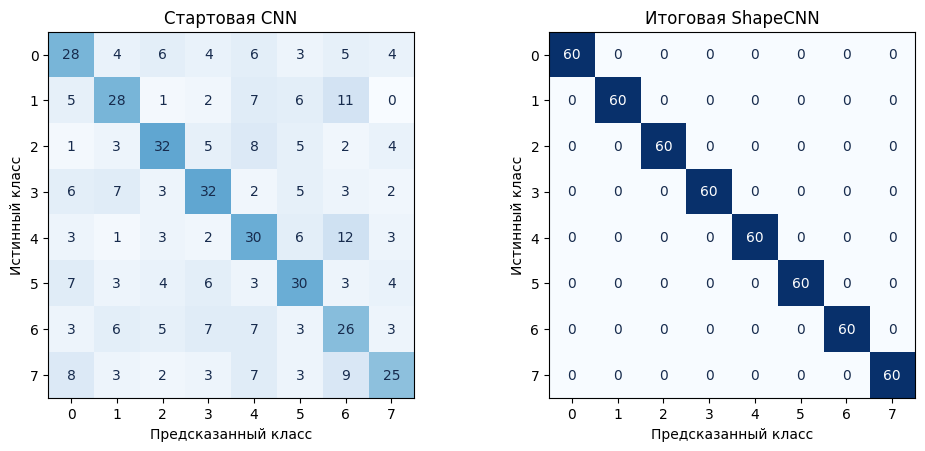

,class,support,precision,recall,f1,baseline_f1
0,Шайба,60,1.0,1.0,1.0,0.462810
1,Разрезная шайба,60,1.0,1.0,1.0,0.486957
2,Пластина с 1 отверстием,60,1.0,1.0,1.0,0.551724
3,Пластина с 2 отверстиями,60,1.0,1.0,1.0,0.528926
4,Шестерня с 6 зубьями,60,1.0,1.0,1.0,0.461538
5,Шестерня с 8 зубьями,60,1.0,1.0,1.0,0.495868
6,Вилка с 2 зубцами,60,1.0,1.0,1.0,0.396947
7,Вилка с 3 зубцами,60,1.0,1.0,1.0,0.476190


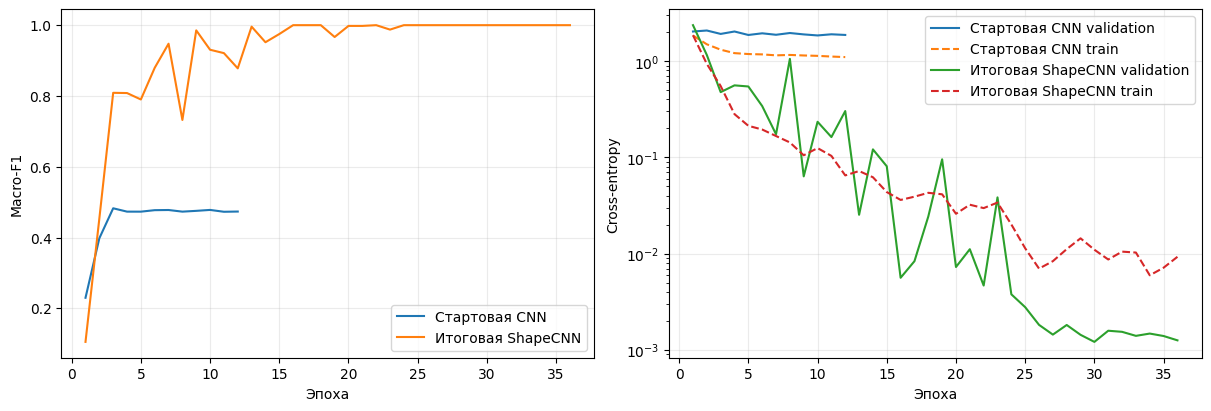

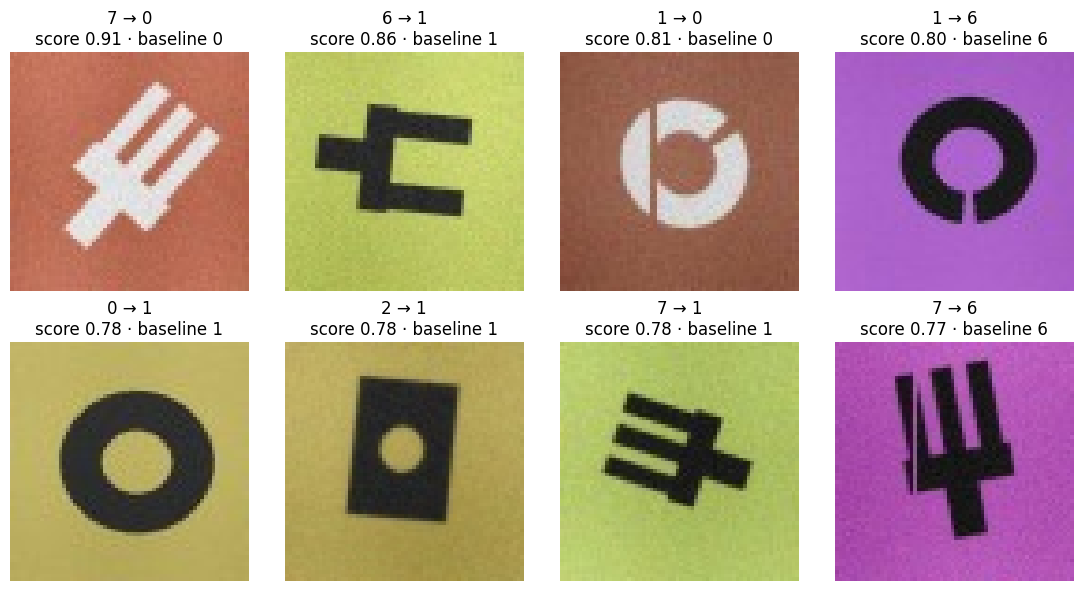

,id,label,prediction,confidence,baseline_prediction,яркость_P95_минус_P05
17,c1ec8b1dbc0e3ea5f71e,7,0,0.909582,0,106.0
370,61a202c5a389d2fe7daf,6,1,0.861750,1,160.0
202,3f9ce914daa0276a4912,1,0,0.805774,0,118.0
91,a623baf6eab1b70e2a12,1,6,0.799619,6,110.0
106,4d92fee1e08ac39dc142,0,1,0.780289,1,134.0
297,9f5e1591b22c66159540,2,1,0.776905,1,136.0
406,c23c7606bb17b3f3fe4a,7,1,0.776243,1,163.0
257,99f70776628f54c92a4b,7,6,0.768193,6,111.0


In [14]:
REPORT = {'experiments': [{'name': 'baseline', 'architecture': 'small', 'parent': '', 'hypothesis': 'Контрольный запуск SmallCNN', 'geometry': 'False', 'grayscale': 'False', 'invert': 'False', 'weighted': 'False', 'image_size': '64', 'epochs': '12', 'seed': '17', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'False', 'amp': 'False', 'trained_with_amp': 'False', 'parameters': '24104', 'best_epoch': '3', 'val_macro_f1': '0.4826199335087154', 'seconds': '10.218824173999963', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 1}, {'name': 'late_pool', 'architecture': 'late_pool', 'parent': 'baseline', 'hypothesis': 'Отложить первый pooling до второй Conv', 'geometry': 'False', 'grayscale': 'False', 'invert': 'False', 'weighted': 'False', 'image_size': '64', 'epochs': '12', 'seed': '17', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'False', 'amp': 'False', 'trained_with_amp': 'False', 'parameters': '24104', 'best_epoch': '10', 'val_macro_f1': '0.48021861841161567', 'seconds': '4.168522471000017', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 1}, {'name': 'shape', 'architecture': 'shape_cnn', 'parent': 'late_pool', 'hypothesis': 'Остаточная CNN с пространственной головой', 'geometry': 'False', 'grayscale': 'False', 'invert': 'False', 'weighted': 'False', 'image_size': '64', 'epochs': '12', 'seed': '17', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'False', 'amp': 'False', 'trained_with_amp': 'False', 'parameters': '607976', 'best_epoch': '12', 'val_macro_f1': '0.5814832231948914', 'seconds': '13.290492174000008', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 1}, {'name': 'geometry', 'architecture': 'shape_cnn', 'parent': 'shape', 'hypothesis': 'Устойчивость к положению детали', 'geometry': 'True', 'grayscale': 'False', 'invert': 'False', 'weighted': 'False', 'image_size': '64', 'epochs': '12', 'seed': '17', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'False', 'amp': 'False', 'trained_with_amp': 'False', 'parameters': '607976', 'best_epoch': '12', 'val_macro_f1': '0.6698753026928299', 'seconds': '13.339326012000015', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 1}, {'name': 'gray', 'architecture': 'shape_cnn', 'parent': 'geometry', 'hypothesis': 'Устойчивость к оттенку фона', 'geometry': 'True', 'grayscale': 'True', 'invert': 'False', 'weighted': 'False', 'image_size': '64', 'epochs': '12', 'seed': '17', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'False', 'amp': 'False', 'trained_with_amp': 'False', 'parameters': '607976', 'best_epoch': '6', 'val_macro_f1': '0.9749998553140264', 'seconds': '13.88888302800001', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 1}, {'name': 'polarity', 'architecture': 'shape_cnn', 'parent': 'gray', 'hypothesis': 'Устойчивость к полярности контраста', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '12', 'seed': '17', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'False', 'amp': 'False', 'trained_with_amp': 'False', 'parameters': '607976', 'best_epoch': '12', 'val_macro_f1': '0.9794751790872803', 'seconds': '15.172701984000014', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 1}, {'name': 'balanced', 'architecture': 'shape_cnn', 'parent': 'gray', 'hypothesis': 'Больше вклад редких классов в loss', 'geometry': 'True', 'grayscale': 'True', 'invert': 'False', 'weighted': 'True', 'image_size': '64', 'epochs': '12', 'seed': '17', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'False', 'amp': 'False', 'trained_with_amp': 'False', 'parameters': '607976', 'best_epoch': '12', 'val_macro_f1': '0.9288473825272716', 'seconds': '14.195202152000036', 'class_weights': '[0.7066587209701538, 0.7448837161064148, 0.8159792423248291, 0.91229248046875, 0.9993663430213928, 1.1173255443572998, 1.2901763916015625, 1.4133174419403076]', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 1}, {'name': 'polarity', 'architecture': 'shape_cnn', 'parent': 'gray', 'hypothesis': 'Устойчивость к полярности контраста', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '12', 'seed': '27', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'False', 'amp': 'False', 'trained_with_amp': 'False', 'parameters': '607976', 'best_epoch': '5', 'val_macro_f1': '0.966789775511957', 'seconds': '15.459807836000039', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 1}, {'name': 'polarity_long', 'architecture': 'shape_cnn', 'parent': 'polarity', 'hypothesis': 'Длинный бюджет с cosine LR и CUDA AMP', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '17', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '21', 'val_macro_f1': '1.0', 'seconds': '53.45165766299999', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 1}, {'name': 'polarity_long', 'architecture': 'shape_cnn', 'parent': 'polarity', 'hypothesis': 'Длинный бюджет с cosine LR и CUDA AMP', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '27', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '22', 'val_macro_f1': '1.0', 'seconds': '52.21454229900007', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 1}, {'name': 'gray_long', 'architecture': 'shape_cnn', 'parent': 'gray', 'hypothesis': 'Длинный бюджет с cosine LR и CUDA AMP', 'geometry': 'True', 'grayscale': 'True', 'invert': 'False', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '17', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '24', 'val_macro_f1': '1.0', 'seconds': '47.980646548000095', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 1}, {'name': 'gray_long', 'architecture': 'shape_cnn', 'parent': 'gray', 'hypothesis': 'Длинный бюджет с cosine LR и CUDA AMP', 'geometry': 'True', 'grayscale': 'True', 'invert': 'False', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '27', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '22', 'val_macro_f1': '1.0', 'seconds': '47.87867255399999', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 1}, {'name': 'resnet18', 'architecture': 'resnet18', 'parent': 'polarity', 'hypothesis': 'Разрешённое ImageNet-предобучение и дообучение всей ResNet18', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '128', 'epochs': '36', 'seed': '17', 'lr': '0.001', 'backbone_lr': '0.0001', 'cosine': 'True', 'amp': 'True', 'trained_with_amp': 'True', 'parameters': '11180616', 'best_epoch': '25', 'val_macro_f1': '1.0', 'seconds': '107.09199308500001', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'torchvision ResNet18_Weights.IMAGENET1K_V1', 'stage': 1}, {'name': 'resnet18', 'architecture': 'resnet18', 'parent': 'polarity', 'hypothesis': 'Разрешённое ImageNet-предобучение и дообучение всей ResNet18', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '128', 'epochs': '36', 'seed': '27', 'lr': '0.001', 'backbone_lr': '0.0001', 'cosine': 'True', 'amp': 'True', 'trained_with_amp': 'True', 'parameters': '11180616', 'best_epoch': '9', 'val_macro_f1': '1.0', 'seconds': '106.81739474799997', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'torchvision ResNet18_Weights.IMAGENET1K_V1', 'stage': 1}, {'name': 'r2_control', 'architecture': 'shape_cnn', 'parent': '', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'False', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '17', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '24', 'val_macro_f1': '1.0', 'seconds': '50.926088016999984', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 2}, {'name': 'r2_control', 'architecture': 'shape_cnn', 'parent': '', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'False', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '27', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '22', 'val_macro_f1': '1.0', 'seconds': '50.38712854100004', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 2}, {'name': 'r2_control', 'architecture': 'shape_cnn', 'parent': '', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'False', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '37', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '30', 'val_macro_f1': '1.0', 'seconds': '51.21383237400005', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 2}, {'name': 'r2_constant_lr', 'architecture': 'shape_cnn', 'parent': 'r2_control', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'False', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '17', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'False', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '34', 'val_macro_f1': '1.0', 'seconds': '50.65796770199995', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 2}, {'name': 'r2_constant_lr', 'architecture': 'shape_cnn', 'parent': 'r2_control', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'False', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '27', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'False', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '34', 'val_macro_f1': '0.9979165219806931', 'seconds': '49.70583812400014', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 2}, {'name': 'r2_constant_lr', 'architecture': 'shape_cnn', 'parent': 'r2_control', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'False', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '37', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'False', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '29', 'val_macro_f1': '1.0', 'seconds': '49.441776841999854', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 2}, {'name': 'r2_invert', 'architecture': 'shape_cnn', 'parent': 'r2_control', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '17', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '21', 'val_macro_f1': '1.0', 'seconds': '53.455071910000015', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 2}, {'name': 'r2_invert', 'architecture': 'shape_cnn', 'parent': 'r2_control', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '27', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '22', 'val_macro_f1': '1.0', 'seconds': '53.87377994399981', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 2}, {'name': 'r2_invert', 'architecture': 'shape_cnn', 'parent': 'r2_control', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '37', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '30', 'val_macro_f1': '1.0', 'seconds': '53.17091378000009', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 2}, {'name': 'r2_blur', 'architecture': 'shape_cnn', 'parent': 'r2_control', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'False', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '17', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'True', 'contrast': 'False', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '28', 'val_macro_f1': '1.0', 'seconds': '53.781058480999945', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 2}, {'name': 'r2_blur', 'architecture': 'shape_cnn', 'parent': 'r2_control', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'False', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '27', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'True', 'contrast': 'False', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '14', 'val_macro_f1': '1.0', 'seconds': '53.956588655999894', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 2}, {'name': 'r2_blur', 'architecture': 'shape_cnn', 'parent': 'r2_control', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'False', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '37', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'True', 'contrast': 'False', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '26', 'val_macro_f1': '0.9979165219806931', 'seconds': '53.473393490000035', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 2}, {'name': 'r2_contrast', 'architecture': 'shape_cnn', 'parent': 'r2_control', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'False', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '17', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'True', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '30', 'val_macro_f1': '1.0', 'seconds': '52.56456448699987', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 2}, {'name': 'r2_contrast', 'architecture': 'shape_cnn', 'parent': 'r2_control', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'False', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '27', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'True', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '22', 'val_macro_f1': '0.9979165219806931', 'seconds': '51.25793708099991', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 2}, {'name': 'r2_contrast', 'architecture': 'shape_cnn', 'parent': 'r2_control', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'False', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '37', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'True', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '29', 'val_macro_f1': '1.0', 'seconds': '50.41908625000019', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 2}, {'name': 'r3_first', 'architecture': 'shape_cnn', 'parent': '', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '17', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'checkpoint_loss_tiebreak': 'False', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '21', 'val_macro_f1': '1.0', 'val_loss': '0.010398255164424578', 'seconds': '53.10135759799999', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 3}, {'name': 'r3_first', 'architecture': 'shape_cnn', 'parent': '', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '27', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'checkpoint_loss_tiebreak': 'False', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '22', 'val_macro_f1': '1.0', 'val_loss': '0.006067198328673839', 'seconds': '49.10295810800005', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 3}, {'name': 'r3_first', 'architecture': 'shape_cnn', 'parent': '', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '37', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'checkpoint_loss_tiebreak': 'False', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '30', 'val_macro_f1': '1.0', 'val_loss': '0.007040447182953357', 'seconds': '50.521152321000045', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 3}, {'name': 'r3_loss', 'architecture': 'shape_cnn', 'parent': 'r3_first', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '17', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'checkpoint_loss_tiebreak': 'True', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '30', 'val_macro_f1': '1.0', 'val_loss': '0.0023450398507217566', 'seconds': '50.36266431399997', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 3}, {'name': 'r3_loss', 'architecture': 'shape_cnn', 'parent': 'r3_first', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '27', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'checkpoint_loss_tiebreak': 'True', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '29', 'val_macro_f1': '1.0', 'val_loss': '0.002875790217270454', 'seconds': '49.59115704999999', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 3}, {'name': 'r3_loss', 'architecture': 'shape_cnn', 'parent': 'r3_first', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '37', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'checkpoint_loss_tiebreak': 'True', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '34', 'val_macro_f1': '1.0', 'val_loss': '0.004723889318605264', 'seconds': '50.56850776500005', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 3}, {'name': 'r3_normalized', 'architecture': 'shape_normalized', 'parent': 'r3_loss', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '17', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'checkpoint_loss_tiebreak': 'True', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '30', 'val_macro_f1': '1.0', 'val_loss': '0.0012095877473863462', 'seconds': '62.93787952599996', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 3}, {'name': 'r3_normalized', 'architecture': 'shape_normalized', 'parent': 'r3_loss', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '27', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'checkpoint_loss_tiebreak': 'True', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '31', 'val_macro_f1': '1.0', 'val_loss': '0.0011908285591440896', 'seconds': '61.87958869299996', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 3}, {'name': 'r3_normalized', 'architecture': 'shape_normalized', 'parent': 'r3_loss', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '37', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'checkpoint_loss_tiebreak': 'True', 'trained_with_amp': 'True', 'parameters': '607976', 'best_epoch': '30', 'val_macro_f1': '1.0', 'val_loss': '0.0009932674661589165', 'seconds': '62.52316822099999', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 3}, {'name': 'r3_wide', 'architecture': 'shape_wide', 'parent': 'r3_loss', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '17', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'checkpoint_loss_tiebreak': 'True', 'trained_with_amp': 'True', 'parameters': '2418632', 'best_epoch': '26', 'val_macro_f1': '1.0', 'val_loss': '0.003897178933645288', 'seconds': '70.07920894699998', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 3}, {'name': 'r3_wide', 'architecture': 'shape_wide', 'parent': 'r3_loss', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '27', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'checkpoint_loss_tiebreak': 'True', 'trained_with_amp': 'True', 'parameters': '2418632', 'best_epoch': '35', 'val_macro_f1': '1.0', 'val_loss': '0.005107502468551199', 'seconds': '69.71419081900001', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 3}, {'name': 'r3_wide', 'architecture': 'shape_wide', 'parent': 'r3_loss', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '37', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'checkpoint_loss_tiebreak': 'True', 'trained_with_amp': 'True', 'parameters': '2418632', 'best_epoch': '35', 'val_macro_f1': '1.0', 'val_loss': '0.00804423737184455', 'seconds': '69.76543125299986', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 3}, {'name': 'r3_wide_aa', 'architecture': 'shape_wide_aa', 'parent': 'r3_wide', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '17', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'checkpoint_loss_tiebreak': 'True', 'trained_with_amp': 'True', 'parameters': '2418632', 'best_epoch': '35', 'val_macro_f1': '1.0', 'val_loss': '0.0016963157977443188', 'seconds': '75.54225963699992', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 3}, {'name': 'r3_wide_aa', 'architecture': 'shape_wide_aa', 'parent': 'r3_wide', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '27', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'checkpoint_loss_tiebreak': 'True', 'trained_with_amp': 'True', 'parameters': '2418632', 'best_epoch': '36', 'val_macro_f1': '1.0', 'val_loss': '0.004626048899566134', 'seconds': '75.42200006199982', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 3}, {'name': 'r3_wide_aa', 'architecture': 'shape_wide_aa', 'parent': 'r3_wide', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '37', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'checkpoint_loss_tiebreak': 'True', 'trained_with_amp': 'True', 'parameters': '2418632', 'best_epoch': '34', 'val_macro_f1': '0.9979165219806931', 'val_loss': '0.009912106557749212', 'seconds': '75.56371537300015', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 3}, {'name': 'r3_wide_aa_normalized', 'architecture': 'shape_wide_aa_normalized', 'parent': 'r3_wide_aa', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '17', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'checkpoint_loss_tiebreak': 'True', 'trained_with_amp': 'True', 'parameters': '2418632', 'best_epoch': '30', 'val_macro_f1': '0.9979165219806931', 'val_loss': '0.011259221999595562', 'seconds': '84.76205974799996', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 3}, {'name': 'r3_wide_aa_normalized', 'architecture': 'shape_wide_aa_normalized', 'parent': 'r3_wide_aa', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '27', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'checkpoint_loss_tiebreak': 'True', 'trained_with_amp': 'True', 'parameters': '2418632', 'best_epoch': '30', 'val_macro_f1': '1.0', 'val_loss': '0.004016440703223149', 'seconds': '84.67374682700006', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 3}, {'name': 'r3_wide_aa_normalized', 'architecture': 'shape_wide_aa_normalized', 'parent': 'r3_wide_aa', 'hypothesis': '', 'geometry': 'True', 'grayscale': 'True', 'invert': 'True', 'weighted': 'False', 'image_size': '64', 'epochs': '36', 'seed': '37', 'lr': '0.002', 'backbone_lr': '0.0002', 'cosine': 'True', 'amp': 'True', 'blur': 'False', 'contrast': 'False', 'checkpoint_loss_tiebreak': 'True', 'trained_with_amp': 'True', 'parameters': '2418632', 'best_epoch': '34', 'val_macro_f1': '1.0', 'val_loss': '0.002436150455226501', 'seconds': '84.64591960999996', 'class_weights': '', 'device': 'Tesla T4', 'weights_source': 'random', 'stage': 3}], 'ranking': [{'name': 'r3_normalized', 'mean_f1': '1.0', 'min_f1': '1.0', 'mean_loss': '0.0011312279242297841', 'parameters': '607976', 'seconds': '62.446878813333306', 'stress_f1': '1.0'}, {'name': 'r3_first', 'mean_f1': '1.0', 'min_f1': '1.0', 'mean_loss': '0.00783530022535059', 'parameters': '607976', 'seconds': '50.90848934233336', 'stress_f1': '0.9930859897578297'}, {'name': 'r3_loss', 'mean_f1': '1.0', 'min_f1': '1.0', 'mean_loss': '0.003314906462199158', 'parameters': '607976', 'seconds': '50.17410970966667', 'stress_f1': '0.9924199942511596'}, {'name': 'r3_wide', 'mean_f1': '1.0', 'min_f1': '1.0', 'mean_loss': '0.005682972924680345', 'parameters': '2418632', 'seconds': '69.85294367299996', 'stress_f1': '0.8961750961559792'}, {'name': 'r3_wide_aa_normalized', 'mean_f1': '0.9993055073268978', 'min_f1': '0.9979165219806931', 'mean_loss': '0.005903937719348404', 'parameters': '2418632', 'seconds': '84.69390872833333', 'stress_f1': '0.9958327545090357'}, {'name': 'r3_wide_aa', 'mean_f1': '0.9993055073268978', 'min_f1': '0.9979165219806931', 'mean_loss': '0.0054114904183532216', 'parameters': '2418632', 'seconds': '75.50932502399996', 'stress_f1': '0.8889033115726761'}], 'robustness': [{'recipe': 'r3_first', 'seed': '17', 'variant': 'clean', 'macro_f1': '1.0', 'loss': '0.010398255164424578'}, {'recipe': 'r3_first', 'seed': '17', 'variant': 'blur_05', 'macro_f1': '0.9979165219806931', 'loss': '0.009713115046421687'}, {'recipe': 'r3_first', 'seed': '17', 'variant': 'contrast_07', 'macro_f1': '0.9979165219806931', 'loss': '0.015784032891194025'}, {'recipe': 'r3_first', 'seed': '17', 'variant': 'inverted', 'macro_f1': '0.9979165219806931', 'loss': '0.011045259113113085'}, {'recipe': 'r3_first', 'seed': '27', 'variant': 'clean', 'macro_f1': '1.0', 'loss': '0.006067198328673839'}, {'recipe': 'r3_first', 'seed': '27', 'variant': 'blur_05', 'macro_f1': '0.9979165219806931', 'loss': '0.009424280747771263'}, {'recipe': 'r3_first', 'seed': '27', 'variant': 'contrast_07', 'macro_f1': '0.9875927497077683', 'loss': '0.04175648676852385'}, {'recipe': 'r3_first', 'seed': '27', 'variant': 'inverted', 'macro_f1': '0.9958321756043346', 'loss': '0.012589501480882366'}, {'recipe': 'r3_first', 'seed': '37', 'variant': 'clean', 'macro_f1': '1.0', 'loss': '0.007040447182953357'}, {'recipe': 'r3_first', 'seed': '37', 'variant': 'blur_05', 'macro_f1': '0.9979165219806931', 'loss': '0.008674967180316647'}, {'recipe': 'r3_first', 'seed': '37', 'variant': 'contrast_07', 'macro_f1': '0.9937486975850277', 'loss': '0.029345225356519223'}, {'recipe': 'r3_first', 'seed': '37', 'variant': 'inverted', 'macro_f1': '0.9979165219806931', 'loss': '0.008326614539449414'}, {'recipe': 'r3_loss', 'seed': '17', 'variant': 'clean', 'macro_f1': '1.0', 'loss': '0.0023450398507217566'}, {'recipe': 'r3_loss', 'seed': '17', 'variant': 'blur_05', 'macro_f1': '1.0', 'loss': '0.001330885508408149'}, {'recipe': 'r3_loss', 'seed': '17', 'variant': 'contrast_07', 'macro_f1': '1.0', 'loss': '0.0024591143087794383'}, {'recipe': 'r3_loss', 'seed': '17', 'variant': 'inverted', 'macro_f1': '0.9979165219806931', 'loss': '0.004304549373531094'}, {'recipe': 'r3_loss', 'seed': '27', 'variant': 'clean', 'macro_f1': '1.0', 'loss': '0.002875790217270454'}, {'recipe': 'r3_loss', 'seed': '27', 'variant': 'blur_05', 'macro_f1': '1.0', 'loss': '0.002362981562813123'}, {'recipe': 'r3_loss', 'seed': '27', 'variant': 'contrast_07', 'macro_f1': '0.9835112851684512', 'loss': '0.03103351208070914'}, {'recipe': 'r3_loss', 'seed': '27', 'variant': 'inverted', 'macro_f1': '0.9979165219806931', 'loss': '0.006616813798124592'}, {'recipe': 'r3_loss', 'seed': '37', 'variant': 'clean', 'macro_f1': '1.0', 'loss': '0.004723889318605264'}, {'recipe': 'r3_loss', 'seed': '37', 'variant': 'blur_05', 'macro_f1': '0.9979165219806931', 'loss': '0.007493725186213851'}, {'recipe': 'r3_loss', 'seed': '37', 'variant': 'contrast_07', 'macro_f1': '0.9958321756043346', 'loss': '0.015173307154327631'}, {'recipe': 'r3_loss', 'seed': '37', 'variant': 'inverted', 'macro_f1': '1.0', 'loss': '0.00353333061405768'}, {'recipe': 'r3_normalized', 'seed': '17', 'variant': 'clean', 'macro_f1': '1.0', 'loss': '0.0012095877473863462'}, {'recipe': 'r3_normalized', 'seed': '17', 'variant': 'blur_05', 'macro_f1': '1.0', 'loss': '0.0016959454980678857'}, {'recipe': 'r3_normalized', 'seed': '17', 'variant': 'contrast_07', 'macro_f1': '1.0', 'loss': '0.001230898491727809'}, {'recipe': 'r3_normalized', 'seed': '17', 'variant': 'inverted', 'macro_f1': '1.0', 'loss': '0.0022757183915625015'}, {'recipe': 'r3_normalized', 'seed': '27', 'variant': 'clean', 'macro_f1': '1.0', 'loss': '0.0011908285591440896'}, {'recipe': 'r3_normalized', 'seed': '27', 'variant': 'blur_05', 'macro_f1': '1.0', 'loss': '0.0011655555261919895'}, {'recipe': 'r3_normalized', 'seed': '27', 'variant': 'contrast_07', 'macro_f1': '1.0', 'loss': '0.001188030776878198'}, {'recipe': 'r3_normalized', 'seed': '27', 'variant': 'inverted', 'macro_f1': '1.0', 'loss': '0.0011599740362726152'}, {'recipe': 'r3_normalized', 'seed': '37', 'variant': 'clean', 'macro_f1': '1.0', 'loss': '0.0009932674661589165'}, {'recipe': 'r3_normalized', 'seed': '37', 'variant': 'blur_05', 'macro_f1': '1.0', 'loss': '0.0017590866618168851'}, {'recipe': 'r3_normalized', 'seed': '37', 'variant': 'contrast_07', 'macro_f1': '1.0', 'loss': '0.000994544194933648'}, {'recipe': 'r3_normalized', 'seed': '37', 'variant': 'inverted', 'macro_f1': '1.0', 'loss': '0.0011728677704619865'}, {'recipe': 'r3_wide', 'seed': '17', 'variant': 'clean', 'macro_f1': '1.0', 'loss': '0.003897178933645288'}, {'recipe': 'r3_wide', 'seed': '17', 'variant': 'blur_05', 'macro_f1': '0.9958330439613863', 'loss': '0.011201226951864858'}, {'recipe': 'r3_wide', 'seed': '17', 'variant': 'contrast_07', 'macro_f1': '0.8010025472925322', 'loss': '1.1530381182829539'}, {'recipe': 'r3_wide', 'seed': '17', 'variant': 'inverted', 'macro_f1': '0.9979165219806931', 'loss': '0.00796614062661926'}, {'recipe': 'r3_wide', 'seed': '27', 'variant': 'clean', 'macro_f1': '1.0', 'loss': '0.005107502468551199'}, {'recipe': 'r3_wide', 'seed': '27', 'variant': 'blur_05', 'macro_f1': '0.9958321756043346', 'loss': '0.011427395914991697'}, {'recipe': 'r3_wide', 'seed': '27', 'variant': 'contrast_07', 'macro_f1': '0.9221939116848306', 'loss': '0.22243449240922927'}, {'recipe': 'r3_wide', 'seed': '27', 'variant': 'inverted', 'macro_f1': '0.9979165219806931', 'loss': '0.006524579723676046'}, {'recipe': 'r3_wide', 'seed': '37', 'variant': 'clean', 'macro_f1': '1.0', 'loss': '0.00804423737184455'}, {'recipe': 'r3_wide', 'seed': '37', 'variant': 'blur_05', 'macro_f1': '0.9979165219806931', 'loss': '0.011483797167117397'}, {'recipe': 'r3_wide', 'seed': '37', 'variant': 'contrast_07', 'macro_f1': '0.9653288294905753', 'loss': '0.15131611339747905'}, {'recipe': 'r3_wide', 'seed': '37', 'variant': 'inverted', 'macro_f1': '1.0', 'loss': '0.005887274382015069'}, {'recipe': 'r3_wide_aa', 'seed': '17', 'variant': 'clean', 'macro_f1': '1.0', 'loss': '0.0016963157977443188'}, {'recipe': 'r3_wide_aa', 'seed': '17', 'variant': 'blur_05', 'macro_f1': '1.0', 'loss': '0.0012785855680704117'}, {'recipe': 'r3_wide_aa', 'seed': '17', 'variant': 'contrast_07', 'macro_f1': '0.897388491748037', 'loss': '0.3601339042186737'}, {'recipe': 'r3_wide_aa', 'seed': '17', 'variant': 'inverted', 'macro_f1': '1.0', 'loss': '0.0012085120271270475'}, {'recipe': 'r3_wide_aa', 'seed': '27', 'variant': 'clean', 'macro_f1': '1.0', 'loss': '0.004626048899566134'}, {'recipe': 'r3_wide_aa', 'seed': '27', 'variant': 'blur_05', 'macro_f1': '0.9958321756043346', 'loss': '0.016222573700360954'}, {'recipe': 'r3_wide_aa', 'seed': '27', 'variant': 'contrast_07', 'macro_f1': '0.8643134309353535', 'loss': '0.4614799658457438'}, {'recipe': 'r3_wide_aa', 'seed': '27', 'variant': 'inverted', 'macro_f1': '1.0', 'loss': '0.007312978555758794'}, {'recipe': 'r3_wide_aa', 'seed': '37', 'variant': 'clean', 'macro_f1': '0.9979165219806931', 'loss': '0.009912106557749212'}, {'recipe': 'r3_wide_aa', 'seed': '37', 'variant': 'blur_05', 'macro_f1': '0.9958330439613863', 'loss': '0.011387592554092408'}, {'recipe': 'r3_wide_aa', 'seed': '37', 'variant': 'contrast_07', 'macro_f1': '0.905008012034638', 'loss': '0.4043289810419083'}, {'recipe': 'r3_wide_aa', 'seed': '37', 'variant': 'inverted', 'macro_f1': '0.9958330439613863', 'loss': '0.012412611348554491'}, {'recipe': 'r3_wide_aa_normalized', 'seed': '17', 'variant': 'clean', 'macro_f1': '0.9979165219806931', 'loss': '0.011259221999595562'}, {'recipe': 'r3_wide_aa_normalized', 'seed': '17', 'variant': 'blur_05', 'macro_f1': '0.9895817415464139', 'loss': '0.024831338009486597'}, {'recipe': 'r3_wide_aa_normalized', 'seed': '17', 'variant': 'contrast_07', 'macro_f1': '0.9979165219806931', 'loss': '0.011629793575654428'}, {'recipe': 'r3_wide_aa_normalized', 'seed': '17', 'variant': 'inverted', 'macro_f1': '0.9958321756043346', 'loss': '0.013727137415359417'}, {'recipe': 'r3_wide_aa_normalized', 'seed': '27', 'variant': 'clean', 'macro_f1': '1.0', 'loss': '0.004016440703223149'}, {'recipe': 'r3_wide_aa_normalized', 'seed': '27', 'variant': 'blur_05', 'macro_f1': '1.0', 'loss': '0.0038474745427568755'}, {'recipe': 'r3_wide_aa_normalized', 'seed': '27', 'variant': 'contrast_07', 'macro_f1': '1.0', 'loss': '0.004020623009031017'}, {'recipe': 'r3_wide_aa_normalized', 'seed': '27', 'variant': 'inverted', 'macro_f1': '1.0', 'loss': '0.0044743033281217015'}, {'recipe': 'r3_wide_aa_normalized', 'seed': '37', 'variant': 'clean', 'macro_f1': '1.0', 'loss': '0.002436150455226501'}, {'recipe': 'r3_wide_aa_normalized', 'seed': '37', 'variant': 'blur_05', 'macro_f1': '0.9979165219806931', 'loss': '0.005365860093540202'}, {'recipe': 'r3_wide_aa_normalized', 'seed': '37', 'variant': 'contrast_07', 'macro_f1': '1.0', 'loss': '0.0024362431916718683'}, {'recipe': 'r3_wide_aa_normalized', 'seed': '37', 'variant': 'inverted', 'macro_f1': '1.0', 'loss': '0.002242762187961489'}], 'baseline_predictions': [{'id': 'd815ffa9bc2f725af020', 'file': 'images/validation/d815ffa9bc2f725af020.jpg', 'label': '0', 'prediction': '1', 'confidence': '0.7724671'}, {'id': '10761c641f90302ae3fd', 'file': 'images/validation/10761c641f90302ae3fd.jpg', 'label': '2', 'prediction': '4', 'confidence': '0.46669772'}, {'id': '68d4f568e7de7e9ceb70', 'file': 'images/validation/68d4f568e7de7e9ceb70.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.3194445'}, {'id': '80d8ca06e5194424e6b4', 'file': 'images/validation/80d8ca06e5194424e6b4.jpg', 'label': '5', 'prediction': '7', 'confidence': '0.5726465'}, {'id': 'aba4053cafa9657aff9b', 'file': 'images/validation/aba4053cafa9657aff9b.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.714399'}, {'id': 'd0d5375a87723a6e7b4d', 'file': 'images/validation/d0d5375a87723a6e7b4d.jpg', 'label': '4', 'prediction': '6', 'confidence': '0.4023588'}, {'id': '51f6373e00d5d78cb4db', 'file': 'images/validation/51f6373e00d5d78cb4db.jpg', 'label': '6', 'prediction': '3', 'confidence': '0.3526424'}, {'id': 'bd721a041174b1454952', 'file': 'images/validation/bd721a041174b1454952.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.5237772'}, {'id': 'b627abead3c2f42e08aa', 'file': 'images/validation/b627abead3c2f42e08aa.jpg', 'label': '7', 'prediction': '0', 'confidence': '0.39266324'}, {'id': 'cc26f36af77e034e22da', 'file': 'images/validation/cc26f36af77e034e22da.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.40858224'}, {'id': '0ac2b6071071e6b869cc', 'file': 'images/validation/0ac2b6071071e6b869cc.jpg', 'label': '2', 'prediction': '7', 'confidence': '0.5374818'}, {'id': '29f72998b434339f87eb', 'file': 'images/validation/29f72998b434339f87eb.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.4313996'}, {'id': '04a43448b2f295eb1a44', 'file': 'images/validation/04a43448b2f295eb1a44.jpg', 'label': '6', 'prediction': '4', 'confidence': '0.31324545'}, {'id': '382abb4a287093a10bfa', 'file': 'images/validation/382abb4a287093a10bfa.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.5406329'}, {'id': '4729f2669464be84fa94', 'file': 'images/validation/4729f2669464be84fa94.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.53670573'}, {'id': 'fbca3e0a84d166354d06', 'file': 'images/validation/fbca3e0a84d166354d06.jpg', 'label': '6', 'prediction': '4', 'confidence': '0.41325855'}, {'id': '1b137a73c2e3faf9ccc9', 'file': 'images/validation/1b137a73c2e3faf9ccc9.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.462991'}, {'id': 'c1ec8b1dbc0e3ea5f71e', 'file': 'images/validation/c1ec8b1dbc0e3ea5f71e.jpg', 'label': '7', 'prediction': '0', 'confidence': '0.9095816'}, {'id': '6680def863cc7cc3c6e8', 'file': 'images/validation/6680def863cc7cc3c6e8.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.54252714'}, {'id': '1be6c9610a7ceb2b380a', 'file': 'images/validation/1be6c9610a7ceb2b380a.jpg', 'label': '5', 'prediction': '0', 'confidence': '0.6622608'}, {'id': '63e3df3550fd02773311', 'file': 'images/validation/63e3df3550fd02773311.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.57935846'}, {'id': '26888fc7ff9029a4cdbd', 'file': 'images/validation/26888fc7ff9029a4cdbd.jpg', 'label': '0', 'prediction': '2', 'confidence': '0.42868328'}, {'id': '15057b0f60b88a91fc9f', 'file': 'images/validation/15057b0f60b88a91fc9f.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.5576509'}, {'id': 'cb24e651643c5ab9813b', 'file': 'images/validation/cb24e651643c5ab9813b.jpg', 'label': '3', 'prediction': '1', 'confidence': '0.7254473'}, {'id': '0f2d9a4952b4568665cb', 'file': 'images/validation/0f2d9a4952b4568665cb.jpg', 'label': '0', 'prediction': '4', 'confidence': '0.584717'}, {'id': '52eb8f3ec25a6a646673', 'file': 'images/validation/52eb8f3ec25a6a646673.jpg', 'label': '3', 'prediction': '6', 'confidence': '0.6053132'}, {'id': '89069441bffc91d36e24', 'file': 'images/validation/89069441bffc91d36e24.jpg', 'label': '1', 'prediction': '4', 'confidence': '0.6046904'}, {'id': '29aee616bc4ca4130635', 'file': 'images/validation/29aee616bc4ca4130635.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.5135074'}, {'id': 'e972da3088f8b076bfd1', 'file': 'images/validation/e972da3088f8b076bfd1.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.47139394'}, {'id': '9630296f52f023aec8c4', 'file': 'images/validation/9630296f52f023aec8c4.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.5495073'}, {'id': '2c9b4196f94fe5eb79e9', 'file': 'images/validation/2c9b4196f94fe5eb79e9.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.51657206'}, {'id': '1aaaf07f8747447cfaaa', 'file': 'images/validation/1aaaf07f8747447cfaaa.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.5052625'}, {'id': 'ebc4b679f285aab9e46e', 'file': 'images/validation/ebc4b679f285aab9e46e.jpg', 'label': '2', 'prediction': '6', 'confidence': '0.6456308'}, {'id': '294b58919403e2d4c936', 'file': 'images/validation/294b58919403e2d4c936.jpg', 'label': '2', 'prediction': '1', 'confidence': '0.4786804'}, {'id': '56b21dafdbc50825563d', 'file': 'images/validation/56b21dafdbc50825563d.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.42763963'}, {'id': '6216887eb87f333410dc', 'file': 'images/validation/6216887eb87f333410dc.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.49501458'}, {'id': '73c284756c98b80ef876', 'file': 'images/validation/73c284756c98b80ef876.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.73598105'}, {'id': '8b11a2d7fc17868266d3', 'file': 'images/validation/8b11a2d7fc17868266d3.jpg', 'label': '7', 'prediction': '6', 'confidence': '0.5615723'}, {'id': '6f2e92037440f998a331', 'file': 'images/validation/6f2e92037440f998a331.jpg', 'label': '7', 'prediction': '6', 'confidence': '0.6001139'}, {'id': '8e49a2383529c7832a01', 'file': 'images/validation/8e49a2383529c7832a01.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.39594853'}, {'id': 'cc4e64a9bfaab06a9ae1', 'file': 'images/validation/cc4e64a9bfaab06a9ae1.jpg', 'label': '6', 'prediction': '0', 'confidence': '0.64562345'}, {'id': 'abd33aaf63a0d41752b3', 'file': 'images/validation/abd33aaf63a0d41752b3.jpg', 'label': '4', 'prediction': '0', 'confidence': '0.52526'}, {'id': '924d0e2147e7314e5ae8', 'file': 'images/validation/924d0e2147e7314e5ae8.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.45395872'}, {'id': '8adce811f793d22854be', 'file': 'images/validation/8adce811f793d22854be.jpg', 'label': '6', 'prediction': '4', 'confidence': '0.5956521'}, {'id': 'fa25e2d6c445df7cbb72', 'file': 'images/validation/fa25e2d6c445df7cbb72.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.5556328'}, {'id': '398da076221d23de7766', 'file': 'images/validation/398da076221d23de7766.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.7177227'}, {'id': '249c57b5357ff6a83eb4', 'file': 'images/validation/249c57b5357ff6a83eb4.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.53089035'}, {'id': 'e7b232c6b5a9b35a2599', 'file': 'images/validation/e7b232c6b5a9b35a2599.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.88051075'}, {'id': 'e62d11624b6e8189a2a6', 'file': 'images/validation/e62d11624b6e8189a2a6.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.8002704'}, {'id': '08566b22f7d78c0193ea', 'file': 'images/validation/08566b22f7d78c0193ea.jpg', 'label': '5', 'prediction': '3', 'confidence': '0.48466012'}, {'id': 'f405b3598b09082cca87', 'file': 'images/validation/f405b3598b09082cca87.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.73252'}, {'id': '24a21c2b6e05b7ce776a', 'file': 'images/validation/24a21c2b6e05b7ce776a.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.8258176'}, {'id': '878bb35cffce55c87449', 'file': 'images/validation/878bb35cffce55c87449.jpg', 'label': '1', 'prediction': '5', 'confidence': '0.47040573'}, {'id': '8c555a3d34cb2480d91c', 'file': 'images/validation/8c555a3d34cb2480d91c.jpg', 'label': '0', 'prediction': '4', 'confidence': '0.48204002'}, {'id': '67da96a6f2b5d4422205', 'file': 'images/validation/67da96a6f2b5d4422205.jpg', 'label': '0', 'prediction': '3', 'confidence': '0.52201056'}, {'id': '1c158d3f414678da9cad', 'file': 'images/validation/1c158d3f414678da9cad.jpg', 'label': '3', 'prediction': '0', 'confidence': '0.39885116'}, {'id': '80ca60faa7170c56be94', 'file': 'images/validation/80ca60faa7170c56be94.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.80376136'}, {'id': '52cedb17b7343cae5347', 'file': 'images/validation/52cedb17b7343cae5347.jpg', 'label': '3', 'prediction': '0', 'confidence': '0.4343055'}, {'id': '7224818b4edb79ee4feb', 'file': 'images/validation/7224818b4edb79ee4feb.jpg', 'label': '2', 'prediction': '3', 'confidence': '0.43885234'}, {'id': '6e4f5a7da1db25947821', 'file': 'images/validation/6e4f5a7da1db25947821.jpg', 'label': '5', 'prediction': '1', 'confidence': '0.4593347'}, {'id': '48db8cce2fa24baf5835', 'file': 'images/validation/48db8cce2fa24baf5835.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.50301397'}, {'id': '9d2350e41f8421cbc81a', 'file': 'images/validation/9d2350e41f8421cbc81a.jpg', 'label': '3', 'prediction': '0', 'confidence': '0.44550177'}, {'id': '106b86c410cd893917dc', 'file': 'images/validation/106b86c410cd893917dc.jpg', 'label': '2', 'prediction': '5', 'confidence': '0.3658074'}, {'id': 'fc0f47a634285a7af645', 'file': 'images/validation/fc0f47a634285a7af645.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.77602744'}, {'id': '9856019451368f849732', 'file': 'images/validation/9856019451368f849732.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.7603'}, {'id': '48d0bbbf188a9e4daff5', 'file': 'images/validation/48d0bbbf188a9e4daff5.jpg', 'label': '5', 'prediction': '1', 'confidence': '0.7490666'}, {'id': 'a55ae69af4bcd068d4f0', 'file': 'images/validation/a55ae69af4bcd068d4f0.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.63939434'}, {'id': '7c5e8a2547d15de2f42e', 'file': 'images/validation/7c5e8a2547d15de2f42e.jpg', 'label': '2', 'prediction': '4', 'confidence': '0.64263344'}, {'id': '199cac755efd228a0c99', 'file': 'images/validation/199cac755efd228a0c99.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.648173'}, {'id': '01b0e939be91662d519a', 'file': 'images/validation/01b0e939be91662d519a.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.55045253'}, {'id': '4d820dd61bb18a23214f', 'file': 'images/validation/4d820dd61bb18a23214f.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.4233531'}, {'id': '0e220319a604faf2bd62', 'file': 'images/validation/0e220319a604faf2bd62.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.85663'}, {'id': '238e4ccd901c25ec62f7', 'file': 'images/validation/238e4ccd901c25ec62f7.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.70813656'}, {'id': 'ad5e422eb8de29551666', 'file': 'images/validation/ad5e422eb8de29551666.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.46634218'}, {'id': '87ceaf97c0031fab460f', 'file': 'images/validation/87ceaf97c0031fab460f.jpg', 'label': '1', 'prediction': '3', 'confidence': '0.64177907'}, {'id': '9b8c1e8cf356d172b8f3', 'file': 'images/validation/9b8c1e8cf356d172b8f3.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.5288743'}, {'id': '7808ef5d7369e31fe334', 'file': 'images/validation/7808ef5d7369e31fe334.jpg', 'label': '7', 'prediction': '2', 'confidence': '0.45820528'}, {'id': 'a2ebd6e1e4c61a6400a4', 'file': 'images/validation/a2ebd6e1e4c61a6400a4.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.71397394'}, {'id': '457b8bc53213d15eef93', 'file': 'images/validation/457b8bc53213d15eef93.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.5338346'}, {'id': '7d70ed20aaac54dac221', 'file': 'images/validation/7d70ed20aaac54dac221.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.50145763'}, {'id': '094bf6172958846e538e', 'file': 'images/validation/094bf6172958846e538e.jpg', 'label': '2', 'prediction': '4', 'confidence': '0.38427007'}, {'id': '2ed71a1f4462146a9c02', 'file': 'images/validation/2ed71a1f4462146a9c02.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.480404'}, {'id': '1ad42e4037e727b2e455', 'file': 'images/validation/1ad42e4037e727b2e455.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9031713'}, {'id': '620a5b77b4735da032db', 'file': 'images/validation/620a5b77b4735da032db.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.35566172'}, {'id': 'e98f4ac84c39eb3aaa59', 'file': 'images/validation/e98f4ac84c39eb3aaa59.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.83750725'}, {'id': '79fe5775abb0e8748562', 'file': 'images/validation/79fe5775abb0e8748562.jpg', 'label': '3', 'prediction': '7', 'confidence': '0.5800694'}, {'id': '0e631dd70ba0ed4e3e57', 'file': 'images/validation/0e631dd70ba0ed4e3e57.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.65028423'}, {'id': '9e5d66892d4ad7545c1d', 'file': 'images/validation/9e5d66892d4ad7545c1d.jpg', 'label': '0', 'prediction': '7', 'confidence': '0.6088552'}, {'id': '61a93ceaf2e3a43527e9', 'file': 'images/validation/61a93ceaf2e3a43527e9.jpg', 'label': '3', 'prediction': '1', 'confidence': '0.42747733'}, {'id': '9268fef2e89773549672', 'file': 'images/validation/9268fef2e89773549672.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.5794392'}, {'id': '5ab5893efdce06ef5af4', 'file': 'images/validation/5ab5893efdce06ef5af4.jpg', 'label': '7', 'prediction': '0', 'confidence': '0.33850223'}, {'id': 'a623baf6eab1b70e2a12', 'file': 'images/validation/a623baf6eab1b70e2a12.jpg', 'label': '1', 'prediction': '6', 'confidence': '0.7996191'}, {'id': '00855be56e3712d37e68', 'file': 'images/validation/00855be56e3712d37e68.jpg', 'label': '0', 'prediction': '6', 'confidence': '0.36431223'}, {'id': 'b503b9644dea67533534', 'file': 'images/validation/b503b9644dea67533534.jpg', 'label': '0', 'prediction': '4', 'confidence': '0.40557906'}, {'id': '3954eb108b6a05009327', 'file': 'images/validation/3954eb108b6a05009327.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.67569077'}, {'id': 'f69aa5e4cfd020df17f6', 'file': 'images/validation/f69aa5e4cfd020df17f6.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.37307674'}, {'id': '4a8d6bb6817eaf83783f', 'file': 'images/validation/4a8d6bb6817eaf83783f.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.5728905'}, {'id': '0606990b394f55f3722c', 'file': 'images/validation/0606990b394f55f3722c.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.6479694'}, {'id': 'bc46570dc5a02235b2d4', 'file': 'images/validation/bc46570dc5a02235b2d4.jpg', 'label': '1', 'prediction': '4', 'confidence': '0.45245418'}, {'id': '56e972bfa9e46fb83643', 'file': 'images/validation/56e972bfa9e46fb83643.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.7485918'}, {'id': 'c29cb718fec479a68ff8', 'file': 'images/validation/c29cb718fec479a68ff8.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.5110052'}, {'id': '4ed9f192a83f6adcd085', 'file': 'images/validation/4ed9f192a83f6adcd085.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.5749501'}, {'id': '8d9fea99ba3c8c3f6177', 'file': 'images/validation/8d9fea99ba3c8c3f6177.jpg', 'label': '0', 'prediction': '7', 'confidence': '0.47176322'}, {'id': '1978d1a52b9b31548e5a', 'file': 'images/validation/1978d1a52b9b31548e5a.jpg', 'label': '6', 'prediction': '3', 'confidence': '0.39388478'}, {'id': 'd909b329d90343642f50', 'file': 'images/validation/d909b329d90343642f50.jpg', 'label': '0', 'prediction': '6', 'confidence': '0.45049375'}, {'id': '97d61d18df646f52c918', 'file': 'images/validation/97d61d18df646f52c918.jpg', 'label': '0', 'prediction': '7', 'confidence': '0.2809403'}, {'id': '4d92fee1e08ac39dc142', 'file': 'images/validation/4d92fee1e08ac39dc142.jpg', 'label': '0', 'prediction': '1', 'confidence': '0.7802886'}, {'id': '7b6cdaa94ac855ad7433', 'file': 'images/validation/7b6cdaa94ac855ad7433.jpg', 'label': '0', 'prediction': '2', 'confidence': '0.5867389'}, {'id': 'dc37a2fe4087f45afa99', 'file': 'images/validation/dc37a2fe4087f45afa99.jpg', 'label': '7', 'prediction': '0', 'confidence': '0.49213636'}, {'id': '363c9b8514aeda05680d', 'file': 'images/validation/363c9b8514aeda05680d.jpg', 'label': '6', 'prediction': '0', 'confidence': '0.49037322'}, {'id': 'a2c5ec3ccc3a07eaf23f', 'file': 'images/validation/a2c5ec3ccc3a07eaf23f.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.48211083'}, {'id': 'bd7e65114d32030b59a0', 'file': 'images/validation/bd7e65114d32030b59a0.jpg', 'label': '7', 'prediction': '3', 'confidence': '0.41299003'}, {'id': '0f6497adfc58635c4c64', 'file': 'images/validation/0f6497adfc58635c4c64.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.6040736'}, {'id': 'ca5b83b0d706f6bc3b9c', 'file': 'images/validation/ca5b83b0d706f6bc3b9c.jpg', 'label': '7', 'prediction': '4', 'confidence': '0.7159715'}, {'id': '14156b50fd0916eb96de', 'file': 'images/validation/14156b50fd0916eb96de.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.65748286'}, {'id': '988fc9c6018aae5f17d4', 'file': 'images/validation/988fc9c6018aae5f17d4.jpg', 'label': '7', 'prediction': '4', 'confidence': '0.6173982'}, {'id': '448803b8ccb18e07e298', 'file': 'images/validation/448803b8ccb18e07e298.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.5546277'}, {'id': '5ae18680c7680686cfc8', 'file': 'images/validation/5ae18680c7680686cfc8.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.67589533'}, {'id': '68bdbe2f0dc4e454eeb1', 'file': 'images/validation/68bdbe2f0dc4e454eeb1.jpg', 'label': '5', 'prediction': '2', 'confidence': '0.7418494'}, {'id': 'e57ad31005d7083c3d0a', 'file': 'images/validation/e57ad31005d7083c3d0a.jpg', 'label': '0', 'prediction': '6', 'confidence': '0.6007784'}, {'id': '5a7179d7c46c8777f460', 'file': 'images/validation/5a7179d7c46c8777f460.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.33620796'}, {'id': '2a4a00b7972a29ae589b', 'file': 'images/validation/2a4a00b7972a29ae589b.jpg', 'label': '6', 'prediction': '2', 'confidence': '0.6045346'}, {'id': 'b37562589ec866be9277', 'file': 'images/validation/b37562589ec866be9277.jpg', 'label': '4', 'prediction': '5', 'confidence': '0.5421517'}, {'id': '0f228acd63e01f6f9df0', 'file': 'images/validation/0f228acd63e01f6f9df0.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.7121658'}, {'id': 'f022a8ee6b765f71d166', 'file': 'images/validation/f022a8ee6b765f71d166.jpg', 'label': '4', 'prediction': '6', 'confidence': '0.45482042'}, {'id': 'c38193d8d4350f01bf1c', 'file': 'images/validation/c38193d8d4350f01bf1c.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.6547992'}, {'id': '39f7f4b2c6386b8bf5d4', 'file': 'images/validation/39f7f4b2c6386b8bf5d4.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.48310483'}, {'id': 'e792bbd19de5a295dcdc', 'file': 'images/validation/e792bbd19de5a295dcdc.jpg', 'label': '3', 'prediction': '5', 'confidence': '0.44613573'}, {'id': '73384acff07d1b38438a', 'file': 'images/validation/73384acff07d1b38438a.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.4917786'}, {'id': '14a2df38c199365df59a', 'file': 'images/validation/14a2df38c199365df59a.jpg', 'label': '5', 'prediction': '7', 'confidence': '0.36603677'}, {'id': '94b56dd5f893baaf6ca1', 'file': 'images/validation/94b56dd5f893baaf6ca1.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.60730225'}, {'id': '00b200ffc649050bd73f', 'file': 'images/validation/00b200ffc649050bd73f.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.73894405'}, {'id': 'c6f908e76549fd6486e1', 'file': 'images/validation/c6f908e76549fd6486e1.jpg', 'label': '6', 'prediction': '5', 'confidence': '0.33839065'}, {'id': '2e207de84a4be0de6603', 'file': 'images/validation/2e207de84a4be0de6603.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.65433466'}, {'id': '7e5afe74f1ea940d363d', 'file': 'images/validation/7e5afe74f1ea940d363d.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.5727894'}, {'id': '7aa1dde21fc0d16e9068', 'file': 'images/validation/7aa1dde21fc0d16e9068.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.8433667'}, {'id': '21730f1b70bd569569cb', 'file': 'images/validation/21730f1b70bd569569cb.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.7304356'}, {'id': 'd2c6007c436710b47596', 'file': 'images/validation/d2c6007c436710b47596.jpg', 'label': '5', 'prediction': '4', 'confidence': '0.38715693'}, {'id': 'd286570b7e596ffb60f0', 'file': 'images/validation/d286570b7e596ffb60f0.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.2694994'}, {'id': '0d51e0db91ee6391e586', 'file': 'images/validation/0d51e0db91ee6391e586.jpg', 'label': '3', 'prediction': '6', 'confidence': '0.6448468'}, {'id': '1b07d31e3939e1f66ce0', 'file': 'images/validation/1b07d31e3939e1f66ce0.jpg', 'label': '4', 'prediction': '2', 'confidence': '0.43369633'}, {'id': '6f7a2727edef12b738ab', 'file': 'images/validation/6f7a2727edef12b738ab.jpg', 'label': '5', 'prediction': '6', 'confidence': '0.66670126'}, {'id': '16beb12cce6fa09386fd', 'file': 'images/validation/16beb12cce6fa09386fd.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.5919853'}, {'id': 'd065408f04867ee3f624', 'file': 'images/validation/d065408f04867ee3f624.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.7185045'}, {'id': '502b89d284b3e645f27e', 'file': 'images/validation/502b89d284b3e645f27e.jpg', 'label': '7', 'prediction': '1', 'confidence': '0.5733724'}, {'id': 'd8773147d308de51d0bf', 'file': 'images/validation/d8773147d308de51d0bf.jpg', 'label': '3', 'prediction': '0', 'confidence': '0.7295889'}, {'id': 'c45d75bb1a5d4e3fbf26', 'file': 'images/validation/c45d75bb1a5d4e3fbf26.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.46350494'}, {'id': '72356c5d03e5feba9826', 'file': 'images/validation/72356c5d03e5feba9826.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.6457885'}, {'id': 'a4ff850632cfc5d41ea6', 'file': 'images/validation/a4ff850632cfc5d41ea6.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.7237299'}, {'id': 'ebd728b91730cd0e6df5', 'file': 'images/validation/ebd728b91730cd0e6df5.jpg', 'label': '1', 'prediction': '5', 'confidence': '0.48137024'}, {'id': 'cd8397e6d388b083f7ea', 'file': 'images/validation/cd8397e6d388b083f7ea.jpg', 'label': '2', 'prediction': '5', 'confidence': '0.57795227'}, {'id': '0fce2a707cb1511cd200', 'file': 'images/validation/0fce2a707cb1511cd200.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.7282261'}, {'id': 'bd7105b5e46c1a9d8923', 'file': 'images/validation/bd7105b5e46c1a9d8923.jpg', 'label': '2', 'prediction': '3', 'confidence': '0.5535354'}, {'id': '34548d40dd54c2084dd2', 'file': 'images/validation/34548d40dd54c2084dd2.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.81250924'}, {'id': 'c4fe1937739369ec4fd6', 'file': 'images/validation/c4fe1937739369ec4fd6.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.5861114'}, {'id': '96ef349fa3200cfc74ed', 'file': 'images/validation/96ef349fa3200cfc74ed.jpg', 'label': '7', 'prediction': '4', 'confidence': '0.4024815'}, {'id': 'c467dbb7a98a89bf4c73', 'file': 'images/validation/c467dbb7a98a89bf4c73.jpg', 'label': '6', 'prediction': '7', 'confidence': '0.36428684'}, {'id': '06cd54a49d63d529d9aa', 'file': 'images/validation/06cd54a49d63d529d9aa.jpg', 'label': '6', 'prediction': '4', 'confidence': '0.33338135'}, {'id': '0d46fb9b7b219abeb158', 'file': 'images/validation/0d46fb9b7b219abeb158.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.4551342'}, {'id': '526cabed02f218f8b343', 'file': 'images/validation/526cabed02f218f8b343.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.5517766'}, {'id': 'b2207d4b3175e013daa3', 'file': 'images/validation/b2207d4b3175e013daa3.jpg', 'label': '3', 'prediction': '6', 'confidence': '0.3714399'}, {'id': 'c0ac54177e98d2079a65', 'file': 'images/validation/c0ac54177e98d2079a65.jpg', 'label': '2', 'prediction': '1', 'confidence': '0.52382946'}, {'id': '367ad60958ac37d20d90', 'file': 'images/validation/367ad60958ac37d20d90.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.46400797'}, {'id': 'd8ac35b6decd8d831dfa', 'file': 'images/validation/d8ac35b6decd8d831dfa.jpg', 'label': '0', 'prediction': '5', 'confidence': '0.64809453'}, {'id': '1dba7775af560e8ded61', 'file': 'images/validation/1dba7775af560e8ded61.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.7868222'}, {'id': 'bbf4b220f81fbda32c8a', 'file': 'images/validation/bbf4b220f81fbda32c8a.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.38588956'}, {'id': 'b4afe1db49979cf4c8d2', 'file': 'images/validation/b4afe1db49979cf4c8d2.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.4640685'}, {'id': 'cd516109df65ab6e0018', 'file': 'images/validation/cd516109df65ab6e0018.jpg', 'label': '5', 'prediction': '6', 'confidence': '0.47238904'}, {'id': 'f8f49768db80a828888e', 'file': 'images/validation/f8f49768db80a828888e.jpg', 'label': '1', 'prediction': '6', 'confidence': '0.258651'}, {'id': 'f8c5d0f27a442992534a', 'file': 'images/validation/f8c5d0f27a442992534a.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.49417013'}, {'id': '6001dad2c9e11c296407', 'file': 'images/validation/6001dad2c9e11c296407.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.7348413'}, {'id': '2b2b9d5b1878e540418f', 'file': 'images/validation/2b2b9d5b1878e540418f.jpg', 'label': '4', 'prediction': '1', 'confidence': '0.7153675'}, {'id': 'dedb9bb7dc4270db4696', 'file': 'images/validation/dedb9bb7dc4270db4696.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.26878232'}, {'id': 'ad3a4712315c229d799a', 'file': 'images/validation/ad3a4712315c229d799a.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.66848856'}, {'id': '0c75fcc9969637f108de', 'file': 'images/validation/0c75fcc9969637f108de.jpg', 'label': '1', 'prediction': '2', 'confidence': '0.4150949'}, {'id': '4d8b1d84b2e09cb0b94c', 'file': 'images/validation/4d8b1d84b2e09cb0b94c.jpg', 'label': '7', 'prediction': '6', 'confidence': '0.45930365'}, {'id': 'a5c9c239497f9202204a', 'file': 'images/validation/a5c9c239497f9202204a.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.7867355'}, {'id': '7e41e0a63001d472df78', 'file': 'images/validation/7e41e0a63001d472df78.jpg', 'label': '0', 'prediction': '1', 'confidence': '0.6651911'}, {'id': 'fac2cc61439c4c9ae9ab', 'file': 'images/validation/fac2cc61439c4c9ae9ab.jpg', 'label': '6', 'prediction': '0', 'confidence': '0.7621272'}, {'id': 'dff2bf9b8601ad3ab704', 'file': 'images/validation/dff2bf9b8601ad3ab704.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.49994326'}, {'id': '9b320551a212f7bb71b0', 'file': 'images/validation/9b320551a212f7bb71b0.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.57638425'}, {'id': 'd5a2766cbd12d9265cf3', 'file': 'images/validation/d5a2766cbd12d9265cf3.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.68404007'}, {'id': '5a66fdff3a5c2f28c0c3', 'file': 'images/validation/5a66fdff3a5c2f28c0c3.jpg', 'label': '6', 'prediction': '2', 'confidence': '0.7355985'}, {'id': '84bb90300744a7506dad', 'file': 'images/validation/84bb90300744a7506dad.jpg', 'label': '7', 'prediction': '0', 'confidence': '0.62766093'}, {'id': '9fcda61d11d32b72e7ec', 'file': 'images/validation/9fcda61d11d32b72e7ec.jpg', 'label': '3', 'prediction': '1', 'confidence': '0.44842362'}, {'id': '15d30b2b79ef283974cb', 'file': 'images/validation/15d30b2b79ef283974cb.jpg', 'label': '5', 'prediction': '0', 'confidence': '0.33358854'}, {'id': '01ec59c0312d45865779', 'file': 'images/validation/01ec59c0312d45865779.jpg', 'label': '4', 'prediction': '2', 'confidence': '0.7077447'}, {'id': 'a7ea210d42fc8f3f0598', 'file': 'images/validation/a7ea210d42fc8f3f0598.jpg', 'label': '3', 'prediction': '1', 'confidence': '0.3438256'}, {'id': '4e62e030d95441d5be67', 'file': 'images/validation/4e62e030d95441d5be67.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.46982178'}, {'id': '4d328db83f60fc281c87', 'file': 'images/validation/4d328db83f60fc281c87.jpg', 'label': '6', 'prediction': '4', 'confidence': '0.5707986'}, {'id': 'b25b7a97e727e5fb5525', 'file': 'images/validation/b25b7a97e727e5fb5525.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.58898956'}, {'id': 'e25183d919d7ce783d8e', 'file': 'images/validation/e25183d919d7ce783d8e.jpg', 'label': '4', 'prediction': '0', 'confidence': '0.56719965'}, {'id': 'ea471a66c48dd0c8ee2f', 'file': 'images/validation/ea471a66c48dd0c8ee2f.jpg', 'label': '6', 'prediction': '2', 'confidence': '0.6015034'}, {'id': 'd5521eafd7123a6bf23e', 'file': 'images/validation/d5521eafd7123a6bf23e.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.47032872'}, {'id': 'b5c81405dfce7b25a9eb', 'file': 'images/validation/b5c81405dfce7b25a9eb.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.88632184'}, {'id': '211413ec1c5ae3f356ce', 'file': 'images/validation/211413ec1c5ae3f356ce.jpg', 'label': '5', 'prediction': '3', 'confidence': '0.6503547'}, {'id': '0437915b3893e77d4825', 'file': 'images/validation/0437915b3893e77d4825.jpg', 'label': '6', 'prediction': '3', 'confidence': '0.40913287'}, {'id': '45739c703f56617de1e4', 'file': 'images/validation/45739c703f56617de1e4.jpg', 'label': '5', 'prediction': '0', 'confidence': '0.70471454'}, {'id': 'aed15c130481f8bea4a0', 'file': 'images/validation/aed15c130481f8bea4a0.jpg', 'label': '6', 'prediction': '4', 'confidence': '0.7091371'}, {'id': 'dfb614e19f39f41b7470', 'file': 'images/validation/dfb614e19f39f41b7470.jpg', 'label': '1', 'prediction': '6', 'confidence': '0.72171766'}, {'id': 'f41a476eb1ae751f7db5', 'file': 'images/validation/f41a476eb1ae751f7db5.jpg', 'label': '6', 'prediction': '3', 'confidence': '0.4746283'}, {'id': '56895bef21c80c9d8664', 'file': 'images/validation/56895bef21c80c9d8664.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.598196'}, {'id': '3f9ce914daa0276a4912', 'file': 'images/validation/3f9ce914daa0276a4912.jpg', 'label': '1', 'prediction': '0', 'confidence': '0.80577356'}, {'id': 'fb40ee456acdb8c97ba0', 'file': 'images/validation/fb40ee456acdb8c97ba0.jpg', 'label': '3', 'prediction': '1', 'confidence': '0.6752487'}, {'id': '3e15fe464a51ac80c671', 'file': 'images/validation/3e15fe464a51ac80c671.jpg', 'label': '3', 'prediction': '1', 'confidence': '0.5612353'}, {'id': '786f2321e8725fdef86d', 'file': 'images/validation/786f2321e8725fdef86d.jpg', 'label': '4', 'prediction': '0', 'confidence': '0.7310951'}, {'id': '9186e469012c916c956b', 'file': 'images/validation/9186e469012c916c956b.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.5036393'}, {'id': '1b435e7550363b2096ea', 'file': 'images/validation/1b435e7550363b2096ea.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.38483265'}, {'id': '65a89199321adf73c62b', 'file': 'images/validation/65a89199321adf73c62b.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.7830785'}, {'id': '05b0cb1dcd1c2762a679', 'file': 'images/validation/05b0cb1dcd1c2762a679.jpg', 'label': '2', 'prediction': '6', 'confidence': '0.33188915'}, {'id': '12df9f6190f07544166d', 'file': 'images/validation/12df9f6190f07544166d.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.71090335'}, {'id': '98c26b84eb5f131698e0', 'file': 'images/validation/98c26b84eb5f131698e0.jpg', 'label': '1', 'prediction': '3', 'confidence': '0.33809552'}, {'id': '83c7f6ffa2befdb658ba', 'file': 'images/validation/83c7f6ffa2befdb658ba.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.37954336'}, {'id': '68599a277b52a1e7b543', 'file': 'images/validation/68599a277b52a1e7b543.jpg', 'label': '0', 'prediction': '3', 'confidence': '0.35169655'}, {'id': 'be827983d55c2303da4a', 'file': 'images/validation/be827983d55c2303da4a.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.5047667'}, {'id': '6eb34ec7a5d842388297', 'file': 'images/validation/6eb34ec7a5d842388297.jpg', 'label': '7', 'prediction': '4', 'confidence': '0.295801'}, {'id': '2cba32b9588308146be7', 'file': 'images/validation/2cba32b9588308146be7.jpg', 'label': '4', 'prediction': '6', 'confidence': '0.36882785'}, {'id': 'e9fd3af1b982f16bc64b', 'file': 'images/validation/e9fd3af1b982f16bc64b.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.6303264'}, {'id': '9ae12be3704839ff8e05', 'file': 'images/validation/9ae12be3704839ff8e05.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.8051499'}, {'id': '75e53f4c5d2bec8d9aeb', 'file': 'images/validation/75e53f4c5d2bec8d9aeb.jpg', 'label': '7', 'prediction': '4', 'confidence': '0.34887967'}, {'id': 'efd5d5db6bda517067a0', 'file': 'images/validation/efd5d5db6bda517067a0.jpg', 'label': '7', 'prediction': '1', 'confidence': '0.4220741'}, {'id': 'da5b9d3969546d06a210', 'file': 'images/validation/da5b9d3969546d06a210.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.48563847'}, {'id': '75103068152837efd665', 'file': 'images/validation/75103068152837efd665.jpg', 'label': '2', 'prediction': '7', 'confidence': '0.21306436'}, {'id': '67a5be0dbf8658ead79a', 'file': 'images/validation/67a5be0dbf8658ead79a.jpg', 'label': '4', 'prediction': '6', 'confidence': '0.5436022'}, {'id': 'b9e058184e753253479c', 'file': 'images/validation/b9e058184e753253479c.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.5077286'}, {'id': 'a950adc662233832eeee', 'file': 'images/validation/a950adc662233832eeee.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.37139934'}, {'id': 'fec224d2f3a154b3057d', 'file': 'images/validation/fec224d2f3a154b3057d.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.7431178'}, {'id': '4f14a180bb103a1ce1bb', 'file': 'images/validation/4f14a180bb103a1ce1bb.jpg', 'label': '5', 'prediction': '0', 'confidence': '0.6439472'}, {'id': '712c8ee6cfbf8a96285d', 'file': 'images/validation/712c8ee6cfbf8a96285d.jpg', 'label': '1', 'prediction': '0', 'confidence': '0.56441975'}, {'id': '157d017be8d1cb6920dd', 'file': 'images/validation/157d017be8d1cb6920dd.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.56495094'}, {'id': 'b8e5b5be8c656377cb71', 'file': 'images/validation/b8e5b5be8c656377cb71.jpg', 'label': '7', 'prediction': '3', 'confidence': '0.46176064'}, {'id': 'a6e9017b49b1b09b782b', 'file': 'images/validation/a6e9017b49b1b09b782b.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.5813422'}, {'id': '72251cf91df530333772', 'file': 'images/validation/72251cf91df530333772.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.4716227'}, {'id': '22fa051cbd3934b35b03', 'file': 'images/validation/22fa051cbd3934b35b03.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.33106348'}, {'id': 'b4c8bace9c4fd45fbbd0', 'file': 'images/validation/b4c8bace9c4fd45fbbd0.jpg', 'label': '1', 'prediction': '4', 'confidence': '0.4207572'}, {'id': 'dfc17d6c03749d6311b6', 'file': 'images/validation/dfc17d6c03749d6311b6.jpg', 'label': '1', 'prediction': '5', 'confidence': '0.4727796'}, {'id': '1b5ad6fe1e2faa87b21a', 'file': 'images/validation/1b5ad6fe1e2faa87b21a.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.74125594'}, {'id': '35b5c4524f61e196d31f', 'file': 'images/validation/35b5c4524f61e196d31f.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.6297058'}, {'id': 'c1c269626178fdab3978', 'file': 'images/validation/c1c269626178fdab3978.jpg', 'label': '6', 'prediction': '1', 'confidence': '0.5526383'}, {'id': 'afa5c3fd4c3b2a6e3039', 'file': 'images/validation/afa5c3fd4c3b2a6e3039.jpg', 'label': '1', 'prediction': '5', 'confidence': '0.31771117'}, {'id': 'e2a9082854cbcc3ff631', 'file': 'images/validation/e2a9082854cbcc3ff631.jpg', 'label': '0', 'prediction': '4', 'confidence': '0.6242749'}, {'id': '7f9c6f91081878fffc71', 'file': 'images/validation/7f9c6f91081878fffc71.jpg', 'label': '4', 'prediction': '7', 'confidence': '0.30837402'}, {'id': '20b8f7a71ada73411d69', 'file': 'images/validation/20b8f7a71ada73411d69.jpg', 'label': '4', 'prediction': '6', 'confidence': '0.25641894'}, {'id': '92dd157664023c7819fd', 'file': 'images/validation/92dd157664023c7819fd.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.6024583'}, {'id': 'ac8c16580149f7792eed', 'file': 'images/validation/ac8c16580149f7792eed.jpg', 'label': '6', 'prediction': '1', 'confidence': '0.44767702'}, {'id': '1cad7d25b280de735a63', 'file': 'images/validation/1cad7d25b280de735a63.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.7016001'}, {'id': 'ad0e5c9bcc91f2193feb', 'file': 'images/validation/ad0e5c9bcc91f2193feb.jpg', 'label': '0', 'prediction': '4', 'confidence': '0.3294435'}, {'id': 'd5f25354b17014d221da', 'file': 'images/validation/d5f25354b17014d221da.jpg', 'label': '7', 'prediction': '5', 'confidence': '0.2594765'}, {'id': 'fbc0cfea4f318f4224c3', 'file': 'images/validation/fbc0cfea4f318f4224c3.jpg', 'label': '3', 'prediction': '5', 'confidence': '0.39641854'}, {'id': '9270bc62be971a96b8f2', 'file': 'images/validation/9270bc62be971a96b8f2.jpg', 'label': '4', 'prediction': '5', 'confidence': '0.36646944'}, {'id': 'beb132e382e6dee421fc', 'file': 'images/validation/beb132e382e6dee421fc.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.67029697'}, {'id': '444a31012c7f7529b700', 'file': 'images/validation/444a31012c7f7529b700.jpg', 'label': '6', 'prediction': '1', 'confidence': '0.7566239'}, {'id': '17b9b0f8f3120108edd4', 'file': 'images/validation/17b9b0f8f3120108edd4.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.82344806'}, {'id': 'fa4adf892097ea631b50', 'file': 'images/validation/fa4adf892097ea631b50.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.44634914'}, {'id': 'b9157bc27c6c2240e309', 'file': 'images/validation/b9157bc27c6c2240e309.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.43681797'}, {'id': '7ac6408862c8216e1c01', 'file': 'images/validation/7ac6408862c8216e1c01.jpg', 'label': '2', 'prediction': '5', 'confidence': '0.41615757'}, {'id': 'db7c07c983b30b8ef904', 'file': 'images/validation/db7c07c983b30b8ef904.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.43095854'}, {'id': '99f70776628f54c92a4b', 'file': 'images/validation/99f70776628f54c92a4b.jpg', 'label': '7', 'prediction': '6', 'confidence': '0.7681928'}, {'id': 'abba6cc6ec5981e1e1e0', 'file': 'images/validation/abba6cc6ec5981e1e1e0.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.5053742'}, {'id': 'b1373141b165c6d106c6', 'file': 'images/validation/b1373141b165c6d106c6.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.48870555'}, {'id': '410e6558f2258f3d920f', 'file': 'images/validation/410e6558f2258f3d920f.jpg', 'label': '6', 'prediction': '5', 'confidence': '0.4907404'}, {'id': '47134fb1de4f5df37894', 'file': 'images/validation/47134fb1de4f5df37894.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.5644506'}, {'id': '5b8ff08c354bde3ef431', 'file': 'images/validation/5b8ff08c354bde3ef431.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.5846052'}, {'id': '05abcdacd50dc0e97d61', 'file': 'images/validation/05abcdacd50dc0e97d61.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.5174521'}, {'id': 'd87a991817df85ad7ae6', 'file': 'images/validation/d87a991817df85ad7ae6.jpg', 'label': '7', 'prediction': '6', 'confidence': '0.32883307'}, {'id': '455b033ecba84b206930', 'file': 'images/validation/455b033ecba84b206930.jpg', 'label': '4', 'prediction': '6', 'confidence': '0.7409266'}, {'id': 'f7e3e5b7906aa71e7515', 'file': 'images/validation/f7e3e5b7906aa71e7515.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.34101215'}, {'id': '9f03939b55eb49a4e750', 'file': 'images/validation/9f03939b55eb49a4e750.jpg', 'label': '1', 'prediction': '6', 'confidence': '0.28832123'}, {'id': 'f79c3202caf2f7d1d948', 'file': 'images/validation/f79c3202caf2f7d1d948.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.5354871'}, {'id': '783123c5ba691b0f2b77', 'file': 'images/validation/783123c5ba691b0f2b77.jpg', 'label': '3', 'prediction': '0', 'confidence': '0.399899'}, {'id': '07accd21d0add865b119', 'file': 'images/validation/07accd21d0add865b119.jpg', 'label': '6', 'prediction': '2', 'confidence': '0.4863147'}, {'id': 'd315075c1a3278fa3b43', 'file': 'images/validation/d315075c1a3278fa3b43.jpg', 'label': '1', 'prediction': '4', 'confidence': '0.65728605'}, {'id': '26ac6b6877a3f73e591c', 'file': 'images/validation/26ac6b6877a3f73e591c.jpg', 'label': '4', 'prediction': '3', 'confidence': '0.6611829'}, {'id': '9f38423f87e04fdecb2a', 'file': 'images/validation/9f38423f87e04fdecb2a.jpg', 'label': '2', 'prediction': '4', 'confidence': '0.52729183'}, {'id': '3dfb0fc4a8488ff82446', 'file': 'images/validation/3dfb0fc4a8488ff82446.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.78512'}, {'id': '0c10d9e42de1160267f7', 'file': 'images/validation/0c10d9e42de1160267f7.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.5911789'}, {'id': '941ffc8a07dbd3f4aa0d', 'file': 'images/validation/941ffc8a07dbd3f4aa0d.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.52235'}, {'id': 'eace2c857b16aac7e542', 'file': 'images/validation/eace2c857b16aac7e542.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.7206478'}, {'id': '5d74976cb3eac2dafc6d', 'file': 'images/validation/5d74976cb3eac2dafc6d.jpg', 'label': '7', 'prediction': '6', 'confidence': '0.67230934'}, {'id': 'e14f6815cc61ba7d80ff', 'file': 'images/validation/e14f6815cc61ba7d80ff.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.5781693'}, {'id': '0ea1be2c2ff58764f7fa', 'file': 'images/validation/0ea1be2c2ff58764f7fa.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.67278403'}, {'id': '27baf3a3ff5a46a8482d', 'file': 'images/validation/27baf3a3ff5a46a8482d.jpg', 'label': '4', 'prediction': '2', 'confidence': '0.48163977'}, {'id': '6ce7a49acb1b4aa272b1', 'file': 'images/validation/6ce7a49acb1b4aa272b1.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.5160982'}, {'id': 'c853fe70db95a10ec025', 'file': 'images/validation/c853fe70db95a10ec025.jpg', 'label': '1', 'prediction': '5', 'confidence': '0.45691827'}, {'id': '1619e14fa9f178658785', 'file': 'images/validation/1619e14fa9f178658785.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.62601805'}, {'id': '2d78e99e6c43db530bd8', 'file': 'images/validation/2d78e99e6c43db530bd8.jpg', 'label': '1', 'prediction': '0', 'confidence': '0.5190212'}, {'id': '2517c976b7ec207aaf88', 'file': 'images/validation/2517c976b7ec207aaf88.jpg', 'label': '7', 'prediction': '4', 'confidence': '0.54533464'}, {'id': 'd89515446a87605761f9', 'file': 'images/validation/d89515446a87605761f9.jpg', 'label': '3', 'prediction': '5', 'confidence': '0.3411293'}, {'id': '373ed7eaa0e522b4d2c7', 'file': 'images/validation/373ed7eaa0e522b4d2c7.jpg', 'label': '2', 'prediction': '3', 'confidence': '0.30001214'}, {'id': 'a0676d09244e9c9f5844', 'file': 'images/validation/a0676d09244e9c9f5844.jpg', 'label': '7', 'prediction': '0', 'confidence': '0.47434717'}, {'id': '251dc40fe868e31cc4ad', 'file': 'images/validation/251dc40fe868e31cc4ad.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.38360506'}, {'id': '3687b165003086b3ea96', 'file': 'images/validation/3687b165003086b3ea96.jpg', 'label': '0', 'prediction': '2', 'confidence': '0.4900513'}, {'id': '5fce6c5f8066ff3e5422', 'file': 'images/validation/5fce6c5f8066ff3e5422.jpg', 'label': '4', 'prediction': '6', 'confidence': '0.28760523'}, {'id': '9ae635ba06002160ab70', 'file': 'images/validation/9ae635ba06002160ab70.jpg', 'label': '1', 'prediction': '6', 'confidence': '0.3921003'}, {'id': '82947404ae24ecf5c192', 'file': 'images/validation/82947404ae24ecf5c192.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.66941315'}, {'id': 'd9c631c4f2f56b21f885', 'file': 'images/validation/d9c631c4f2f56b21f885.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.5820756'}, {'id': '440960c1008d510cc0e0', 'file': 'images/validation/440960c1008d510cc0e0.jpg', 'label': '7', 'prediction': '6', 'confidence': '0.49205875'}, {'id': '9f5e1591b22c66159540', 'file': 'images/validation/9f5e1591b22c66159540.jpg', 'label': '2', 'prediction': '1', 'confidence': '0.77690464'}, {'id': 'd50708374e763470d2ec', 'file': 'images/validation/d50708374e763470d2ec.jpg', 'label': '1', 'prediction': '4', 'confidence': '0.4904931'}, {'id': '31e3444746acd816b5d6', 'file': 'images/validation/31e3444746acd816b5d6.jpg', 'label': '5', 'prediction': '2', 'confidence': '0.6678638'}, {'id': '32d188df708c88a2efb6', 'file': 'images/validation/32d188df708c88a2efb6.jpg', 'label': '2', 'prediction': '3', 'confidence': '0.7399648'}, {'id': 'b409e7ebe80c568f1c75', 'file': 'images/validation/b409e7ebe80c568f1c75.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.66218895'}, {'id': 'fc32d571497ec4919dea', 'file': 'images/validation/fc32d571497ec4919dea.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.4231301'}, {'id': 'ea1ae66a574e059a21f0', 'file': 'images/validation/ea1ae66a574e059a21f0.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.48576888'}, {'id': 'eaed0ae5605d47b09ef1', 'file': 'images/validation/eaed0ae5605d47b09ef1.jpg', 'label': '1', 'prediction': '0', 'confidence': '0.59100324'}, {'id': '50a4ced04a8338599417', 'file': 'images/validation/50a4ced04a8338599417.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.46194887'}, {'id': '16a20b650ee16fdf1c0d', 'file': 'images/validation/16a20b650ee16fdf1c0d.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.64690965'}, {'id': '80d13346289c0576f8f4', 'file': 'images/validation/80d13346289c0576f8f4.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.6740967'}, {'id': 'ecd728f64bbfadc0d0ea', 'file': 'images/validation/ecd728f64bbfadc0d0ea.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.535921'}, {'id': '0e7b73fe77491492a631', 'file': 'images/validation/0e7b73fe77491492a631.jpg', 'label': '0', 'prediction': '7', 'confidence': '0.25918737'}, {'id': 'c11aa6b145d6fec9e6af', 'file': 'images/validation/c11aa6b145d6fec9e6af.jpg', 'label': '1', 'prediction': '6', 'confidence': '0.52612644'}, {'id': 'f29e2ecb28846286125e', 'file': 'images/validation/f29e2ecb28846286125e.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.66014105'}, {'id': 'cd83c820dabef91fa69a', 'file': 'images/validation/cd83c820dabef91fa69a.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.730491'}, {'id': '91ad224f8a5a378d6497', 'file': 'images/validation/91ad224f8a5a378d6497.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.3982218'}, {'id': '8a1d0262f00701a73407', 'file': 'images/validation/8a1d0262f00701a73407.jpg', 'label': '1', 'prediction': '6', 'confidence': '0.44926038'}, {'id': '495e835e09289658888f', 'file': 'images/validation/495e835e09289658888f.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.5260653'}, {'id': 'd8949a3b0368268d1afc', 'file': 'images/validation/d8949a3b0368268d1afc.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.59878016'}, {'id': '5d6348a7d8f32a947541', 'file': 'images/validation/5d6348a7d8f32a947541.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.41458154'}, {'id': 'ae6855eaad7ec0b09f49', 'file': 'images/validation/ae6855eaad7ec0b09f49.jpg', 'label': '2', 'prediction': '4', 'confidence': '0.48232934'}, {'id': '41bb403b26e9b10f8eb0', 'file': 'images/validation/41bb403b26e9b10f8eb0.jpg', 'label': '0', 'prediction': '3', 'confidence': '0.5525407'}, {'id': 'c1f0c811615cd027778f', 'file': 'images/validation/c1f0c811615cd027778f.jpg', 'label': '0', 'prediction': '1', 'confidence': '0.6809435'}, {'id': '9ac7242bc8ad6d789650', 'file': 'images/validation/9ac7242bc8ad6d789650.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.8472467'}, {'id': '52b5940fbe603878a5ff', 'file': 'images/validation/52b5940fbe603878a5ff.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.5377784'}, {'id': 'e46ce791766f4e837776', 'file': 'images/validation/e46ce791766f4e837776.jpg', 'label': '3', 'prediction': '2', 'confidence': '0.4543406'}, {'id': '8793799f97977cec1946', 'file': 'images/validation/8793799f97977cec1946.jpg', 'label': '7', 'prediction': '2', 'confidence': '0.48726693'}, {'id': 'caf85c74afcda8c63c71', 'file': 'images/validation/caf85c74afcda8c63c71.jpg', 'label': '2', 'prediction': '4', 'confidence': '0.2878757'}, {'id': 'cc92dc9818ba77361b92', 'file': 'images/validation/cc92dc9818ba77361b92.jpg', 'label': '1', 'prediction': '6', 'confidence': '0.58998126'}, {'id': '29f39677f11a806fd92a', 'file': 'images/validation/29f39677f11a806fd92a.jpg', 'label': '3', 'prediction': '7', 'confidence': '0.37640098'}, {'id': 'd4f801ec4b28a0658c31', 'file': 'images/validation/d4f801ec4b28a0658c31.jpg', 'label': '0', 'prediction': '2', 'confidence': '0.5137885'}, {'id': '4b6a7a1716f37c9fb7bd', 'file': 'images/validation/4b6a7a1716f37c9fb7bd.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.5374607'}, {'id': '11757a5b49f65245f43c', 'file': 'images/validation/11757a5b49f65245f43c.jpg', 'label': '6', 'prediction': '3', 'confidence': '0.4132372'}, {'id': 'c6b360ac2106ad2973f6', 'file': 'images/validation/c6b360ac2106ad2973f6.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.57366604'}, {'id': '7d2a247534bb78f51d22', 'file': 'images/validation/7d2a247534bb78f51d22.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.40705463'}, {'id': '39e234f69136c025fe79', 'file': 'images/validation/39e234f69136c025fe79.jpg', 'label': '6', 'prediction': '7', 'confidence': '0.4346121'}, {'id': 'bbf27f4097d3653516ec', 'file': 'images/validation/bbf27f4097d3653516ec.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.37067905'}, {'id': '190caf18b871a25d251e', 'file': 'images/validation/190caf18b871a25d251e.jpg', 'label': '0', 'prediction': '6', 'confidence': '0.35048714'}, {'id': '26f29a2443df25a7958d', 'file': 'images/validation/26f29a2443df25a7958d.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.56898993'}, {'id': '0e9060cfdab758f041da', 'file': 'images/validation/0e9060cfdab758f041da.jpg', 'label': '6', 'prediction': '7', 'confidence': '0.33774757'}, {'id': 'ad20ff512cc0d93d4cd9', 'file': 'images/validation/ad20ff512cc0d93d4cd9.jpg', 'label': '5', 'prediction': '0', 'confidence': '0.37437004'}, {'id': '5f81919367067f0ef5e6', 'file': 'images/validation/5f81919367067f0ef5e6.jpg', 'label': '4', 'prediction': '5', 'confidence': '0.46223697'}, {'id': '6703bde33d82df6a9a9b', 'file': 'images/validation/6703bde33d82df6a9a9b.jpg', 'label': '5', 'prediction': '3', 'confidence': '0.467019'}, {'id': 'a8cf961d0d6224467c52', 'file': 'images/validation/a8cf961d0d6224467c52.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.47768527'}, {'id': '8f26511c6089dd698c03', 'file': 'images/validation/8f26511c6089dd698c03.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.4423716'}, {'id': '03b961f19ffb65c9a4d3', 'file': 'images/validation/03b961f19ffb65c9a4d3.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.6232939'}, {'id': '9e8f32a1b245aef6f86e', 'file': 'images/validation/9e8f32a1b245aef6f86e.jpg', 'label': '5', 'prediction': '1', 'confidence': '0.39388973'}, {'id': '62063a88605540f4edf2', 'file': 'images/validation/62063a88605540f4edf2.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.6748105'}, {'id': '79e17ccee4dc734f2def', 'file': 'images/validation/79e17ccee4dc734f2def.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.4463193'}, {'id': '519975f3fede2ec9dc92', 'file': 'images/validation/519975f3fede2ec9dc92.jpg', 'label': '2', 'prediction': '0', 'confidence': '0.3751146'}, {'id': '31e1321e02a99a0b8f8d', 'file': 'images/validation/31e1321e02a99a0b8f8d.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.44409996'}, {'id': '69eff000fec7499d9017', 'file': 'images/validation/69eff000fec7499d9017.jpg', 'label': '5', 'prediction': '4', 'confidence': '0.4590505'}, {'id': '6848ffc0393fe91b77af', 'file': 'images/validation/6848ffc0393fe91b77af.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.4305297'}, {'id': '7241fef4c188b63aef29', 'file': 'images/validation/7241fef4c188b63aef29.jpg', 'label': '6', 'prediction': '1', 'confidence': '0.6671581'}, {'id': '5b8c4a4be539922e36ec', 'file': 'images/validation/5b8c4a4be539922e36ec.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.48932803'}, {'id': '0642f2c8a9a861bf0b87', 'file': 'images/validation/0642f2c8a9a861bf0b87.jpg', 'label': '5', 'prediction': '7', 'confidence': '0.3411187'}, {'id': '98ff52b834f81726b2b9', 'file': 'images/validation/98ff52b834f81726b2b9.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.46286872'}, {'id': '7acb8de536d1522a0042', 'file': 'images/validation/7acb8de536d1522a0042.jpg', 'label': '1', 'prediction': '6', 'confidence': '0.6491895'}, {'id': '5f0715f3cfdda2b8b94b', 'file': 'images/validation/5f0715f3cfdda2b8b94b.jpg', 'label': '0', 'prediction': '3', 'confidence': '0.49436215'}, {'id': '37e8f0f4cdf83c9de999', 'file': 'images/validation/37e8f0f4cdf83c9de999.jpg', 'label': '4', 'prediction': '6', 'confidence': '0.7187667'}, {'id': 'ef349ee7deed2601dc4a', 'file': 'images/validation/ef349ee7deed2601dc4a.jpg', 'label': '3', 'prediction': '4', 'confidence': '0.51629835'}, {'id': 'd671000486d373c5abf4', 'file': 'images/validation/d671000486d373c5abf4.jpg', 'label': '5', 'prediction': '2', 'confidence': '0.62567943'}, {'id': 'da2aad6167b8e7f55a3a', 'file': 'images/validation/da2aad6167b8e7f55a3a.jpg', 'label': '7', 'prediction': '6', 'confidence': '0.55260944'}, {'id': 'ff18aebee7d1b51a1c17', 'file': 'images/validation/ff18aebee7d1b51a1c17.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.55925834'}, {'id': '2f78833cf5bee0bc607d', 'file': 'images/validation/2f78833cf5bee0bc607d.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.33182654'}, {'id': '2e6c240172e2f89d468f', 'file': 'images/validation/2e6c240172e2f89d468f.jpg', 'label': '3', 'prediction': '1', 'confidence': '0.70324'}, {'id': 'f77ffe0e41ddff297ab9', 'file': 'images/validation/f77ffe0e41ddff297ab9.jpg', 'label': '1', 'prediction': '4', 'confidence': '0.39279073'}, {'id': '7c6795c5ba5562c9757c', 'file': 'images/validation/7c6795c5ba5562c9757c.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.5735592'}, {'id': '61408840906f40200285', 'file': 'images/validation/61408840906f40200285.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.53992647'}, {'id': 'b3cf21c8ab136133c8e3', 'file': 'images/validation/b3cf21c8ab136133c8e3.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.7803201'}, {'id': '9ea0d6e22b6bc9ce0181', 'file': 'images/validation/9ea0d6e22b6bc9ce0181.jpg', 'label': '2', 'prediction': '4', 'confidence': '0.34093523'}, {'id': '191f61f8ae1ef41c7c64', 'file': 'images/validation/191f61f8ae1ef41c7c64.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.63020897'}, {'id': '61a202c5a389d2fe7daf', 'file': 'images/validation/61a202c5a389d2fe7daf.jpg', 'label': '6', 'prediction': '1', 'confidence': '0.8617497'}, {'id': 'a5c6be3b645ccc8024a9', 'file': 'images/validation/a5c6be3b645ccc8024a9.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.41381788'}, {'id': '212d17cc3337d6263e41', 'file': 'images/validation/212d17cc3337d6263e41.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.6892203'}, {'id': '536a5e42b546832b8cab', 'file': 'images/validation/536a5e42b546832b8cab.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.54979575'}, {'id': '1b27bd9b17c3326cd603', 'file': 'images/validation/1b27bd9b17c3326cd603.jpg', 'label': '2', 'prediction': '4', 'confidence': '0.52105445'}, {'id': '76cc060f38c0b26732d5', 'file': 'images/validation/76cc060f38c0b26732d5.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.6009047'}, {'id': '9fa8facff4dc010eca2d', 'file': 'images/validation/9fa8facff4dc010eca2d.jpg', 'label': '0', 'prediction': '4', 'confidence': '0.69299746'}, {'id': '07085eea9c9726cb461b', 'file': 'images/validation/07085eea9c9726cb461b.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.6034667'}, {'id': '9611045326accfe76158', 'file': 'images/validation/9611045326accfe76158.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.5434422'}, {'id': 'b7420c9a07e97333703c', 'file': 'images/validation/b7420c9a07e97333703c.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.39760292'}, {'id': 'd0f8e59beea500bb059b', 'file': 'images/validation/d0f8e59beea500bb059b.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.4298916'}, {'id': '7538a3d3a589e6f10ae1', 'file': 'images/validation/7538a3d3a589e6f10ae1.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.30198854'}, {'id': 'c51595827e60e89869bb', 'file': 'images/validation/c51595827e60e89869bb.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.4162386'}, {'id': '234ac462bbf0a0e70fbd', 'file': 'images/validation/234ac462bbf0a0e70fbd.jpg', 'label': '2', 'prediction': '5', 'confidence': '0.54285765'}, {'id': 'c6f750717c371fdbc1b9', 'file': 'images/validation/c6f750717c371fdbc1b9.jpg', 'label': '3', 'prediction': '5', 'confidence': '0.540395'}, {'id': 'a575970c0653f88bac7b', 'file': 'images/validation/a575970c0653f88bac7b.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.76415765'}, {'id': '49a9a3d247c713297e80', 'file': 'images/validation/49a9a3d247c713297e80.jpg', 'label': '1', 'prediction': '6', 'confidence': '0.47518447'}, {'id': '7fd8f8b0639ff864128f', 'file': 'images/validation/7fd8f8b0639ff864128f.jpg', 'label': '3', 'prediction': '5', 'confidence': '0.44869468'}, {'id': '8786714cd8d1337cec84', 'file': 'images/validation/8786714cd8d1337cec84.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.4809647'}, {'id': 'b64f243a9c8392220fe6', 'file': 'images/validation/b64f243a9c8392220fe6.jpg', 'label': '6', 'prediction': '4', 'confidence': '0.6673784'}, {'id': 'c41402a0c88a927eab40', 'file': 'images/validation/c41402a0c88a927eab40.jpg', 'label': '0', 'prediction': '6', 'confidence': '0.44986072'}, {'id': '272efa21c465c7470f4a', 'file': 'images/validation/272efa21c465c7470f4a.jpg', 'label': '4', 'prediction': '5', 'confidence': '0.54306436'}, {'id': 'fabc15a1645b73249515', 'file': 'images/validation/fabc15a1645b73249515.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.43363687'}, {'id': '9b20cf624b4e0bc3f052', 'file': 'images/validation/9b20cf624b4e0bc3f052.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.5373206'}, {'id': 'c014d861ed9b4d5c13b7', 'file': 'images/validation/c014d861ed9b4d5c13b7.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.54616934'}, {'id': '7a4dd9ba597522f5f27d', 'file': 'images/validation/7a4dd9ba597522f5f27d.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.56582636'}, {'id': '47e4087b8a92820d8ce3', 'file': 'images/validation/47e4087b8a92820d8ce3.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.5231258'}, {'id': '15705d28546122786554', 'file': 'images/validation/15705d28546122786554.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.31839326'}, {'id': '9fb67a19ec8d836eb339', 'file': 'images/validation/9fb67a19ec8d836eb339.jpg', 'label': '6', 'prediction': '2', 'confidence': '0.42897782'}, {'id': '83a0a39b0231d2c42f1f', 'file': 'images/validation/83a0a39b0231d2c42f1f.jpg', 'label': '3', 'prediction': '2', 'confidence': '0.4272615'}, {'id': '60231043af6d6db55c74', 'file': 'images/validation/60231043af6d6db55c74.jpg', 'label': '2', 'prediction': '7', 'confidence': '0.37986028'}, {'id': 'de64b592d78b9f9c1858', 'file': 'images/validation/de64b592d78b9f9c1858.jpg', 'label': '1', 'prediction': '4', 'confidence': '0.35672385'}, {'id': '35469b08721c45e72859', 'file': 'images/validation/35469b08721c45e72859.jpg', 'label': '3', 'prediction': '4', 'confidence': '0.5520573'}, {'id': '328eb206e49b33184932', 'file': 'images/validation/328eb206e49b33184932.jpg', 'label': '7', 'prediction': '0', 'confidence': '0.8565555'}, {'id': '823b8797b26950debe93', 'file': 'images/validation/823b8797b26950debe93.jpg', 'label': '0', 'prediction': '5', 'confidence': '0.5796319'}, {'id': 'ddecb135bfa89e870023', 'file': 'images/validation/ddecb135bfa89e870023.jpg', 'label': '2', 'prediction': '5', 'confidence': '0.5079038'}, {'id': 'c23c7606bb17b3f3fe4a', 'file': 'images/validation/c23c7606bb17b3f3fe4a.jpg', 'label': '7', 'prediction': '1', 'confidence': '0.77624315'}, {'id': '68465ac07837578cce5c', 'file': 'images/validation/68465ac07837578cce5c.jpg', 'label': '4', 'prediction': '7', 'confidence': '0.5630409'}, {'id': 'd1ba803042595204281e', 'file': 'images/validation/d1ba803042595204281e.jpg', 'label': '4', 'prediction': '6', 'confidence': '0.35632727'}, {'id': '69c4cc2541b18e580752', 'file': 'images/validation/69c4cc2541b18e580752.jpg', 'label': '0', 'prediction': '2', 'confidence': '0.70153433'}, {'id': '6bef941575fd14d13103', 'file': 'images/validation/6bef941575fd14d13103.jpg', 'label': '6', 'prediction': '1', 'confidence': '0.45591816'}, {'id': 'ba6a51cf46d8ecbfb41c', 'file': 'images/validation/ba6a51cf46d8ecbfb41c.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.43279386'}, {'id': 'f1caa9c0663eec68c665', 'file': 'images/validation/f1caa9c0663eec68c665.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.67369604'}, {'id': 'dfeea5fa607c3a919aff', 'file': 'images/validation/dfeea5fa607c3a919aff.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.4647539'}, {'id': '73462cc38bb679d308b2', 'file': 'images/validation/73462cc38bb679d308b2.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.4122934'}, {'id': '911fb8ff21fbd535cc9a', 'file': 'images/validation/911fb8ff21fbd535cc9a.jpg', 'label': '7', 'prediction': '6', 'confidence': '0.60387504'}, {'id': 'edd94d57d5538c1dde93', 'file': 'images/validation/edd94d57d5538c1dde93.jpg', 'label': '4', 'prediction': '5', 'confidence': '0.3982715'}, {'id': '11ae553d6d8fcf9e8712', 'file': 'images/validation/11ae553d6d8fcf9e8712.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.46970895'}, {'id': '139c10bed0df73fedb32', 'file': 'images/validation/139c10bed0df73fedb32.jpg', 'label': '2', 'prediction': '3', 'confidence': '0.6363685'}, {'id': '40e5683718d05b8df4bb', 'file': 'images/validation/40e5683718d05b8df4bb.jpg', 'label': '4', 'prediction': '6', 'confidence': '0.56979007'}, {'id': '7248a65335759fb37bbf', 'file': 'images/validation/7248a65335759fb37bbf.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.44226027'}, {'id': '79112df223ec5394e357', 'file': 'images/validation/79112df223ec5394e357.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.5216283'}, {'id': '8b167f2e9c38b8039157', 'file': 'images/validation/8b167f2e9c38b8039157.jpg', 'label': '0', 'prediction': '5', 'confidence': '0.52670455'}, {'id': 'edd90b1dd137eb456c38', 'file': 'images/validation/edd90b1dd137eb456c38.jpg', 'label': '1', 'prediction': '5', 'confidence': '0.457139'}, {'id': '44d90318eac9e40f1777', 'file': 'images/validation/44d90318eac9e40f1777.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.6047552'}, {'id': '5003dfc789461e16976c', 'file': 'images/validation/5003dfc789461e16976c.jpg', 'label': '5', 'prediction': '4', 'confidence': '0.49034044'}, {'id': 'aecf1caa5533dd74c9ba', 'file': 'images/validation/aecf1caa5533dd74c9ba.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.48946118'}, {'id': '912bec7791d23d0ca39e', 'file': 'images/validation/912bec7791d23d0ca39e.jpg', 'label': '7', 'prediction': '0', 'confidence': '0.5184687'}, {'id': '4bce63d4d695a08b9991', 'file': 'images/validation/4bce63d4d695a08b9991.jpg', 'label': '7', 'prediction': '4', 'confidence': '0.40328866'}, {'id': 'a797269da9c1d0292f5a', 'file': 'images/validation/a797269da9c1d0292f5a.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.45222035'}, {'id': '886ef039db28c992d85b', 'file': 'images/validation/886ef039db28c992d85b.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.62985784'}, {'id': 'deff654913c9da253391', 'file': 'images/validation/deff654913c9da253391.jpg', 'label': '4', 'prediction': '6', 'confidence': '0.41757354'}, {'id': 'a4843d55be337d63c542', 'file': 'images/validation/a4843d55be337d63c542.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.4554636'}, {'id': 'ddfecdd8869d6cdcbe40', 'file': 'images/validation/ddfecdd8869d6cdcbe40.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.6071858'}, {'id': '34e5dba147126fc3560e', 'file': 'images/validation/34e5dba147126fc3560e.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.43517256'}, {'id': 'a57cc3bdd27b42daf389', 'file': 'images/validation/a57cc3bdd27b42daf389.jpg', 'label': '5', 'prediction': '3', 'confidence': '0.37421668'}, {'id': '6a57b03289448d9a9590', 'file': 'images/validation/6a57b03289448d9a9590.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.50935924'}, {'id': '8cd0c024df5a6710916e', 'file': 'images/validation/8cd0c024df5a6710916e.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.47306216'}, {'id': '20c191f2c4ae0efafe83', 'file': 'images/validation/20c191f2c4ae0efafe83.jpg', 'label': '4', 'prediction': '5', 'confidence': '0.30568352'}, {'id': 'f52bd77cdfd1fb1a4671', 'file': 'images/validation/f52bd77cdfd1fb1a4671.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.4625241'}, {'id': '956c004b14f7867df3b4', 'file': 'images/validation/956c004b14f7867df3b4.jpg', 'label': '1', 'prediction': '0', 'confidence': '0.54942924'}, {'id': '91e0ea18406ab82b906b', 'file': 'images/validation/91e0ea18406ab82b906b.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.6702768'}, {'id': '76a8ad73fd41a253ceba', 'file': 'images/validation/76a8ad73fd41a253ceba.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.44302085'}, {'id': 'fb66c84d67a7f71e3a34', 'file': 'images/validation/fb66c84d67a7f71e3a34.jpg', 'label': '5', 'prediction': '6', 'confidence': '0.45512524'}, {'id': '1544feebc1db7b7c8e4e', 'file': 'images/validation/1544feebc1db7b7c8e4e.jpg', 'label': '3', 'prediction': '2', 'confidence': '0.7172541'}, {'id': '31ebb84ca8ec5f2d57a5', 'file': 'images/validation/31ebb84ca8ec5f2d57a5.jpg', 'label': '4', 'prediction': '6', 'confidence': '0.6243413'}, {'id': 'b62f6ec65929f6ca536d', 'file': 'images/validation/b62f6ec65929f6ca536d.jpg', 'label': '5', 'prediction': '3', 'confidence': '0.6297096'}, {'id': 'a73166d8a67f300bb4d0', 'file': 'images/validation/a73166d8a67f300bb4d0.jpg', 'label': '5', 'prediction': '0', 'confidence': '0.4272636'}, {'id': '7482c205647cfbe574fd', 'file': 'images/validation/7482c205647cfbe574fd.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.5043722'}, {'id': 'b27406dd39f7d63b2ad2', 'file': 'images/validation/b27406dd39f7d63b2ad2.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.4501442'}, {'id': 'fb67d168b157a6d1e0f9', 'file': 'images/validation/fb67d168b157a6d1e0f9.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.494083'}, {'id': 'e825cc8e98c74e10f3a6', 'file': 'images/validation/e825cc8e98c74e10f3a6.jpg', 'label': '7', 'prediction': '5', 'confidence': '0.33197936'}, {'id': '6cbeb0a844935f7704ef', 'file': 'images/validation/6cbeb0a844935f7704ef.jpg', 'label': '5', 'prediction': '0', 'confidence': '0.6860651'}, {'id': 'af6f757d15a724f38ab9', 'file': 'images/validation/af6f757d15a724f38ab9.jpg', 'label': '6', 'prediction': '3', 'confidence': '0.37451982'}, {'id': 'b21ca3ccbbaddfcc1bf4', 'file': 'images/validation/b21ca3ccbbaddfcc1bf4.jpg', 'label': '4', 'prediction': '7', 'confidence': '0.3093137'}, {'id': '6aa36c8d7a380ad5d09b', 'file': 'images/validation/6aa36c8d7a380ad5d09b.jpg', 'label': '4', 'prediction': '3', 'confidence': '0.4603153'}, {'id': 'c86683d8145c79287de0', 'file': 'images/validation/c86683d8145c79287de0.jpg', 'label': '1', 'prediction': '6', 'confidence': '0.6249522'}, {'id': 'a5fafb516f078418b693', 'file': 'images/validation/a5fafb516f078418b693.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.35122138'}, {'id': '3ed50757467871ef7c99', 'file': 'images/validation/3ed50757467871ef7c99.jpg', 'label': '0', 'prediction': '2', 'confidence': '0.6122153'}, {'id': '04d66c2323681a54cf1a', 'file': 'images/validation/04d66c2323681a54cf1a.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.6746202'}, {'id': 'e21d9952f24965e67984', 'file': 'images/validation/e21d9952f24965e67984.jpg', 'label': '6', 'prediction': '5', 'confidence': '0.7651676'}, {'id': 'c27f3632cc8d73511d86', 'file': 'images/validation/c27f3632cc8d73511d86.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.49980387'}, {'id': '7bac43045175ccc1676f', 'file': 'images/validation/7bac43045175ccc1676f.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.85170966'}, {'id': '9a64fae425ec54a0f7af', 'file': 'images/validation/9a64fae425ec54a0f7af.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.3404321'}, {'id': '4354c86c6c3b2daa06ea', 'file': 'images/validation/4354c86c6c3b2daa06ea.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.55258715'}, {'id': '4867e21fbbb6219c2d4c', 'file': 'images/validation/4867e21fbbb6219c2d4c.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.76694894'}, {'id': '3baa668844b211bc31a3', 'file': 'images/validation/3baa668844b211bc31a3.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.31975746'}, {'id': 'c7c1ff80b2eed06b8d6d', 'file': 'images/validation/c7c1ff80b2eed06b8d6d.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.6642725'}, {'id': '772fef37139690aa8110', 'file': 'images/validation/772fef37139690aa8110.jpg', 'label': '7', 'prediction': '5', 'confidence': '0.37723696'}, {'id': '91ffce6b6e7303fc0e34', 'file': 'images/validation/91ffce6b6e7303fc0e34.jpg', 'label': '5', 'prediction': '3', 'confidence': '0.6260992'}, {'id': '23dac78b48767505f6d6', 'file': 'images/validation/23dac78b48767505f6d6.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.54332334'}, {'id': '0d2f50f49099179bdac0', 'file': 'images/validation/0d2f50f49099179bdac0.jpg', 'label': '5', 'prediction': '7', 'confidence': '0.42256784'}, {'id': '09953170cd72e9b503ae', 'file': 'images/validation/09953170cd72e9b503ae.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.5610929'}, {'id': '2a70d44ee28411f1316e', 'file': 'images/validation/2a70d44ee28411f1316e.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.59103847'}, {'id': '7abd214e3f581a77a791', 'file': 'images/validation/7abd214e3f581a77a791.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.5500468'}, {'id': 'c8d97f46258355d8c448', 'file': 'images/validation/c8d97f46258355d8c448.jpg', 'label': '7', 'prediction': '3', 'confidence': '0.35934308'}, {'id': 'faae04550a1a458443fa', 'file': 'images/validation/faae04550a1a458443fa.jpg', 'label': '5', 'prediction': '2', 'confidence': '0.685019'}, {'id': 'c99b6b0e1a3f2e6ad368', 'file': 'images/validation/c99b6b0e1a3f2e6ad368.jpg', 'label': '2', 'prediction': '7', 'confidence': '0.38246092'}, {'id': 'f614abb579c53056f5cb', 'file': 'images/validation/f614abb579c53056f5cb.jpg', 'label': '6', 'prediction': '3', 'confidence': '0.643128'}, {'id': 'db9a21048f3ece37f932', 'file': 'images/validation/db9a21048f3ece37f932.jpg', 'label': '3', 'prediction': '0', 'confidence': '0.51197547'}], 'final_predictions': [{'id': 'd815ffa9bc2f725af020', 'file': 'images/validation/d815ffa9bc2f725af020.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9978684'}, {'id': '10761c641f90302ae3fd', 'file': 'images/validation/10761c641f90302ae3fd.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99997365'}, {'id': '68d4f568e7de7e9ceb70', 'file': 'images/validation/68d4f568e7de7e9ceb70.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9995871'}, {'id': '80d8ca06e5194424e6b4', 'file': 'images/validation/80d8ca06e5194424e6b4.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.999892'}, {'id': 'aba4053cafa9657aff9b', 'file': 'images/validation/aba4053cafa9657aff9b.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9982889'}, {'id': 'd0d5375a87723a6e7b4d', 'file': 'images/validation/d0d5375a87723a6e7b4d.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99746466'}, {'id': '51f6373e00d5d78cb4db', 'file': 'images/validation/51f6373e00d5d78cb4db.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9998722'}, {'id': 'bd721a041174b1454952', 'file': 'images/validation/bd721a041174b1454952.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99998605'}, {'id': 'b627abead3c2f42e08aa', 'file': 'images/validation/b627abead3c2f42e08aa.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9963121'}, {'id': 'cc26f36af77e034e22da', 'file': 'images/validation/cc26f36af77e034e22da.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99998856'}, {'id': '0ac2b6071071e6b869cc', 'file': 'images/validation/0ac2b6071071e6b869cc.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99988973'}, {'id': '29f72998b434339f87eb', 'file': 'images/validation/29f72998b434339f87eb.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9994491'}, {'id': '04a43448b2f295eb1a44', 'file': 'images/validation/04a43448b2f295eb1a44.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9992161'}, {'id': '382abb4a287093a10bfa', 'file': 'images/validation/382abb4a287093a10bfa.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9997303'}, {'id': '4729f2669464be84fa94', 'file': 'images/validation/4729f2669464be84fa94.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.999985'}, {'id': 'fbca3e0a84d166354d06', 'file': 'images/validation/fbca3e0a84d166354d06.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.99876606'}, {'id': '1b137a73c2e3faf9ccc9', 'file': 'images/validation/1b137a73c2e3faf9ccc9.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99872106'}, {'id': 'c1ec8b1dbc0e3ea5f71e', 'file': 'images/validation/c1ec8b1dbc0e3ea5f71e.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.99999'}, {'id': '6680def863cc7cc3c6e8', 'file': 'images/validation/6680def863cc7cc3c6e8.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9954195'}, {'id': '1be6c9610a7ceb2b380a', 'file': 'images/validation/1be6c9610a7ceb2b380a.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999987'}, {'id': '63e3df3550fd02773311', 'file': 'images/validation/63e3df3550fd02773311.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9990376'}, {'id': '26888fc7ff9029a4cdbd', 'file': 'images/validation/26888fc7ff9029a4cdbd.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9988392'}, {'id': '15057b0f60b88a91fc9f', 'file': 'images/validation/15057b0f60b88a91fc9f.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9933907'}, {'id': 'cb24e651643c5ab9813b', 'file': 'images/validation/cb24e651643c5ab9813b.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9992218'}, {'id': '0f2d9a4952b4568665cb', 'file': 'images/validation/0f2d9a4952b4568665cb.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.97208035'}, {'id': '52eb8f3ec25a6a646673', 'file': 'images/validation/52eb8f3ec25a6a646673.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9995999'}, {'id': '89069441bffc91d36e24', 'file': 'images/validation/89069441bffc91d36e24.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9999528'}, {'id': '29aee616bc4ca4130635', 'file': 'images/validation/29aee616bc4ca4130635.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99172604'}, {'id': 'e972da3088f8b076bfd1', 'file': 'images/validation/e972da3088f8b076bfd1.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.99998975'}, {'id': '9630296f52f023aec8c4', 'file': 'images/validation/9630296f52f023aec8c4.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99994504'}, {'id': '2c9b4196f94fe5eb79e9', 'file': 'images/validation/2c9b4196f94fe5eb79e9.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999653'}, {'id': '1aaaf07f8747447cfaaa', 'file': 'images/validation/1aaaf07f8747447cfaaa.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99996424'}, {'id': 'ebc4b679f285aab9e46e', 'file': 'images/validation/ebc4b679f285aab9e46e.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9999728'}, {'id': '294b58919403e2d4c936', 'file': 'images/validation/294b58919403e2d4c936.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9998965'}, {'id': '56b21dafdbc50825563d', 'file': 'images/validation/56b21dafdbc50825563d.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9996184'}, {'id': '6216887eb87f333410dc', 'file': 'images/validation/6216887eb87f333410dc.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.995539'}, {'id': '73c284756c98b80ef876', 'file': 'images/validation/73c284756c98b80ef876.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99999607'}, {'id': '8b11a2d7fc17868266d3', 'file': 'images/validation/8b11a2d7fc17868266d3.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9997024'}, {'id': '6f2e92037440f998a331', 'file': 'images/validation/6f2e92037440f998a331.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9999566'}, {'id': '8e49a2383529c7832a01', 'file': 'images/validation/8e49a2383529c7832a01.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.99991703'}, {'id': 'cc4e64a9bfaab06a9ae1', 'file': 'images/validation/cc4e64a9bfaab06a9ae1.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9996499'}, {'id': 'abd33aaf63a0d41752b3', 'file': 'images/validation/abd33aaf63a0d41752b3.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9997389'}, {'id': '924d0e2147e7314e5ae8', 'file': 'images/validation/924d0e2147e7314e5ae8.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99871576'}, {'id': '8adce811f793d22854be', 'file': 'images/validation/8adce811f793d22854be.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9991399'}, {'id': 'fa25e2d6c445df7cbb72', 'file': 'images/validation/fa25e2d6c445df7cbb72.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99541676'}, {'id': '398da076221d23de7766', 'file': 'images/validation/398da076221d23de7766.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99975413'}, {'id': '249c57b5357ff6a83eb4', 'file': 'images/validation/249c57b5357ff6a83eb4.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9978752'}, {'id': 'e7b232c6b5a9b35a2599', 'file': 'images/validation/e7b232c6b5a9b35a2599.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9974654'}, {'id': 'e62d11624b6e8189a2a6', 'file': 'images/validation/e62d11624b6e8189a2a6.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9997569'}, {'id': '08566b22f7d78c0193ea', 'file': 'images/validation/08566b22f7d78c0193ea.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.999998'}, {'id': 'f405b3598b09082cca87', 'file': 'images/validation/f405b3598b09082cca87.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.99987066'}, {'id': '24a21c2b6e05b7ce776a', 'file': 'images/validation/24a21c2b6e05b7ce776a.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99712926'}, {'id': '878bb35cffce55c87449', 'file': 'images/validation/878bb35cffce55c87449.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9998908'}, {'id': '8c555a3d34cb2480d91c', 'file': 'images/validation/8c555a3d34cb2480d91c.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9994647'}, {'id': '67da96a6f2b5d4422205', 'file': 'images/validation/67da96a6f2b5d4422205.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9948314'}, {'id': '1c158d3f414678da9cad', 'file': 'images/validation/1c158d3f414678da9cad.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9997029'}, {'id': '80ca60faa7170c56be94', 'file': 'images/validation/80ca60faa7170c56be94.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99713945'}, {'id': '52cedb17b7343cae5347', 'file': 'images/validation/52cedb17b7343cae5347.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99972683'}, {'id': '7224818b4edb79ee4feb', 'file': 'images/validation/7224818b4edb79ee4feb.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9998135'}, {'id': '6e4f5a7da1db25947821', 'file': 'images/validation/6e4f5a7da1db25947821.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999198'}, {'id': '48db8cce2fa24baf5835', 'file': 'images/validation/48db8cce2fa24baf5835.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999906'}, {'id': '9d2350e41f8421cbc81a', 'file': 'images/validation/9d2350e41f8421cbc81a.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9999939'}, {'id': '106b86c410cd893917dc', 'file': 'images/validation/106b86c410cd893917dc.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99998415'}, {'id': 'fc0f47a634285a7af645', 'file': 'images/validation/fc0f47a634285a7af645.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9997793'}, {'id': '9856019451368f849732', 'file': 'images/validation/9856019451368f849732.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9999441'}, {'id': '48d0bbbf188a9e4daff5', 'file': 'images/validation/48d0bbbf188a9e4daff5.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.999728'}, {'id': 'a55ae69af4bcd068d4f0', 'file': 'images/validation/a55ae69af4bcd068d4f0.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99806625'}, {'id': '7c5e8a2547d15de2f42e', 'file': 'images/validation/7c5e8a2547d15de2f42e.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99995863'}, {'id': '199cac755efd228a0c99', 'file': 'images/validation/199cac755efd228a0c99.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999958'}, {'id': '01b0e939be91662d519a', 'file': 'images/validation/01b0e939be91662d519a.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9998702'}, {'id': '4d820dd61bb18a23214f', 'file': 'images/validation/4d820dd61bb18a23214f.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9999306'}, {'id': '0e220319a604faf2bd62', 'file': 'images/validation/0e220319a604faf2bd62.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9998129'}, {'id': '238e4ccd901c25ec62f7', 'file': 'images/validation/238e4ccd901c25ec62f7.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9996637'}, {'id': 'ad5e422eb8de29551666', 'file': 'images/validation/ad5e422eb8de29551666.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.99952114'}, {'id': '87ceaf97c0031fab460f', 'file': 'images/validation/87ceaf97c0031fab460f.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.99693763'}, {'id': '9b8c1e8cf356d172b8f3', 'file': 'images/validation/9b8c1e8cf356d172b8f3.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99993825'}, {'id': '7808ef5d7369e31fe334', 'file': 'images/validation/7808ef5d7369e31fe334.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9997516'}, {'id': 'a2ebd6e1e4c61a6400a4', 'file': 'images/validation/a2ebd6e1e4c61a6400a4.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.999985'}, {'id': '457b8bc53213d15eef93', 'file': 'images/validation/457b8bc53213d15eef93.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.99978024'}, {'id': '7d70ed20aaac54dac221', 'file': 'images/validation/7d70ed20aaac54dac221.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.99870706'}, {'id': '094bf6172958846e538e', 'file': 'images/validation/094bf6172958846e538e.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9996327'}, {'id': '2ed71a1f4462146a9c02', 'file': 'images/validation/2ed71a1f4462146a9c02.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9999666'}, {'id': '1ad42e4037e727b2e455', 'file': 'images/validation/1ad42e4037e727b2e455.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9992249'}, {'id': '620a5b77b4735da032db', 'file': 'images/validation/620a5b77b4735da032db.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999895'}, {'id': 'e98f4ac84c39eb3aaa59', 'file': 'images/validation/e98f4ac84c39eb3aaa59.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9977223'}, {'id': '79fe5775abb0e8748562', 'file': 'images/validation/79fe5775abb0e8748562.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9999715'}, {'id': '0e631dd70ba0ed4e3e57', 'file': 'images/validation/0e631dd70ba0ed4e3e57.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9999945'}, {'id': '9e5d66892d4ad7545c1d', 'file': 'images/validation/9e5d66892d4ad7545c1d.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99821174'}, {'id': '61a93ceaf2e3a43527e9', 'file': 'images/validation/61a93ceaf2e3a43527e9.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99999285'}, {'id': '9268fef2e89773549672', 'file': 'images/validation/9268fef2e89773549672.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99957603'}, {'id': '5ab5893efdce06ef5af4', 'file': 'images/validation/5ab5893efdce06ef5af4.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.99991953'}, {'id': 'a623baf6eab1b70e2a12', 'file': 'images/validation/a623baf6eab1b70e2a12.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.99960655'}, {'id': '00855be56e3712d37e68', 'file': 'images/validation/00855be56e3712d37e68.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9988569'}, {'id': 'b503b9644dea67533534', 'file': 'images/validation/b503b9644dea67533534.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99863535'}, {'id': '3954eb108b6a05009327', 'file': 'images/validation/3954eb108b6a05009327.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9994685'}, {'id': 'f69aa5e4cfd020df17f6', 'file': 'images/validation/f69aa5e4cfd020df17f6.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9999763'}, {'id': '4a8d6bb6817eaf83783f', 'file': 'images/validation/4a8d6bb6817eaf83783f.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99535453'}, {'id': '0606990b394f55f3722c', 'file': 'images/validation/0606990b394f55f3722c.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.99999547'}, {'id': 'bc46570dc5a02235b2d4', 'file': 'images/validation/bc46570dc5a02235b2d4.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.999747'}, {'id': '56e972bfa9e46fb83643', 'file': 'images/validation/56e972bfa9e46fb83643.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9977901'}, {'id': 'c29cb718fec479a68ff8', 'file': 'images/validation/c29cb718fec479a68ff8.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.99979764'}, {'id': '4ed9f192a83f6adcd085', 'file': 'images/validation/4ed9f192a83f6adcd085.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99587953'}, {'id': '8d9fea99ba3c8c3f6177', 'file': 'images/validation/8d9fea99ba3c8c3f6177.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99835455'}, {'id': '1978d1a52b9b31548e5a', 'file': 'images/validation/1978d1a52b9b31548e5a.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.99990046'}, {'id': 'd909b329d90343642f50', 'file': 'images/validation/d909b329d90343642f50.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9953206'}, {'id': '97d61d18df646f52c918', 'file': 'images/validation/97d61d18df646f52c918.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99870586'}, {'id': '4d92fee1e08ac39dc142', 'file': 'images/validation/4d92fee1e08ac39dc142.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99866724'}, {'id': '7b6cdaa94ac855ad7433', 'file': 'images/validation/7b6cdaa94ac855ad7433.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9902401'}, {'id': 'dc37a2fe4087f45afa99', 'file': 'images/validation/dc37a2fe4087f45afa99.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9999957'}, {'id': '363c9b8514aeda05680d', 'file': 'images/validation/363c9b8514aeda05680d.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.99988973'}, {'id': 'a2c5ec3ccc3a07eaf23f', 'file': 'images/validation/a2c5ec3ccc3a07eaf23f.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99873835'}, {'id': 'bd7e65114d32030b59a0', 'file': 'images/validation/bd7e65114d32030b59a0.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.99925774'}, {'id': '0f6497adfc58635c4c64', 'file': 'images/validation/0f6497adfc58635c4c64.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.99983'}, {'id': 'ca5b83b0d706f6bc3b9c', 'file': 'images/validation/ca5b83b0d706f6bc3b9c.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9995016'}, {'id': '14156b50fd0916eb96de', 'file': 'images/validation/14156b50fd0916eb96de.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.99941564'}, {'id': '988fc9c6018aae5f17d4', 'file': 'images/validation/988fc9c6018aae5f17d4.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9998648'}, {'id': '448803b8ccb18e07e298', 'file': 'images/validation/448803b8ccb18e07e298.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999958'}, {'id': '5ae18680c7680686cfc8', 'file': 'images/validation/5ae18680c7680686cfc8.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9999516'}, {'id': '68bdbe2f0dc4e454eeb1', 'file': 'images/validation/68bdbe2f0dc4e454eeb1.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999994'}, {'id': 'e57ad31005d7083c3d0a', 'file': 'images/validation/e57ad31005d7083c3d0a.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9994165'}, {'id': '5a7179d7c46c8777f460', 'file': 'images/validation/5a7179d7c46c8777f460.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9955283'}, {'id': '2a4a00b7972a29ae589b', 'file': 'images/validation/2a4a00b7972a29ae589b.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9998541'}, {'id': 'b37562589ec866be9277', 'file': 'images/validation/b37562589ec866be9277.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99641174'}, {'id': '0f228acd63e01f6f9df0', 'file': 'images/validation/0f228acd63e01f6f9df0.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9973123'}, {'id': 'f022a8ee6b765f71d166', 'file': 'images/validation/f022a8ee6b765f71d166.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9930346'}, {'id': 'c38193d8d4350f01bf1c', 'file': 'images/validation/c38193d8d4350f01bf1c.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9994301'}, {'id': '39f7f4b2c6386b8bf5d4', 'file': 'images/validation/39f7f4b2c6386b8bf5d4.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9999951'}, {'id': 'e792bbd19de5a295dcdc', 'file': 'images/validation/e792bbd19de5a295dcdc.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99998856'}, {'id': '73384acff07d1b38438a', 'file': 'images/validation/73384acff07d1b38438a.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99930775'}, {'id': '14a2df38c199365df59a', 'file': 'images/validation/14a2df38c199365df59a.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9995332'}, {'id': '94b56dd5f893baaf6ca1', 'file': 'images/validation/94b56dd5f893baaf6ca1.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.999956'}, {'id': '00b200ffc649050bd73f', 'file': 'images/validation/00b200ffc649050bd73f.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999881'}, {'id': 'c6f908e76549fd6486e1', 'file': 'images/validation/c6f908e76549fd6486e1.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.99973434'}, {'id': '2e207de84a4be0de6603', 'file': 'images/validation/2e207de84a4be0de6603.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.99994755'}, {'id': '7e5afe74f1ea940d363d', 'file': 'images/validation/7e5afe74f1ea940d363d.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.99996674'}, {'id': '7aa1dde21fc0d16e9068', 'file': 'images/validation/7aa1dde21fc0d16e9068.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.999313'}, {'id': '21730f1b70bd569569cb', 'file': 'images/validation/21730f1b70bd569569cb.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99997926'}, {'id': 'd2c6007c436710b47596', 'file': 'images/validation/d2c6007c436710b47596.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999746'}, {'id': 'd286570b7e596ffb60f0', 'file': 'images/validation/d286570b7e596ffb60f0.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.99966335'}, {'id': '0d51e0db91ee6391e586', 'file': 'images/validation/0d51e0db91ee6391e586.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.96613973'}, {'id': '1b07d31e3939e1f66ce0', 'file': 'images/validation/1b07d31e3939e1f66ce0.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9978607'}, {'id': '6f7a2727edef12b738ab', 'file': 'images/validation/6f7a2727edef12b738ab.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.99995816'}, {'id': '16beb12cce6fa09386fd', 'file': 'images/validation/16beb12cce6fa09386fd.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9911902'}, {'id': 'd065408f04867ee3f624', 'file': 'images/validation/d065408f04867ee3f624.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999312'}, {'id': '502b89d284b3e645f27e', 'file': 'images/validation/502b89d284b3e645f27e.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.99989617'}, {'id': 'd8773147d308de51d0bf', 'file': 'images/validation/d8773147d308de51d0bf.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9999862'}, {'id': 'c45d75bb1a5d4e3fbf26', 'file': 'images/validation/c45d75bb1a5d4e3fbf26.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9969458'}, {'id': '72356c5d03e5feba9826', 'file': 'images/validation/72356c5d03e5feba9826.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9993494'}, {'id': 'a4ff850632cfc5d41ea6', 'file': 'images/validation/a4ff850632cfc5d41ea6.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9993456'}, {'id': 'ebd728b91730cd0e6df5', 'file': 'images/validation/ebd728b91730cd0e6df5.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9957675'}, {'id': 'cd8397e6d388b083f7ea', 'file': 'images/validation/cd8397e6d388b083f7ea.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99995744'}, {'id': '0fce2a707cb1511cd200', 'file': 'images/validation/0fce2a707cb1511cd200.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9994635'}, {'id': 'bd7105b5e46c1a9d8923', 'file': 'images/validation/bd7105b5e46c1a9d8923.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9999697'}, {'id': '34548d40dd54c2084dd2', 'file': 'images/validation/34548d40dd54c2084dd2.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9950151'}, {'id': 'c4fe1937739369ec4fd6', 'file': 'images/validation/c4fe1937739369ec4fd6.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99997747'}, {'id': '96ef349fa3200cfc74ed', 'file': 'images/validation/96ef349fa3200cfc74ed.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9999987'}, {'id': 'c467dbb7a98a89bf4c73', 'file': 'images/validation/c467dbb7a98a89bf4c73.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.99992275'}, {'id': '06cd54a49d63d529d9aa', 'file': 'images/validation/06cd54a49d63d529d9aa.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9984518'}, {'id': '0d46fb9b7b219abeb158', 'file': 'images/validation/0d46fb9b7b219abeb158.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9998473'}, {'id': '526cabed02f218f8b343', 'file': 'images/validation/526cabed02f218f8b343.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9999497'}, {'id': 'b2207d4b3175e013daa3', 'file': 'images/validation/b2207d4b3175e013daa3.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.97528607'}, {'id': 'c0ac54177e98d2079a65', 'file': 'images/validation/c0ac54177e98d2079a65.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99989736'}, {'id': '367ad60958ac37d20d90', 'file': 'images/validation/367ad60958ac37d20d90.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99995816'}, {'id': 'd8ac35b6decd8d831dfa', 'file': 'images/validation/d8ac35b6decd8d831dfa.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9979406'}, {'id': '1dba7775af560e8ded61', 'file': 'images/validation/1dba7775af560e8ded61.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99996185'}, {'id': 'bbf4b220f81fbda32c8a', 'file': 'images/validation/bbf4b220f81fbda32c8a.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.99998784'}, {'id': 'b4afe1db49979cf4c8d2', 'file': 'images/validation/b4afe1db49979cf4c8d2.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.99997485'}, {'id': 'cd516109df65ab6e0018', 'file': 'images/validation/cd516109df65ab6e0018.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999366'}, {'id': 'f8f49768db80a828888e', 'file': 'images/validation/f8f49768db80a828888e.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9782802'}, {'id': 'f8c5d0f27a442992534a', 'file': 'images/validation/f8c5d0f27a442992534a.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999392'}, {'id': '6001dad2c9e11c296407', 'file': 'images/validation/6001dad2c9e11c296407.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9999645'}, {'id': '2b2b9d5b1878e540418f', 'file': 'images/validation/2b2b9d5b1878e540418f.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9971392'}, {'id': 'dedb9bb7dc4270db4696', 'file': 'images/validation/dedb9bb7dc4270db4696.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.99985504'}, {'id': 'ad3a4712315c229d799a', 'file': 'images/validation/ad3a4712315c229d799a.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9972681'}, {'id': '0c75fcc9969637f108de', 'file': 'images/validation/0c75fcc9969637f108de.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9990601'}, {'id': '4d8b1d84b2e09cb0b94c', 'file': 'images/validation/4d8b1d84b2e09cb0b94c.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.99980885'}, {'id': 'a5c9c239497f9202204a', 'file': 'images/validation/a5c9c239497f9202204a.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9999137'}, {'id': '7e41e0a63001d472df78', 'file': 'images/validation/7e41e0a63001d472df78.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99572766'}, {'id': 'fac2cc61439c4c9ae9ab', 'file': 'images/validation/fac2cc61439c4c9ae9ab.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9997675'}, {'id': 'dff2bf9b8601ad3ab704', 'file': 'images/validation/dff2bf9b8601ad3ab704.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9995165'}, {'id': '9b320551a212f7bb71b0', 'file': 'images/validation/9b320551a212f7bb71b0.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.99998724'}, {'id': 'd5a2766cbd12d9265cf3', 'file': 'images/validation/d5a2766cbd12d9265cf3.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999926'}, {'id': '5a66fdff3a5c2f28c0c3', 'file': 'images/validation/5a66fdff3a5c2f28c0c3.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.99988914'}, {'id': '84bb90300744a7506dad', 'file': 'images/validation/84bb90300744a7506dad.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9998907'}, {'id': '9fcda61d11d32b72e7ec', 'file': 'images/validation/9fcda61d11d32b72e7ec.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99998915'}, {'id': '15d30b2b79ef283974cb', 'file': 'images/validation/15d30b2b79ef283974cb.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999957'}, {'id': '01ec59c0312d45865779', 'file': 'images/validation/01ec59c0312d45865779.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9996282'}, {'id': 'a7ea210d42fc8f3f0598', 'file': 'images/validation/a7ea210d42fc8f3f0598.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9999399'}, {'id': '4e62e030d95441d5be67', 'file': 'images/validation/4e62e030d95441d5be67.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9997389'}, {'id': '4d328db83f60fc281c87', 'file': 'images/validation/4d328db83f60fc281c87.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9994578'}, {'id': 'b25b7a97e727e5fb5525', 'file': 'images/validation/b25b7a97e727e5fb5525.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999944'}, {'id': 'e25183d919d7ce783d8e', 'file': 'images/validation/e25183d919d7ce783d8e.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99927276'}, {'id': 'ea471a66c48dd0c8ee2f', 'file': 'images/validation/ea471a66c48dd0c8ee2f.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9994006'}, {'id': 'd5521eafd7123a6bf23e', 'file': 'images/validation/d5521eafd7123a6bf23e.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99985874'}, {'id': 'b5c81405dfce7b25a9eb', 'file': 'images/validation/b5c81405dfce7b25a9eb.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.98861384'}, {'id': '211413ec1c5ae3f356ce', 'file': 'images/validation/211413ec1c5ae3f356ce.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.99999917'}, {'id': '0437915b3893e77d4825', 'file': 'images/validation/0437915b3893e77d4825.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9993123'}, {'id': '45739c703f56617de1e4', 'file': 'images/validation/45739c703f56617de1e4.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999957'}, {'id': 'aed15c130481f8bea4a0', 'file': 'images/validation/aed15c130481f8bea4a0.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9991866'}, {'id': 'dfb614e19f39f41b7470', 'file': 'images/validation/dfb614e19f39f41b7470.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9999243'}, {'id': 'f41a476eb1ae751f7db5', 'file': 'images/validation/f41a476eb1ae751f7db5.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9985038'}, {'id': '56895bef21c80c9d8664', 'file': 'images/validation/56895bef21c80c9d8664.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9999083'}, {'id': '3f9ce914daa0276a4912', 'file': 'images/validation/3f9ce914daa0276a4912.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9993243'}, {'id': 'fb40ee456acdb8c97ba0', 'file': 'images/validation/fb40ee456acdb8c97ba0.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9999715'}, {'id': '3e15fe464a51ac80c671', 'file': 'images/validation/3e15fe464a51ac80c671.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99998784'}, {'id': '786f2321e8725fdef86d', 'file': 'images/validation/786f2321e8725fdef86d.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99736804'}, {'id': '9186e469012c916c956b', 'file': 'images/validation/9186e469012c916c956b.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99926573'}, {'id': '1b435e7550363b2096ea', 'file': 'images/validation/1b435e7550363b2096ea.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99931645'}, {'id': '65a89199321adf73c62b', 'file': 'images/validation/65a89199321adf73c62b.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.99937004'}, {'id': '05b0cb1dcd1c2762a679', 'file': 'images/validation/05b0cb1dcd1c2762a679.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9997576'}, {'id': '12df9f6190f07544166d', 'file': 'images/validation/12df9f6190f07544166d.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9997347'}, {'id': '98c26b84eb5f131698e0', 'file': 'images/validation/98c26b84eb5f131698e0.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.99933714'}, {'id': '83c7f6ffa2befdb658ba', 'file': 'images/validation/83c7f6ffa2befdb658ba.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9997025'}, {'id': '68599a277b52a1e7b543', 'file': 'images/validation/68599a277b52a1e7b543.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.98582214'}, {'id': 'be827983d55c2303da4a', 'file': 'images/validation/be827983d55c2303da4a.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9999378'}, {'id': '6eb34ec7a5d842388297', 'file': 'images/validation/6eb34ec7a5d842388297.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9999045'}, {'id': '2cba32b9588308146be7', 'file': 'images/validation/2cba32b9588308146be7.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99877876'}, {'id': 'e9fd3af1b982f16bc64b', 'file': 'images/validation/e9fd3af1b982f16bc64b.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9998097'}, {'id': '9ae12be3704839ff8e05', 'file': 'images/validation/9ae12be3704839ff8e05.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99806684'}, {'id': '75e53f4c5d2bec8d9aeb', 'file': 'images/validation/75e53f4c5d2bec8d9aeb.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.99980634'}, {'id': 'efd5d5db6bda517067a0', 'file': 'images/validation/efd5d5db6bda517067a0.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.99989057'}, {'id': 'da5b9d3969546d06a210', 'file': 'images/validation/da5b9d3969546d06a210.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99998987'}, {'id': '75103068152837efd665', 'file': 'images/validation/75103068152837efd665.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9998186'}, {'id': '67a5be0dbf8658ead79a', 'file': 'images/validation/67a5be0dbf8658ead79a.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99795234'}, {'id': 'b9e058184e753253479c', 'file': 'images/validation/b9e058184e753253479c.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9999856'}, {'id': 'a950adc662233832eeee', 'file': 'images/validation/a950adc662233832eeee.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999918'}, {'id': 'fec224d2f3a154b3057d', 'file': 'images/validation/fec224d2f3a154b3057d.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9980292'}, {'id': '4f14a180bb103a1ce1bb', 'file': 'images/validation/4f14a180bb103a1ce1bb.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999827'}, {'id': '712c8ee6cfbf8a96285d', 'file': 'images/validation/712c8ee6cfbf8a96285d.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.99993217'}, {'id': '157d017be8d1cb6920dd', 'file': 'images/validation/157d017be8d1cb6920dd.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9937232'}, {'id': 'b8e5b5be8c656377cb71', 'file': 'images/validation/b8e5b5be8c656377cb71.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.99954057'}, {'id': 'a6e9017b49b1b09b782b', 'file': 'images/validation/a6e9017b49b1b09b782b.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9994229'}, {'id': '72251cf91df530333772', 'file': 'images/validation/72251cf91df530333772.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.999997'}, {'id': '22fa051cbd3934b35b03', 'file': 'images/validation/22fa051cbd3934b35b03.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99987936'}, {'id': 'b4c8bace9c4fd45fbbd0', 'file': 'images/validation/b4c8bace9c4fd45fbbd0.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.98462373'}, {'id': 'dfc17d6c03749d6311b6', 'file': 'images/validation/dfc17d6c03749d6311b6.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.99988604'}, {'id': '1b5ad6fe1e2faa87b21a', 'file': 'images/validation/1b5ad6fe1e2faa87b21a.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.99992764'}, {'id': '35b5c4524f61e196d31f', 'file': 'images/validation/35b5c4524f61e196d31f.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9990822'}, {'id': 'c1c269626178fdab3978', 'file': 'images/validation/c1c269626178fdab3978.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.99981254'}, {'id': 'afa5c3fd4c3b2a6e3039', 'file': 'images/validation/afa5c3fd4c3b2a6e3039.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.99993503'}, {'id': 'e2a9082854cbcc3ff631', 'file': 'images/validation/e2a9082854cbcc3ff631.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99639434'}, {'id': '7f9c6f91081878fffc71', 'file': 'images/validation/7f9c6f91081878fffc71.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.999283'}, {'id': '20b8f7a71ada73411d69', 'file': 'images/validation/20b8f7a71ada73411d69.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9983595'}, {'id': '92dd157664023c7819fd', 'file': 'images/validation/92dd157664023c7819fd.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99977356'}, {'id': 'ac8c16580149f7792eed', 'file': 'images/validation/ac8c16580149f7792eed.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.998697'}, {'id': '1cad7d25b280de735a63', 'file': 'images/validation/1cad7d25b280de735a63.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.99990845'}, {'id': 'ad0e5c9bcc91f2193feb', 'file': 'images/validation/ad0e5c9bcc91f2193feb.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99882966'}, {'id': 'd5f25354b17014d221da', 'file': 'images/validation/d5f25354b17014d221da.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9994423'}, {'id': 'fbc0cfea4f318f4224c3', 'file': 'images/validation/fbc0cfea4f318f4224c3.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99856'}, {'id': '9270bc62be971a96b8f2', 'file': 'images/validation/9270bc62be971a96b8f2.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99966645'}, {'id': 'beb132e382e6dee421fc', 'file': 'images/validation/beb132e382e6dee421fc.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9994105'}, {'id': '444a31012c7f7529b700', 'file': 'images/validation/444a31012c7f7529b700.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.99956566'}, {'id': '17b9b0f8f3120108edd4', 'file': 'images/validation/17b9b0f8f3120108edd4.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99803215'}, {'id': 'fa4adf892097ea631b50', 'file': 'images/validation/fa4adf892097ea631b50.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.99999595'}, {'id': 'b9157bc27c6c2240e309', 'file': 'images/validation/b9157bc27c6c2240e309.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9999901'}, {'id': '7ac6408862c8216e1c01', 'file': 'images/validation/7ac6408862c8216e1c01.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9997571'}, {'id': 'db7c07c983b30b8ef904', 'file': 'images/validation/db7c07c983b30b8ef904.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999893'}, {'id': '99f70776628f54c92a4b', 'file': 'images/validation/99f70776628f54c92a4b.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9993493'}, {'id': 'abba6cc6ec5981e1e1e0', 'file': 'images/validation/abba6cc6ec5981e1e1e0.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9997137'}, {'id': 'b1373141b165c6d106c6', 'file': 'images/validation/b1373141b165c6d106c6.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.99992776'}, {'id': '410e6558f2258f3d920f', 'file': 'images/validation/410e6558f2258f3d920f.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.99974364'}, {'id': '47134fb1de4f5df37894', 'file': 'images/validation/47134fb1de4f5df37894.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9996711'}, {'id': '5b8ff08c354bde3ef431', 'file': 'images/validation/5b8ff08c354bde3ef431.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9999863'}, {'id': '05abcdacd50dc0e97d61', 'file': 'images/validation/05abcdacd50dc0e97d61.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99999094'}, {'id': 'd87a991817df85ad7ae6', 'file': 'images/validation/d87a991817df85ad7ae6.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9998983'}, {'id': '455b033ecba84b206930', 'file': 'images/validation/455b033ecba84b206930.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9991135'}, {'id': 'f7e3e5b7906aa71e7515', 'file': 'images/validation/f7e3e5b7906aa71e7515.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9998969'}, {'id': '9f03939b55eb49a4e750', 'file': 'images/validation/9f03939b55eb49a4e750.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.99379575'}, {'id': 'f79c3202caf2f7d1d948', 'file': 'images/validation/f79c3202caf2f7d1d948.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9999814'}, {'id': '783123c5ba691b0f2b77', 'file': 'images/validation/783123c5ba691b0f2b77.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9999709'}, {'id': '07accd21d0add865b119', 'file': 'images/validation/07accd21d0add865b119.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9997305'}, {'id': 'd315075c1a3278fa3b43', 'file': 'images/validation/d315075c1a3278fa3b43.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9972485'}, {'id': '26ac6b6877a3f73e591c', 'file': 'images/validation/26ac6b6877a3f73e591c.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9993113'}, {'id': '9f38423f87e04fdecb2a', 'file': 'images/validation/9f38423f87e04fdecb2a.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9999944'}, {'id': '3dfb0fc4a8488ff82446', 'file': 'images/validation/3dfb0fc4a8488ff82446.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9999856'}, {'id': '0c10d9e42de1160267f7', 'file': 'images/validation/0c10d9e42de1160267f7.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99885106'}, {'id': '941ffc8a07dbd3f4aa0d', 'file': 'images/validation/941ffc8a07dbd3f4aa0d.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99811065'}, {'id': 'eace2c857b16aac7e542', 'file': 'images/validation/eace2c857b16aac7e542.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9870449'}, {'id': '5d74976cb3eac2dafc6d', 'file': 'images/validation/5d74976cb3eac2dafc6d.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9997098'}, {'id': 'e14f6815cc61ba7d80ff', 'file': 'images/validation/e14f6815cc61ba7d80ff.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99825054'}, {'id': '0ea1be2c2ff58764f7fa', 'file': 'images/validation/0ea1be2c2ff58764f7fa.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9990809'}, {'id': '27baf3a3ff5a46a8482d', 'file': 'images/validation/27baf3a3ff5a46a8482d.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99902034'}, {'id': '6ce7a49acb1b4aa272b1', 'file': 'images/validation/6ce7a49acb1b4aa272b1.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.99972576'}, {'id': 'c853fe70db95a10ec025', 'file': 'images/validation/c853fe70db95a10ec025.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9976948'}, {'id': '1619e14fa9f178658785', 'file': 'images/validation/1619e14fa9f178658785.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9984358'}, {'id': '2d78e99e6c43db530bd8', 'file': 'images/validation/2d78e99e6c43db530bd8.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.99970907'}, {'id': '2517c976b7ec207aaf88', 'file': 'images/validation/2517c976b7ec207aaf88.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.999915'}, {'id': 'd89515446a87605761f9', 'file': 'images/validation/d89515446a87605761f9.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9999373'}, {'id': '373ed7eaa0e522b4d2c7', 'file': 'images/validation/373ed7eaa0e522b4d2c7.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99981993'}, {'id': 'a0676d09244e9c9f5844', 'file': 'images/validation/a0676d09244e9c9f5844.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9981621'}, {'id': '251dc40fe868e31cc4ad', 'file': 'images/validation/251dc40fe868e31cc4ad.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9940154'}, {'id': '3687b165003086b3ea96', 'file': 'images/validation/3687b165003086b3ea96.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99882025'}, {'id': '5fce6c5f8066ff3e5422', 'file': 'images/validation/5fce6c5f8066ff3e5422.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.98910207'}, {'id': '9ae635ba06002160ab70', 'file': 'images/validation/9ae635ba06002160ab70.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9998789'}, {'id': '82947404ae24ecf5c192', 'file': 'images/validation/82947404ae24ecf5c192.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9991341'}, {'id': 'd9c631c4f2f56b21f885', 'file': 'images/validation/d9c631c4f2f56b21f885.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9999467'}, {'id': '440960c1008d510cc0e0', 'file': 'images/validation/440960c1008d510cc0e0.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9998877'}, {'id': '9f5e1591b22c66159540', 'file': 'images/validation/9f5e1591b22c66159540.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99971825'}, {'id': 'd50708374e763470d2ec', 'file': 'images/validation/d50708374e763470d2ec.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9964414'}, {'id': '31e3444746acd816b5d6', 'file': 'images/validation/31e3444746acd816b5d6.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9996972'}, {'id': '32d188df708c88a2efb6', 'file': 'images/validation/32d188df708c88a2efb6.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.999956'}, {'id': 'b409e7ebe80c568f1c75', 'file': 'images/validation/b409e7ebe80c568f1c75.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9993692'}, {'id': 'fc32d571497ec4919dea', 'file': 'images/validation/fc32d571497ec4919dea.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99998844'}, {'id': 'ea1ae66a574e059a21f0', 'file': 'images/validation/ea1ae66a574e059a21f0.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9995073'}, {'id': 'eaed0ae5605d47b09ef1', 'file': 'images/validation/eaed0ae5605d47b09ef1.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9992275'}, {'id': '50a4ced04a8338599417', 'file': 'images/validation/50a4ced04a8338599417.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99652016'}, {'id': '16a20b650ee16fdf1c0d', 'file': 'images/validation/16a20b650ee16fdf1c0d.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9984817'}, {'id': '80d13346289c0576f8f4', 'file': 'images/validation/80d13346289c0576f8f4.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9999764'}, {'id': 'ecd728f64bbfadc0d0ea', 'file': 'images/validation/ecd728f64bbfadc0d0ea.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99985754'}, {'id': '0e7b73fe77491492a631', 'file': 'images/validation/0e7b73fe77491492a631.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99924576'}, {'id': 'c11aa6b145d6fec9e6af', 'file': 'images/validation/c11aa6b145d6fec9e6af.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9998399'}, {'id': 'f29e2ecb28846286125e', 'file': 'images/validation/f29e2ecb28846286125e.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99991584'}, {'id': 'cd83c820dabef91fa69a', 'file': 'images/validation/cd83c820dabef91fa69a.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.99991536'}, {'id': '91ad224f8a5a378d6497', 'file': 'images/validation/91ad224f8a5a378d6497.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.999584'}, {'id': '8a1d0262f00701a73407', 'file': 'images/validation/8a1d0262f00701a73407.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.99868435'}, {'id': '495e835e09289658888f', 'file': 'images/validation/495e835e09289658888f.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99989426'}, {'id': 'd8949a3b0368268d1afc', 'file': 'images/validation/d8949a3b0368268d1afc.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9999119'}, {'id': '5d6348a7d8f32a947541', 'file': 'images/validation/5d6348a7d8f32a947541.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9998863'}, {'id': 'ae6855eaad7ec0b09f49', 'file': 'images/validation/ae6855eaad7ec0b09f49.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9990803'}, {'id': '41bb403b26e9b10f8eb0', 'file': 'images/validation/41bb403b26e9b10f8eb0.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9984719'}, {'id': 'c1f0c811615cd027778f', 'file': 'images/validation/c1f0c811615cd027778f.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99963415'}, {'id': '9ac7242bc8ad6d789650', 'file': 'images/validation/9ac7242bc8ad6d789650.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9993212'}, {'id': '52b5940fbe603878a5ff', 'file': 'images/validation/52b5940fbe603878a5ff.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9984022'}, {'id': 'e46ce791766f4e837776', 'file': 'images/validation/e46ce791766f4e837776.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9998165'}, {'id': '8793799f97977cec1946', 'file': 'images/validation/8793799f97977cec1946.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9998766'}, {'id': 'caf85c74afcda8c63c71', 'file': 'images/validation/caf85c74afcda8c63c71.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99820745'}, {'id': 'cc92dc9818ba77361b92', 'file': 'images/validation/cc92dc9818ba77361b92.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9968958'}, {'id': '29f39677f11a806fd92a', 'file': 'images/validation/29f39677f11a806fd92a.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9998543'}, {'id': 'd4f801ec4b28a0658c31', 'file': 'images/validation/d4f801ec4b28a0658c31.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9988462'}, {'id': '4b6a7a1716f37c9fb7bd', 'file': 'images/validation/4b6a7a1716f37c9fb7bd.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9988998'}, {'id': '11757a5b49f65245f43c', 'file': 'images/validation/11757a5b49f65245f43c.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9998721'}, {'id': 'c6b360ac2106ad2973f6', 'file': 'images/validation/c6b360ac2106ad2973f6.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99995196'}, {'id': '7d2a247534bb78f51d22', 'file': 'images/validation/7d2a247534bb78f51d22.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9994821'}, {'id': '39e234f69136c025fe79', 'file': 'images/validation/39e234f69136c025fe79.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.99961996'}, {'id': 'bbf27f4097d3653516ec', 'file': 'images/validation/bbf27f4097d3653516ec.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9999547'}, {'id': '190caf18b871a25d251e', 'file': 'images/validation/190caf18b871a25d251e.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99927515'}, {'id': '26f29a2443df25a7958d', 'file': 'images/validation/26f29a2443df25a7958d.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9999409'}, {'id': '0e9060cfdab758f041da', 'file': 'images/validation/0e9060cfdab758f041da.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9999317'}, {'id': 'ad20ff512cc0d93d4cd9', 'file': 'images/validation/ad20ff512cc0d93d4cd9.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999887'}, {'id': '5f81919367067f0ef5e6', 'file': 'images/validation/5f81919367067f0ef5e6.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9991014'}, {'id': '6703bde33d82df6a9a9b', 'file': 'images/validation/6703bde33d82df6a9a9b.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.999556'}, {'id': 'a8cf961d0d6224467c52', 'file': 'images/validation/a8cf961d0d6224467c52.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9996124'}, {'id': '8f26511c6089dd698c03', 'file': 'images/validation/8f26511c6089dd698c03.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9989772'}, {'id': '03b961f19ffb65c9a4d3', 'file': 'images/validation/03b961f19ffb65c9a4d3.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.99999833'}, {'id': '9e8f32a1b245aef6f86e', 'file': 'images/validation/9e8f32a1b245aef6f86e.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999933'}, {'id': '62063a88605540f4edf2', 'file': 'images/validation/62063a88605540f4edf2.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9982393'}, {'id': '79e17ccee4dc734f2def', 'file': 'images/validation/79e17ccee4dc734f2def.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.99924374'}, {'id': '519975f3fede2ec9dc92', 'file': 'images/validation/519975f3fede2ec9dc92.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9998559'}, {'id': '31e1321e02a99a0b8f8d', 'file': 'images/validation/31e1321e02a99a0b8f8d.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.99994636'}, {'id': '69eff000fec7499d9017', 'file': 'images/validation/69eff000fec7499d9017.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999908'}, {'id': '6848ffc0393fe91b77af', 'file': 'images/validation/6848ffc0393fe91b77af.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9999778'}, {'id': '7241fef4c188b63aef29', 'file': 'images/validation/7241fef4c188b63aef29.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.99958235'}, {'id': '5b8c4a4be539922e36ec', 'file': 'images/validation/5b8c4a4be539922e36ec.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99886334'}, {'id': '0642f2c8a9a861bf0b87', 'file': 'images/validation/0642f2c8a9a861bf0b87.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.999995'}, {'id': '98ff52b834f81726b2b9', 'file': 'images/validation/98ff52b834f81726b2b9.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99986947'}, {'id': '7acb8de536d1522a0042', 'file': 'images/validation/7acb8de536d1522a0042.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.99920744'}, {'id': '5f0715f3cfdda2b8b94b', 'file': 'images/validation/5f0715f3cfdda2b8b94b.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9985775'}, {'id': '37e8f0f4cdf83c9de999', 'file': 'images/validation/37e8f0f4cdf83c9de999.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99831796'}, {'id': 'ef349ee7deed2601dc4a', 'file': 'images/validation/ef349ee7deed2601dc4a.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9999838'}, {'id': 'd671000486d373c5abf4', 'file': 'images/validation/d671000486d373c5abf4.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.99999225'}, {'id': 'da2aad6167b8e7f55a3a', 'file': 'images/validation/da2aad6167b8e7f55a3a.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9999664'}, {'id': 'ff18aebee7d1b51a1c17', 'file': 'images/validation/ff18aebee7d1b51a1c17.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9972064'}, {'id': '2f78833cf5bee0bc607d', 'file': 'images/validation/2f78833cf5bee0bc607d.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.99999785'}, {'id': '2e6c240172e2f89d468f', 'file': 'images/validation/2e6c240172e2f89d468f.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9993892'}, {'id': 'f77ffe0e41ddff297ab9', 'file': 'images/validation/f77ffe0e41ddff297ab9.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9999465'}, {'id': '7c6795c5ba5562c9757c', 'file': 'images/validation/7c6795c5ba5562c9757c.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999591'}, {'id': '61408840906f40200285', 'file': 'images/validation/61408840906f40200285.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.99692494'}, {'id': 'b3cf21c8ab136133c8e3', 'file': 'images/validation/b3cf21c8ab136133c8e3.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99994457'}, {'id': '9ea0d6e22b6bc9ce0181', 'file': 'images/validation/9ea0d6e22b6bc9ce0181.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9998933'}, {'id': '191f61f8ae1ef41c7c64', 'file': 'images/validation/191f61f8ae1ef41c7c64.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9991708'}, {'id': '61a202c5a389d2fe7daf', 'file': 'images/validation/61a202c5a389d2fe7daf.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9999355'}, {'id': 'a5c6be3b645ccc8024a9', 'file': 'images/validation/a5c6be3b645ccc8024a9.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9998467'}, {'id': '212d17cc3337d6263e41', 'file': 'images/validation/212d17cc3337d6263e41.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99999'}, {'id': '536a5e42b546832b8cab', 'file': 'images/validation/536a5e42b546832b8cab.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99894065'}, {'id': '1b27bd9b17c3326cd603', 'file': 'images/validation/1b27bd9b17c3326cd603.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99984455'}, {'id': '76cc060f38c0b26732d5', 'file': 'images/validation/76cc060f38c0b26732d5.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9999502'}, {'id': '9fa8facff4dc010eca2d', 'file': 'images/validation/9fa8facff4dc010eca2d.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99850863'}, {'id': '07085eea9c9726cb461b', 'file': 'images/validation/07085eea9c9726cb461b.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.99973124'}, {'id': '9611045326accfe76158', 'file': 'images/validation/9611045326accfe76158.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99820995'}, {'id': 'b7420c9a07e97333703c', 'file': 'images/validation/b7420c9a07e97333703c.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.99959284'}, {'id': 'd0f8e59beea500bb059b', 'file': 'images/validation/d0f8e59beea500bb059b.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9999417'}, {'id': '7538a3d3a589e6f10ae1', 'file': 'images/validation/7538a3d3a589e6f10ae1.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9991192'}, {'id': 'c51595827e60e89869bb', 'file': 'images/validation/c51595827e60e89869bb.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999964'}, {'id': '234ac462bbf0a0e70fbd', 'file': 'images/validation/234ac462bbf0a0e70fbd.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99988866'}, {'id': 'c6f750717c371fdbc1b9', 'file': 'images/validation/c6f750717c371fdbc1b9.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99974865'}, {'id': 'a575970c0653f88bac7b', 'file': 'images/validation/a575970c0653f88bac7b.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9992711'}, {'id': '49a9a3d247c713297e80', 'file': 'images/validation/49a9a3d247c713297e80.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.99982506'}, {'id': '7fd8f8b0639ff864128f', 'file': 'images/validation/7fd8f8b0639ff864128f.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99996555'}, {'id': '8786714cd8d1337cec84', 'file': 'images/validation/8786714cd8d1337cec84.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99770325'}, {'id': 'b64f243a9c8392220fe6', 'file': 'images/validation/b64f243a9c8392220fe6.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9997775'}, {'id': 'c41402a0c88a927eab40', 'file': 'images/validation/c41402a0c88a927eab40.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9991905'}, {'id': '272efa21c465c7470f4a', 'file': 'images/validation/272efa21c465c7470f4a.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99914277'}, {'id': 'fabc15a1645b73249515', 'file': 'images/validation/fabc15a1645b73249515.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99860865'}, {'id': '9b20cf624b4e0bc3f052', 'file': 'images/validation/9b20cf624b4e0bc3f052.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9953951'}, {'id': 'c014d861ed9b4d5c13b7', 'file': 'images/validation/c014d861ed9b4d5c13b7.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99911815'}, {'id': '7a4dd9ba597522f5f27d', 'file': 'images/validation/7a4dd9ba597522f5f27d.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.998574'}, {'id': '47e4087b8a92820d8ce3', 'file': 'images/validation/47e4087b8a92820d8ce3.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.999979'}, {'id': '15705d28546122786554', 'file': 'images/validation/15705d28546122786554.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9992675'}, {'id': '9fb67a19ec8d836eb339', 'file': 'images/validation/9fb67a19ec8d836eb339.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9995627'}, {'id': '83a0a39b0231d2c42f1f', 'file': 'images/validation/83a0a39b0231d2c42f1f.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99982005'}, {'id': '60231043af6d6db55c74', 'file': 'images/validation/60231043af6d6db55c74.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9999938'}, {'id': 'de64b592d78b9f9c1858', 'file': 'images/validation/de64b592d78b9f9c1858.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.999453'}, {'id': '35469b08721c45e72859', 'file': 'images/validation/35469b08721c45e72859.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.999642'}, {'id': '328eb206e49b33184932', 'file': 'images/validation/328eb206e49b33184932.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9987424'}, {'id': '823b8797b26950debe93', 'file': 'images/validation/823b8797b26950debe93.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9972223'}, {'id': 'ddecb135bfa89e870023', 'file': 'images/validation/ddecb135bfa89e870023.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.999969'}, {'id': 'c23c7606bb17b3f3fe4a', 'file': 'images/validation/c23c7606bb17b3f3fe4a.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.99823487'}, {'id': '68465ac07837578cce5c', 'file': 'images/validation/68465ac07837578cce5c.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9874287'}, {'id': 'd1ba803042595204281e', 'file': 'images/validation/d1ba803042595204281e.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9968119'}, {'id': '69c4cc2541b18e580752', 'file': 'images/validation/69c4cc2541b18e580752.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9969415'}, {'id': '6bef941575fd14d13103', 'file': 'images/validation/6bef941575fd14d13103.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.99976176'}, {'id': 'ba6a51cf46d8ecbfb41c', 'file': 'images/validation/ba6a51cf46d8ecbfb41c.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9954366'}, {'id': 'f1caa9c0663eec68c665', 'file': 'images/validation/f1caa9c0663eec68c665.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9999299'}, {'id': 'dfeea5fa607c3a919aff', 'file': 'images/validation/dfeea5fa607c3a919aff.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.99997604'}, {'id': '73462cc38bb679d308b2', 'file': 'images/validation/73462cc38bb679d308b2.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99905115'}, {'id': '911fb8ff21fbd535cc9a', 'file': 'images/validation/911fb8ff21fbd535cc9a.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9992938'}, {'id': 'edd94d57d5538c1dde93', 'file': 'images/validation/edd94d57d5538c1dde93.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9978999'}, {'id': '11ae553d6d8fcf9e8712', 'file': 'images/validation/11ae553d6d8fcf9e8712.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99967074'}, {'id': '139c10bed0df73fedb32', 'file': 'images/validation/139c10bed0df73fedb32.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9999658'}, {'id': '40e5683718d05b8df4bb', 'file': 'images/validation/40e5683718d05b8df4bb.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9989453'}, {'id': '7248a65335759fb37bbf', 'file': 'images/validation/7248a65335759fb37bbf.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9999298'}, {'id': '79112df223ec5394e357', 'file': 'images/validation/79112df223ec5394e357.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999645'}, {'id': '8b167f2e9c38b8039157', 'file': 'images/validation/8b167f2e9c38b8039157.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.9995844'}, {'id': 'edd90b1dd137eb456c38', 'file': 'images/validation/edd90b1dd137eb456c38.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9996896'}, {'id': '44d90318eac9e40f1777', 'file': 'images/validation/44d90318eac9e40f1777.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9997247'}, {'id': '5003dfc789461e16976c', 'file': 'images/validation/5003dfc789461e16976c.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999994'}, {'id': 'aecf1caa5533dd74c9ba', 'file': 'images/validation/aecf1caa5533dd74c9ba.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.99963975'}, {'id': '912bec7791d23d0ca39e', 'file': 'images/validation/912bec7791d23d0ca39e.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9999136'}, {'id': '4bce63d4d695a08b9991', 'file': 'images/validation/4bce63d4d695a08b9991.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.99998224'}, {'id': 'a797269da9c1d0292f5a', 'file': 'images/validation/a797269da9c1d0292f5a.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9983285'}, {'id': '886ef039db28c992d85b', 'file': 'images/validation/886ef039db28c992d85b.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.99989736'}, {'id': 'deff654913c9da253391', 'file': 'images/validation/deff654913c9da253391.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99961674'}, {'id': 'a4843d55be337d63c542', 'file': 'images/validation/a4843d55be337d63c542.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9975823'}, {'id': 'ddfecdd8869d6cdcbe40', 'file': 'images/validation/ddfecdd8869d6cdcbe40.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.99999464'}, {'id': '34e5dba147126fc3560e', 'file': 'images/validation/34e5dba147126fc3560e.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9995851'}, {'id': 'a57cc3bdd27b42daf389', 'file': 'images/validation/a57cc3bdd27b42daf389.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.99999'}, {'id': '6a57b03289448d9a9590', 'file': 'images/validation/6a57b03289448d9a9590.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9999906'}, {'id': '8cd0c024df5a6710916e', 'file': 'images/validation/8cd0c024df5a6710916e.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99998045'}, {'id': '20c191f2c4ae0efafe83', 'file': 'images/validation/20c191f2c4ae0efafe83.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9857626'}, {'id': 'f52bd77cdfd1fb1a4671', 'file': 'images/validation/f52bd77cdfd1fb1a4671.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9999851'}, {'id': '956c004b14f7867df3b4', 'file': 'images/validation/956c004b14f7867df3b4.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9991184'}, {'id': '91e0ea18406ab82b906b', 'file': 'images/validation/91e0ea18406ab82b906b.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.99819046'}, {'id': '76a8ad73fd41a253ceba', 'file': 'images/validation/76a8ad73fd41a253ceba.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.99997103'}, {'id': 'fb66c84d67a7f71e3a34', 'file': 'images/validation/fb66c84d67a7f71e3a34.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999865'}, {'id': '1544feebc1db7b7c8e4e', 'file': 'images/validation/1544feebc1db7b7c8e4e.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9996618'}, {'id': '31ebb84ca8ec5f2d57a5', 'file': 'images/validation/31ebb84ca8ec5f2d57a5.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9995745'}, {'id': 'b62f6ec65929f6ca536d', 'file': 'images/validation/b62f6ec65929f6ca536d.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.9999939'}, {'id': 'a73166d8a67f300bb4d0', 'file': 'images/validation/a73166d8a67f300bb4d0.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.99999714'}, {'id': '7482c205647cfbe574fd', 'file': 'images/validation/7482c205647cfbe574fd.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9999399'}, {'id': 'b27406dd39f7d63b2ad2', 'file': 'images/validation/b27406dd39f7d63b2ad2.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9999292'}, {'id': 'fb67d168b157a6d1e0f9', 'file': 'images/validation/fb67d168b157a6d1e0f9.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9999144'}, {'id': 'e825cc8e98c74e10f3a6', 'file': 'images/validation/e825cc8e98c74e10f3a6.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.9990621'}, {'id': '6cbeb0a844935f7704ef', 'file': 'images/validation/6cbeb0a844935f7704ef.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.99999464'}, {'id': 'af6f757d15a724f38ab9', 'file': 'images/validation/af6f757d15a724f38ab9.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9996722'}, {'id': 'b21ca3ccbbaddfcc1bf4', 'file': 'images/validation/b21ca3ccbbaddfcc1bf4.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99827695'}, {'id': '6aa36c8d7a380ad5d09b', 'file': 'images/validation/6aa36c8d7a380ad5d09b.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.9990274'}, {'id': 'c86683d8145c79287de0', 'file': 'images/validation/c86683d8145c79287de0.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9995272'}, {'id': 'a5fafb516f078418b693', 'file': 'images/validation/a5fafb516f078418b693.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.99998534'}, {'id': '3ed50757467871ef7c99', 'file': 'images/validation/3ed50757467871ef7c99.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99969435'}, {'id': '04d66c2323681a54cf1a', 'file': 'images/validation/04d66c2323681a54cf1a.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.99660814'}, {'id': 'e21d9952f24965e67984', 'file': 'images/validation/e21d9952f24965e67984.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.99948835'}, {'id': 'c27f3632cc8d73511d86', 'file': 'images/validation/c27f3632cc8d73511d86.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.99903905'}, {'id': '7bac43045175ccc1676f', 'file': 'images/validation/7bac43045175ccc1676f.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.9998355'}, {'id': '9a64fae425ec54a0f7af', 'file': 'images/validation/9a64fae425ec54a0f7af.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.99994004'}, {'id': '4354c86c6c3b2daa06ea', 'file': 'images/validation/4354c86c6c3b2daa06ea.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9997205'}, {'id': '4867e21fbbb6219c2d4c', 'file': 'images/validation/4867e21fbbb6219c2d4c.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9999317'}, {'id': '3baa668844b211bc31a3', 'file': 'images/validation/3baa668844b211bc31a3.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.99998033'}, {'id': 'c7c1ff80b2eed06b8d6d', 'file': 'images/validation/c7c1ff80b2eed06b8d6d.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.99996114'}, {'id': '772fef37139690aa8110', 'file': 'images/validation/772fef37139690aa8110.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.99997187'}, {'id': '91ffce6b6e7303fc0e34', 'file': 'images/validation/91ffce6b6e7303fc0e34.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.99999285'}, {'id': '23dac78b48767505f6d6', 'file': 'images/validation/23dac78b48767505f6d6.jpg', 'label': '4', 'prediction': '4', 'confidence': '0.99961394'}, {'id': '0d2f50f49099179bdac0', 'file': 'images/validation/0d2f50f49099179bdac0.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.99993837'}, {'id': '09953170cd72e9b503ae', 'file': 'images/validation/09953170cd72e9b503ae.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.99999166'}, {'id': '2a70d44ee28411f1316e', 'file': 'images/validation/2a70d44ee28411f1316e.jpg', 'label': '1', 'prediction': '1', 'confidence': '0.99979717'}, {'id': '7abd214e3f581a77a791', 'file': 'images/validation/7abd214e3f581a77a791.jpg', 'label': '0', 'prediction': '0', 'confidence': '0.998566'}, {'id': 'c8d97f46258355d8c448', 'file': 'images/validation/c8d97f46258355d8c448.jpg', 'label': '7', 'prediction': '7', 'confidence': '0.99995244'}, {'id': 'faae04550a1a458443fa', 'file': 'images/validation/faae04550a1a458443fa.jpg', 'label': '5', 'prediction': '5', 'confidence': '0.99990475'}, {'id': 'c99b6b0e1a3f2e6ad368', 'file': 'images/validation/c99b6b0e1a3f2e6ad368.jpg', 'label': '2', 'prediction': '2', 'confidence': '0.9997788'}, {'id': 'f614abb579c53056f5cb', 'file': 'images/validation/f614abb579c53056f5cb.jpg', 'label': '6', 'prediction': '6', 'confidence': '0.9996505'}, {'id': 'db9a21048f3ece37f932', 'file': 'images/validation/db9a21048f3ece37f932.jpg', 'label': '3', 'prediction': '3', 'confidence': '0.9999678'}], 'baseline_history': [{'epoch': '1', 'train_loss': '1.8461228609085083', 'val_loss': '2.0318260987599692', 'val_macro_f1': '0.22972467499685995', 'val_accuracy': '0.29375', 'head_lr': '0.002', 'seconds': '6.59359131399998'}, {'epoch': '2', 'train_loss': '1.4958025217056274', 'val_loss': '2.0806544144948322', 'val_macro_f1': '0.3979669535853578', 'val_accuracy': '0.4125', 'head_lr': '0.002', 'seconds': '6.92986506799997'}, {'epoch': '3', 'train_loss': '1.3147526979446411', 'val_loss': '1.9175872643788656', 'val_macro_f1': '0.4826199335087154', 'val_accuracy': '0.48125', 'head_lr': '0.002', 'seconds': '7.258714174999966'}, {'epoch': '4', 'train_loss': '1.210742712020874', 'val_loss': '2.03160719871521', 'val_macro_f1': '0.47315624718174265', 'val_accuracy': '0.47291666666666665', 'head_lr': '0.002', 'seconds': '7.58693698899998'}, {'epoch': '5', 'train_loss': '1.1847147941589355', 'val_loss': '1.8697554270426433', 'val_macro_f1': '0.473091711647154', 'val_accuracy': '0.47291666666666665', 'head_lr': '0.002', 'seconds': '7.910545366999997'}, {'epoch': '6', 'train_loss': '1.1747456789016724', 'val_loss': '1.9458107153574626', 'val_macro_f1': '0.47729839467565915', 'val_accuracy': '0.47708333333333336', 'head_lr': '0.002', 'seconds': '8.226949165999997'}, {'epoch': '7', 'train_loss': '1.148414134979248', 'val_loss': '1.878824234008789', 'val_macro_f1': '0.4777597157206025', 'val_accuracy': '0.47708333333333336', 'head_lr': '0.002', 'seconds': '8.553331295999953'}, {'epoch': '8', 'train_loss': '1.1595333814620972', 'val_loss': '1.959440040588379', 'val_macro_f1': '0.4731469859848009', 'val_accuracy': '0.47291666666666665', 'head_lr': '0.002', 'seconds': '8.879789715999948'}, {'epoch': '9', 'train_loss': '1.1450473070144653', 'val_loss': '1.8955743312835693', 'val_macro_f1': '0.47536869080590005', 'val_accuracy': '0.475', 'head_lr': '0.002', 'seconds': '9.20536391099995'}, {'epoch': '10', 'train_loss': '1.1344982385635376', 'val_loss': '1.8490233659744262', 'val_macro_f1': '0.4779983939272521', 'val_accuracy': '0.47708333333333336', 'head_lr': '0.002', 'seconds': '9.541544956999985'}, {'epoch': '11', 'train_loss': '1.1158227920532227', 'val_loss': '1.9006468613942464', 'val_macro_f1': '0.4727811949600325', 'val_accuracy': '0.47291666666666665', 'head_lr': '0.002', 'seconds': '9.88713891599997'}, {'epoch': '12', 'train_loss': '1.1014124155044556', 'val_loss': '1.8711765925089519', 'val_macro_f1': '0.47340919851749724', 'val_accuracy': '0.47291666666666665', 'head_lr': '0.002', 'seconds': '10.218824173999963'}], 'final_history': [{'epoch': '1', 'train_loss': '1.8597187995910645', 'val_loss': '2.364034668604533', 'val_macro_f1': '0.10514246137463798', 'val_accuracy': '0.18541666666666667', 'head_lr': '0.002', 'seconds': '1.9789485489999379'}, {'epoch': '2', 'train_loss': '0.9356365203857422', 'val_loss': '1.1577404260635376', 'val_macro_f1': '0.45367504109682055', 'val_accuracy': '0.5041666666666667', 'head_lr': '0.0019961946980917456', 'seconds': '3.7949690579999924'}, {'epoch': '3', 'train_loss': '0.5507524609565735', 'val_loss': '0.4763994932174683', 'val_macro_f1': '0.8088718384458173', 'val_accuracy': '0.8104166666666667', 'head_lr': '0.001984807753012208', 'seconds': '5.530916437999963'}, {'epoch': '4', 'train_loss': '0.2812749743461609', 'val_loss': '0.5600545505682627', 'val_macro_f1': '0.80821247801861', 'val_accuracy': '0.8166666666666667', 'head_lr': '0.0019659258262890683', 'seconds': '7.238458436999963'}, {'epoch': '5', 'train_loss': '0.21275287866592407', 'val_loss': '0.5452084302902221', 'val_macro_f1': '0.7900442043129787', 'val_accuracy': '0.8145833333333333', 'head_lr': '0.0019396926207859084', 'seconds': '8.998020638999947'}, {'epoch': '6', 'train_loss': '0.19467748701572418', 'val_loss': '0.3412163774172465', 'val_macro_f1': '0.8795109854385602', 'val_accuracy': '0.88125', 'head_lr': '0.00190630778703665', 'seconds': '10.773367353000026'}, {'epoch': '7', 'train_loss': '0.16660842299461365', 'val_loss': '0.1739137758811315', 'val_macro_f1': '0.9476098490896058', 'val_accuracy': '0.9479166666666666', 'head_lr': '0.0018660254037844387', 'seconds': '12.533428711999932'}, {'epoch': '8', 'train_loss': '0.1429009735584259', 'val_loss': '1.0556236863136292', 'val_macro_f1': '0.7322298157238479', 'val_accuracy': '0.7708333333333334', 'head_lr': '0.0018191520442889918', 'seconds': '14.256625120999956'}, {'epoch': '9', 'train_loss': '0.10511532425880432', 'val_loss': '0.06344490163028241', 'val_macro_f1': '0.9853204504491325', 'val_accuracy': '0.9854166666666667', 'head_lr': '0.0017660444431189777', 'seconds': '15.966096852999954'}, {'epoch': '10', 'train_loss': '0.12488477677106857', 'val_loss': '0.23425307472546894', 'val_macro_f1': '0.9305614579928081', 'val_accuracy': '0.93125', 'head_lr': '0.0017071067811865472', 'seconds': '17.71699811999997'}, {'epoch': '11', 'train_loss': '0.103567935526371', 'val_loss': '0.1625336786111196', 'val_macro_f1': '0.9210065228286994', 'val_accuracy': '0.9229166666666667', 'head_lr': '0.001642787609686539', 'seconds': '19.42155900499995'}, {'epoch': '12', 'train_loss': '0.06494951248168945', 'val_loss': '0.30278279483318327', 'val_macro_f1': '0.8779864591063368', 'val_accuracy': '0.8791666666666667', 'head_lr': '0.001573576436351046', 'seconds': '21.174420293000026'}, {'epoch': '13', 'train_loss': '0.07211536914110184', 'val_loss': '0.025298035331070425', 'val_macro_f1': '0.9958330439613863', 'val_accuracy': '0.9958333333333333', 'head_lr': '0.0014999999999999998', 'seconds': '22.89419938599997'}, {'epoch': '14', 'train_loss': '0.062128469347953796', 'val_loss': '0.12107672144969304', 'val_macro_f1': '0.9518080506092177', 'val_accuracy': '0.9520833333333333', 'head_lr': '0.0014226182617406993', 'seconds': '24.61609497099994'}, {'epoch': '15', 'train_loss': '0.04361056908965111', 'val_loss': '0.08080171570181846', 'val_macro_f1': '0.974926467848564', 'val_accuracy': '0.975', 'head_lr': '0.0013420201433256686', 'seconds': '26.329208026999936'}, {'epoch': '16', 'train_loss': '0.036114178597927094', 'val_loss': '0.0056071736384183165', 'val_macro_f1': '1.0', 'val_accuracy': '1.0', 'head_lr': '0.0012588190451025207', 'seconds': '28.078158994999967'}, {'epoch': '17', 'train_loss': '0.039042841643095016', 'val_loss': '0.00833984101191163', 'val_macro_f1': '1.0', 'val_accuracy': '1.0', 'head_lr': '0.0011736481776669302', 'seconds': '29.84191324400001'}, {'epoch': '18', 'train_loss': '0.042823851108551025', 'val_loss': '0.024289510709544024', 'val_macro_f1': '1.0', 'val_accuracy': '1.0', 'head_lr': '0.0010871557427476579', 'seconds': '31.61157470699993'}, {'epoch': '19', 'train_loss': '0.041321489959955215', 'val_loss': '0.09548805306355158', 'val_macro_f1': '0.9665543771480427', 'val_accuracy': '0.9666666666666667', 'head_lr': '0.0009999999999999998', 'seconds': '33.333724547999964'}, {'epoch': '20', 'train_loss': '0.025937862694263458', 'val_loss': '0.007255507943530877', 'val_macro_f1': '0.9979165219806931', 'val_accuracy': '0.9979166666666667', 'head_lr': '0.0009128442572523418', 'seconds': '35.095157805999975'}, {'epoch': '21', 'train_loss': '0.032213129103183746', 'val_loss': '0.011106594434628884', 'val_macro_f1': '0.9979165219806931', 'val_accuracy': '0.9979166666666667', 'head_lr': '0.0008263518223330695', 'seconds': '36.834314240000026'}, {'epoch': '22', 'train_loss': '0.02969585917890072', 'val_loss': '0.004657435646125426', 'val_macro_f1': '1.0', 'val_accuracy': '1.0', 'head_lr': '0.0007411809548974789', 'seconds': '38.571665841000026'}, {'epoch': '23', 'train_loss': '0.03390086814761162', 'val_loss': '0.0383745901286602', 'val_macro_f1': '0.9874895727122323', 'val_accuracy': '0.9875', 'head_lr': '0.0006579798566743314', 'seconds': '40.31639841200001'}, {'epoch': '24', 'train_loss': '0.020092030987143517', 'val_loss': '0.00377537840201209', 'val_macro_f1': '1.0', 'val_accuracy': '1.0', 'head_lr': '0.0005773817382593006', 'seconds': '42.03350391499998'}, {'epoch': '25', 'train_loss': '0.01135846134275198', 'val_loss': '0.0027748640471448502', 'val_macro_f1': '1.0', 'val_accuracy': '1.0', 'head_lr': '0.0005000000000000001', 'seconds': '43.751292215000035'}, {'epoch': '26', 'train_loss': '0.006985477637499571', 'val_loss': '0.0018179025889063876', 'val_macro_f1': '1.0', 'val_accuracy': '1.0', 'head_lr': '0.0004264235636489538', 'seconds': '45.506919788000005'}, {'epoch': '27', 'train_loss': '0.008344948291778564', 'val_loss': '0.0014395357885708413', 'val_macro_f1': '1.0', 'val_accuracy': '1.0', 'head_lr': '0.00035721239031346057', 'seconds': '47.22530611499997'}, {'epoch': '28', 'train_loss': '0.011132149957120419', 'val_loss': '0.0018124692142009735', 'val_macro_f1': '1.0', 'val_accuracy': '1.0', 'head_lr': '0.0002928932188134525', 'seconds': '49.00479955200001'}, {'epoch': '29', 'train_loss': '0.014410181902348995', 'val_loss': '0.0014322803433363636', 'val_macro_f1': '1.0', 'val_accuracy': '1.0', 'head_lr': '0.00023395555688102208', 'seconds': '50.77501922800002'}, {'epoch': '30', 'train_loss': '0.01097139436751604', 'val_loss': '0.0012095877473863462', 'val_macro_f1': '1.0', 'val_accuracy': '1.0', 'head_lr': '0.00018084795571100807', 'seconds': '52.53550723800004'}, {'epoch': '31', 'train_loss': '0.008685825392603874', 'val_loss': '0.001579459874968355', 'val_macro_f1': '1.0', 'val_accuracy': '1.0', 'head_lr': '0.00013397459621556152', 'seconds': '54.26490213399995'}, {'epoch': '32', 'train_loss': '0.010481092147529125', 'val_loss': '0.0015387944450291494', 'val_macro_f1': '1.0', 'val_accuracy': '1.0', 'head_lr': '9.369221296335006e-05', 'seconds': '55.98410877399999'}, {'epoch': '33', 'train_loss': '0.0102559644728899', 'val_loss': '0.0013974144433935483', 'val_macro_f1': '1.0', 'val_accuracy': '1.0', 'head_lr': '6.0307379214091684e-05', 'seconds': '57.75044847999993'}, {'epoch': '34', 'train_loss': '0.005951360799372196', 'val_loss': '0.0014760545377309124', 'val_macro_f1': '1.0', 'val_accuracy': '1.0', 'head_lr': '3.4074173710931686e-05', 'seconds': '59.46241897599998'}, {'epoch': '35', 'train_loss': '0.007137208245694637', 'val_loss': '0.0013920460594817996', 'val_macro_f1': '1.0', 'val_accuracy': '1.0', 'head_lr': '1.5192246987791979e-05', 'seconds': '61.209596800999975'}, {'epoch': '36', 'train_loss': '0.00926250871270895', 'val_loss': '0.0012550032852838436', 'val_macro_f1': '1.0', 'val_accuracy': '1.0', 'head_lr': '3.805301908254455e-06', 'seconds': '62.93787952599996'}]}
report_runs = pd.DataFrame(REPORT['experiments'])
columns = ['stage', 'name', 'seed', 'epochs', 'best_epoch', 'val_macro_f1', 'parameters', 'seconds']
display(report_runs[columns])
ranking_report = pd.DataFrame(REPORT['ranking'])
display(ranking_report)
base_report = pd.DataFrame(REPORT['baseline_predictions'])
final_report = pd.DataFrame(REPORT['final_predictions'])
for frame in (base_report, final_report):
    frame['confidence'] = frame['confidence'].astype(float)
    for column in ['label', 'prediction']:
        frame[column] = frame[column].astype(int)
base_matrix = confusion(base_report.label, base_report.prediction)
final_matrix = confusion(final_report.label, final_report.prediction)
show_matrices([{'name': 'Стартовая CNN'}, {'name': 'Итоговая ShapeCNN'}], [base_matrix, final_matrix])
display(metrics_by_class(final_matrix).assign(baseline_f1=class_f1(base_matrix)))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
for key, label in [('baseline_history', 'Стартовая CNN'), ('final_history', 'Итоговая ShapeCNN')]:
    history = pd.DataFrame(REPORT[key]).apply(pd.to_numeric)
    axes[0].plot(history.epoch, history.val_macro_f1, label=label)
    axes[1].plot(history.epoch, history.val_loss, label=label + ' validation')
    axes[1].plot(history.epoch, history.train_loss, linestyle='--', label=label + ' train')
axes[0].set(xlabel='Эпоха', ylabel='Macro-F1')
axes[1].set(xlabel='Эпоха', ylabel='Cross-entropy', yscale='log')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
plt.show()
show_errors(base_report, base_report, base_matrix)


### Анализ ошибок и вычислительная стоимость

Стартовая CNN чаще всего путала шестерню с шестью зубьями с вилкой с двумя зубцами — 12 ошибок. Разрезная шайба ошибочно распознавалась как вилка с двумя зубцами 11 раз. У вилки с тремя зубцами было 9 ошибок в пользу вилки с двумя зубцами. Ошибки между разными семействами показывают, что исходная модель недостаточно надёжно выделяла форму.

В примере `d815ffa9bc2f725af020` исходная модель предсказала разрезную шайбу вместо целой. Отличительный признак этой пары — узкая щель. В примере `10761c641f90302ae3fd` пластина с одним отверстием была отнесена к шестерне с шестью зубьями. Здесь различаются внешний контур и углы детали. В примере `80d8ca06e5194424e6b4` шестерня с восемью зубьями была отнесена к вилке с тремя зубцами. Эти примеры иллюстрируют потерю информации о контуре, но сами по себе не устанавливают причину сбоя. Итоговая модель правильно распознала все три изображения и остальные 477 примеров validation.

Итоговая сеть содержит 607 976 параметров, вход 64×64. Обучение seed 17 заняло 62.94 секунды на Tesla T4, вместе с валидацией. Среднее время трёх повторов — 62.45 секунды. Выбран checkpoint эпохи 30 после запуска на 36 эпох. Сохранённый замер CPU-экспорта 960 ответов — 53.70 секунды, он включает чтение, преобразования и запись. Разница с другими замерами зависит также от нагрузки среды и не является изолированным измерением скорости архитектуры.

Каждая итоговая строка CSV получена одним проходом одной CNN. Нормализация входит в предобработку сохранённой модели. Для сдачи выбран комплект `outputs/run_3/parts-v2-full/round3/final_1`, SHA-256 submission.csv `012d8a09bed8858a470382adc0db3b30d618300be83939a467b1a563f3e91c05`.

За пайплайн, эксперименты, анализ ошибок и вывод со стоимостью предусмотрено по 10 баллов. Оставшиеся 60 определяются Private Macro-F1 и итоговым местом. При F≥0.90 абсолютная составляющая достигает максимума, положение команды остаётся отдельным фактором. Окончательный балл вычисляется преподавателем после проверки воспроизводимости.